# TCC UNIP — versão corrigida para execução no Google Colab

Esta versão preserva a estrutura original e acrescenta as correções metodológicas e os relatórios finais. **Os treinamentos e resultados ainda precisam ser executados no Colab**: este arquivo não contém os dados locais da coleção nem foi treinado neste ambiente.

## Ordem de execução recomendada

1. No Colab, selecione **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**.
2. Execute as células desde o início, em ordem, para baixar/limpar a base e gerar novamente os splits. Não reutilize os CSVs de treino/validação/teste do split antigo.
3. Confira `split_audit.csv`, `perceptual_duplicates.csv` e a distribuição por classe. Inspecione visualmente os pares perceptuais confirmados e ajuste o limiar somente se houver justificativa documentada.
4. Execute as ablações. Elas usam épocas reduzidas para comparação; o treinamento final usa os limites definidos em `CFG_PADRAO` e parada antecipada.
5. Após os treinamentos finais, consulte `resultados_comparacao.json`, `avaliacao/`, `curvas_treinamento/`, `experimentos/ablation_tcc_quatro_cenarios.csv` e `rascunho_discussao_resultados.txt`.

**Importante:** a nova divisão por `lesion_id` e os agrupamentos perceptuais podem alterar os resultados em relação à versão anterior. Não utilize os valores históricos do split antigo como resultados finais. O rascunho de discussão é um ponto de partida que exige revisão acadêmica e comparação com o referencial teórico.


In [ ]:
# 1. Instalar
!pip install isic-cli --quiet

In [ ]:
!isic collection list

If you have been granted special permissions, logging in with `isic user login` might return more data.

┏━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ ID  ┃ Name                      ┃ Public ┃ Pinned ┃ Locked ┃ DOI             ┃
┡━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ 471 │ 15 Exemplar               │ True   │ False  │ True   │ 10.34970/270976 │
│     │ Infundibulocystic Basal   │        │        │        │                 │
│     │ Cell Carcinomas           │        │        │        │                 │
│ 487 │ BCC with histopathologic  │ True   │ False  │ False  │ None            │
│     │ subtype                   │        │        │        │                 │
│ 249 │ BCN20000                  │ True   │ True   │ False  │ None            │
│ 410 │ BRAAFF-Annotated Acral    │ True   │ False  │ True   │ 10.34970/669187 │
│     │ Lesions Dataset (BALD)    │        │        │        │                 │
│ 40

In [ ]:
import subprocess
import os
import torch
import torch.nn as nn

In [ ]:
CLASSES_ISIC = {
    "melanoma": 'diagnosis_2:"Malignant melanocytic proliferations (Melanoma)"',
    "nevo_melanocitico": 'diagnosis_3:"Nevus"',
    "carcinoma_basocelular": 'diagnosis_3:"Basal cell carcinoma"',
    "ceratose_actinica": 'diagnosis_3:"Solar or actinic keratosis"',
    "ceratose_seborreica": 'diagnosis_3:"Seborrheic keratosis"',
    "dermatofibroma": 'diagnosis_3:"Dermatofibroma"',
    "lesao_vascular": 'diagnosis_2:"Benign soft tissue proliferations - Vascular"',
}

In [ ]:
DESTINO_BASE = "/content/data/isic"
#LIMITE_POR_CLASSE = 70000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#TAMANHO_PAGINA = 100  # a API pagina os resultados

In [ ]:
def rodar_comando(comando, descricao):
    print(f"    $ {' '.join(comando)}")
    resultado = subprocess.run(comando, capture_output=True, text=True)
    if resultado.returncode != 0:
        print(f"    [ERRO em {descricao}]")
        print(resultado.stderr[-800:])
        return False
    print(f"    [OK] {descricao}")
    return True

In [ ]:
def baixar_classe(nome_pasta: str, query: str):
    destino = os.path.join(DESTINO_BASE, nome_pasta)
    os.makedirs(destino, exist_ok=True)
    caminho_csv = os.path.join(destino, "metadata.csv")

    print(f"\n>>> Classe: {nome_pasta}")

    # 1. Baixar todas as imagens da classe na coleção ISIC 2019 (ID 65)
    comando_imagens = [
        "isic", "image", "download",
        "--collections", "65",
        "--search", query,
        destino,
    ]
    ok_imagens = rodar_comando(comando_imagens, "download de imagens")

    # 2. Baixar os metadados correspondentes
    comando_metadata = [
        "isic", "metadata", "download",
        "--collections", "65",
        "--search", query,
        caminho_csv,
    ]
    ok_metadata = rodar_comando(comando_metadata, "download de metadados")

    return ok_imagens, ok_metadata

In [ ]:
if __name__ == "__main__":
    resumo = []
    for nome_pasta, query in CLASSES_ISIC.items():
        ok_img, ok_meta = baixar_classe(nome_pasta, query)
        resumo.append((nome_pasta, ok_img, ok_meta))

    print("\n" + "=" * 50)
    print("RESUMO FINAL")
    print("=" * 50)
    for nome, ok_img, ok_meta in resumo:
        status_img = "OK" if ok_img else "FALHOU"
        status_meta = "OK" if ok_meta else "FALHOU"
        print(f"{nome}: imagens={status_img} | metadata={status_meta}")


>>> Classe: melanoma
    $ isic image download --collections 65 --search diagnosis_2:"Malignant melanocytic proliferations (Melanoma)" /content/data/isic/melanoma
    [OK] download de imagens
    $ isic metadata download --collections 65 --search diagnosis_2:"Malignant melanocytic proliferations (Melanoma)" /content/data/isic/melanoma/metadata.csv
    [ERRO em download de metadados]
Usage: isic metadata download [OPTIONS]
Try 'isic metadata download --help' for help.

Error: Got unexpected extra argument (/content/data/isic/melanoma/metadata.csv)


>>> Classe: nevo_melanocitico
    $ isic image download --collections 65 --search diagnosis_3:"Nevus" /content/data/isic/nevo_melanocitico
    [OK] download de imagens
    $ isic metadata download --collections 65 --search diagnosis_3:"Nevus" /content/data/isic/nevo_melanocitico/metadata.csv
    [ERRO em download de metadados]
Usage: isic metadata download [OPTIONS]
Try 'isic metadata download --help' for help.

Error: Got unexpected extra 

###limpeza e eda

In [ ]:
import os
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

In [ ]:
sns.set_theme(style="whitegrid")

In [ ]:
DESTINO_BASE = "/content/data/isic"
SAIDA_BASE = "/content/data/processed"
os.makedirs(SAIDA_BASE, exist_ok=True)

In [ ]:
# ============================================================
# 1. CONSOLIDAÇÃO — juntar os 7 metadata.csv num único DataFrame
# ============================================================
def consolidar_metadados():
    dfs = []
    for pasta in sorted(os.listdir(DESTINO_BASE)):
        caminho_csv = os.path.join(DESTINO_BASE, pasta, "metadata.csv")
        if not os.path.exists(caminho_csv):
            print(f"[AVISO] Sem metadata.csv em {pasta}, pulando.")
            continue

        df = pd.read_csv(caminho_csv)
        df["classe"] = pasta  # rótulo derivado do nome da pasta (a nossa "ground truth" de trabalho)
        df["caminho_pasta"] = os.path.join(DESTINO_BASE, pasta)
        dfs.append(df)
        print(f"{pasta}: {len(df)} registros carregados")

    df_completo = pd.concat(dfs, ignore_index=True)
    print(f"\nTotal consolidado: {len(df_completo)} registros")
    return df_completo

In [ ]:
# ============================================================
# 2. LIMPEZA
# ============================================================

def identificar_coluna_id(df):
    """Detecta automaticamente qual coluna tem o identificador da imagem."""
    candidatos = ["isic_id", "image_id", "id", "name"]
    for c in candidatos:
        if c in df.columns:
            return c
    raise ValueError(f"Não achei coluna de ID. Colunas disponíveis: {list(df.columns)}")

In [ ]:
def encontrar_caminho_imagem(row, col_id):
    """Monta o caminho físico do arquivo de imagem para uma linha do DataFrame."""
    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]:
        caminho = os.path.join(row["caminho_pasta"], f"{row[col_id]}{ext}")
        if os.path.exists(caminho):
            return caminho
    return None

In [ ]:

def validar_imagens(df, col_id):
    """Verifica arquivos corrompidos ou ausentes."""
    caminhos = []
    corrompidas = []
    ausentes = []

    for _, row in df.iterrows():
        caminho = encontrar_caminho_imagem(row, col_id)
        if caminho is None:
            ausentes.append(row[col_id])
            caminhos.append(None)
            continue
        try:
            with Image.open(caminho) as img:
                img.verify()
            caminhos.append(caminho)
        except Exception:
            corrompidas.append(caminho)
            caminhos.append(None)

    df["caminho_imagem"] = caminhos
    print(f"Imagens ausentes (sem arquivo): {len(ausentes)}")
    print(f"Imagens corrompidas: {len(corrompidas)}")
    return df, ausentes, corrompidas

In [ ]:
def calcular_hash_imagem(caminho):
    """Hash MD5 do conteúdo do arquivo, para detectar duplicatas exatas."""
    try:
        with open(caminho, "rb") as f:
            return hashlib.md5(f.read()).hexdigest()
    except Exception:
        return None

In [ ]:
def remover_duplicatas(df):
    """Remove duplicatas exatas (mesmo conteúdo de arquivo) e por isic_id repetido."""
    antes = len(df)

    # Duplicata por ID (mesma imagem baixada em mais de uma classe, por exemplo)
    col_id = identificar_coluna_id(df)
    df = df.drop_duplicates(subset=col_id, keep="first")

    # Duplicata por conteúdo de arquivo (hash) — mais caro, mas pega imagens
    # idênticas com nomes diferentes
    print("Calculando hashes das imagens (pode levar alguns minutos)...")
    df["hash_arquivo"] = df["caminho_imagem"].apply(
        lambda c: calcular_hash_imagem(c) if c else None
    )
    df = df.drop_duplicates(subset="hash_arquivo", keep="first")

    depois = len(df)
    print(f"Registros antes: {antes} | depois de remover duplicatas: {depois} "
          f"({antes - depois} removidos)")
    return df

In [ ]:
def limpar_dataset(df):
    col_id = identificar_coluna_id(df)

    print("\n--- Validando integridade das imagens ---")
    df, ausentes, corrompidas = validar_imagens(df, col_id)

    # Remove linhas sem imagem válida
    df_valido = df[df["caminho_imagem"].notna()].copy()
    print(f"Registros com imagem válida: {len(df_valido)} de {len(df)}")

    print("\n--- Removendo duplicatas ---")
    df_valido = remover_duplicatas(df_valido)

    # Marca separadamente os casos confirmados só clinicamente (não descarta,
    # como orienta o item 3.5 do TCC — só etiqueta para poder isolar depois)
    if "confirmacao_tipo" in df_valido.columns:
        df_valido["confirmado_histopatologia"] = (
            df_valido["confirmacao_tipo"] == "histopathology"
        )
    elif "diagnosis_confirm_type" in df_valido.columns:
        df_valido["confirmado_histopatologia"] = (
            df_valido["diagnosis_confirm_type"] == "histopathology"
        )

    return df_valido

In [ ]:
# ============================================================
# 3. EDA — distribuição de classes, idade, sexo
# ============================================================

def eda_distribuicao_classes(df):
    plt.figure(figsize=(10, 5))
    ordem = df["classe"].value_counts().index
    sns.countplot(data=df, y="classe", order=ordem, palette="viridis")
    plt.title("Distribuição de imagens por classe diagnóstica")
    plt.xlabel("Quantidade de imagens")
    plt.ylabel("Classe")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_classes.png"), dpi=150)
    plt.show()

    print("\nContagem exata por classe:")
    print(df["classe"].value_counts())
    print("\nProporção (%) por classe:")
    print((df["classe"].value_counts(normalize=True) * 100).round(2))

In [ ]:
def eda_idade(df, col_idade="idade"):
    if col_idade not in df.columns:
        col_idade = "age_approx" if "age_approx" in df.columns else None
    if col_idade is None:
        print("[AVISO] Nenhuma coluna de idade encontrada, pulando essa análise.")
        return

    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=col_idade, hue="classe", multiple="stack", bins=20)
    plt.title("Distribuição de idade dos pacientes por classe")
    plt.xlabel("Idade aproximada")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_idade.png"), dpi=150)
    plt.show()

    print(f"\nEstatísticas de idade (coluna '{col_idade}'):")
    print(df[col_idade].describe())
    print(f"\nRegistros sem idade informada: {df[col_idade].isna().sum()} "
          f"({df[col_idade].isna().mean()*100:.1f}%)")

In [ ]:
def eda_sexo(df, col_sexo="sexo"):
    if col_sexo not in df.columns:
        col_sexo = "sex" if "sex" in df.columns else None
    if col_sexo is None:
        print("[AVISO] Nenhuma coluna de sexo encontrada, pulando essa análise.")
        return

    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x="classe", hue=col_sexo)
    plt.title("Distribuição de sexo por classe")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_sexo.png"), dpi=150)
    plt.show()

    print(f"\nDistribuição geral de sexo (coluna '{col_sexo}'):")
    print(df[col_sexo].value_counts(dropna=False))
    print(f"\nRegistros sem sexo informado: {df[col_sexo].isna().sum()} "
          f"({df[col_sexo].isna().mean()*100:.1f}%)")

In [ ]:
def eda_localizacao_anatomica(df):
    col = None
    for candidato in ["localizacao_anatomica", "anatom_site_general", "anatom_site_1"]:
        if candidato in df.columns:
            col = candidato
            break
    if col is None:
        print("[AVISO] Nenhuma coluna de localização anatômica encontrada.")
        return

    plt.figure(figsize=(10, 6))
    ordem = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=ordem, palette="mako")
    plt.title("Distribuição por localização anatômica da lesão")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_localizacao_anatomica.png"), dpi=150)
    plt.show()

In [ ]:
def eda_confirmacao_diagnostica(df):
    if "confirmado_histopatologia" not in df.columns:
        print("[AVISO] Coluna de confirmação diagnóstica não disponível.")
        return

    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="classe", hue="confirmado_histopatologia")
    plt.title("Proporção de confirmação por histopatologia vs. clínica, por classe")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Confirmado por histopatologia")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_confirmacao_diagnostica.png"), dpi=150)
    plt.show()

    print("\nProporção de confirmação histopatológica por classe (%):")
    print((df.groupby("classe")["confirmado_histopatologia"].mean() * 100).round(1))

In [ ]:
def relatorio_valores_ausentes(df):
    print("\n--- Percentual de valores ausentes por coluna ---")
    ausentes = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
    print(ausentes[ausentes > 0])

ETAPA 1: Consolidação dos metadados
carcinoma_basocelular: 3323 registros carregados
ceratose_actinica: 867 registros carregados
ceratose_seborreica: 1316 registros carregados
dermatofibroma: 239 registros carregados
lesao_vascular: 253 registros carregados
melanoma: 4522 registros carregados
nevo_melanocitico: 12871 registros carregados

Total consolidado: 23391 registros

ETAPA 2: Limpeza

--- Validando integridade das imagens ---
Imagens ausentes (sem arquivo): 0
Imagens corrompidas: 0
Registros com imagem válida: 23391 de 23391

--- Removendo duplicatas ---
Calculando hashes das imagens (pode levar alguns minutos)...
Registros antes: 23391 | depois de remover duplicatas: 23391 (0 removidos)

ETAPA 3: Análise Exploratória de Dados (EDA)


/tmp/ipykernel_960/2845209299.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="classe", order=ordem, palette="viridis")


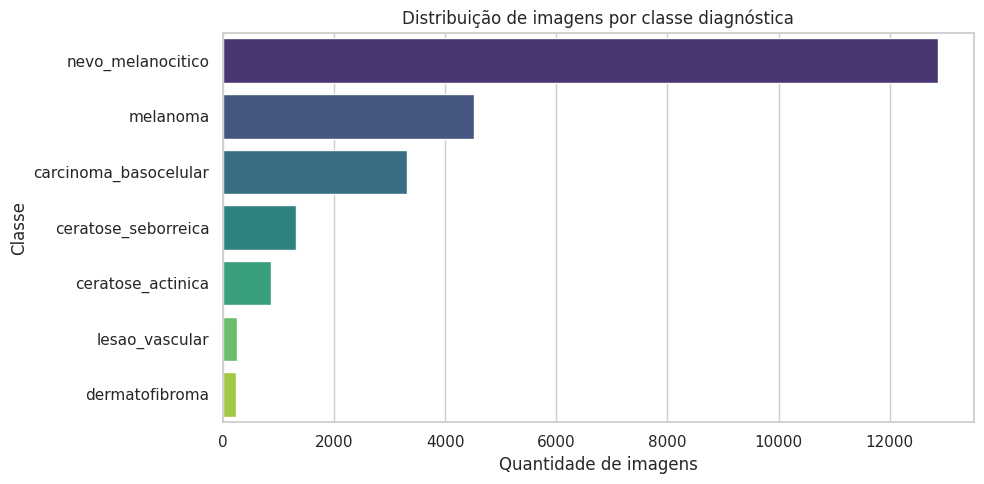


Contagem exata por classe:
classe
nevo_melanocitico        12871
melanoma                  4522
carcinoma_basocelular     3323
ceratose_seborreica       1316
ceratose_actinica          867
lesao_vascular             253
dermatofibroma             239
Name: count, dtype: int64

Proporção (%) por classe:
classe
nevo_melanocitico        55.03
melanoma                 19.33
carcinoma_basocelular    14.21
ceratose_seborreica       5.63
ceratose_actinica         3.71
lesao_vascular            1.08
dermatofibroma            1.02
Name: proportion, dtype: float64


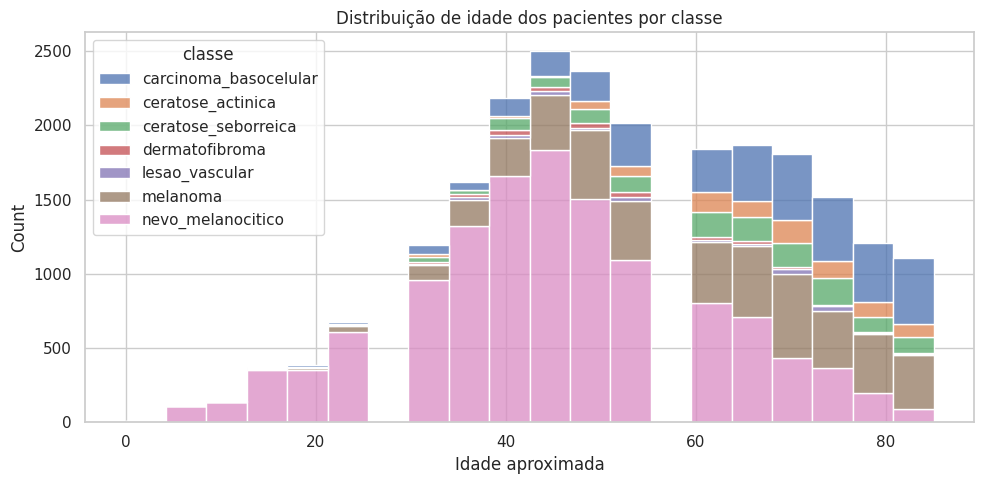


Estatísticas de idade (coluna 'age_approx'):
count    22925.000000
mean        53.069357
std         17.939948
min          0.000000
25%         40.000000
50%         50.000000
75%         65.000000
max         85.000000
Name: age_approx, dtype: float64

Registros sem idade informada: 466 (2.0%)


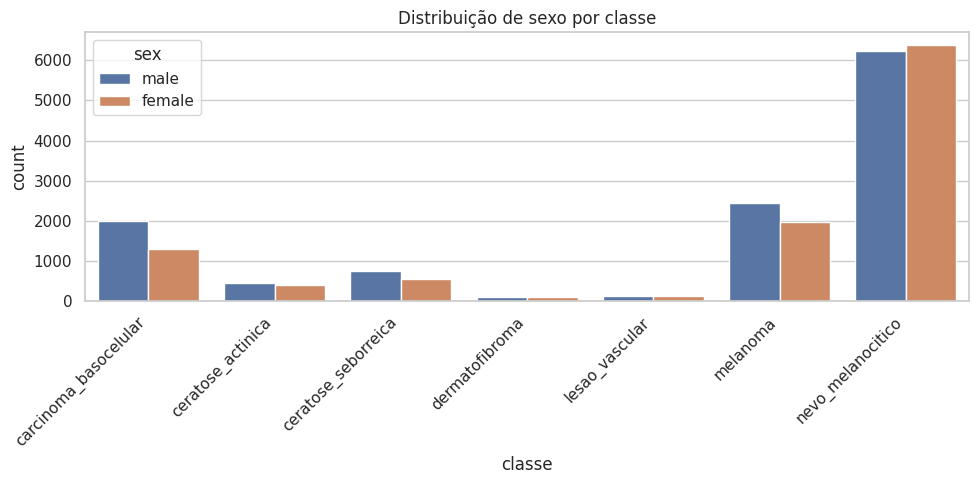


Distribuição geral de sexo (coluna 'sex'):
sex
male      12144
female    10874
NaN         373
Name: count, dtype: int64

Registros sem sexo informado: 373 (1.6%)


/tmp/ipykernel_960/2899018900.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, order=ordem, palette="mako")


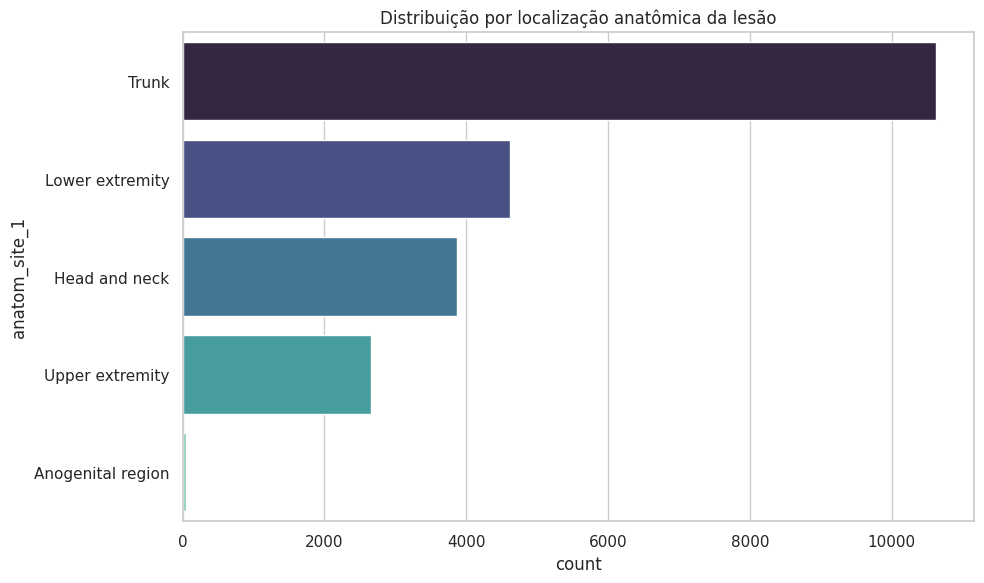

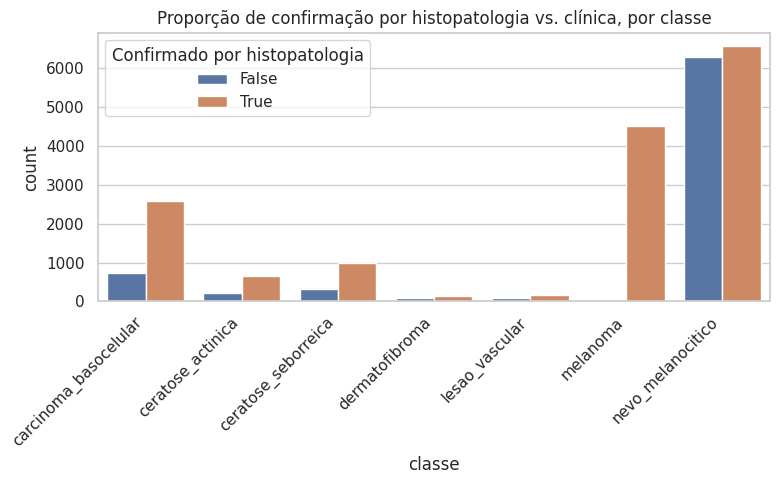


Proporção de confirmação histopatológica por classe (%):
classe
carcinoma_basocelular     78.1
ceratose_actinica         75.7
ceratose_seborreica       74.8
dermatofibroma            61.9
lesao_vascular            62.5
melanoma                 100.0
nevo_melanocitico         51.1
Name: confirmado_histopatologia, dtype: float64

--- Percentual de valores ausentes por coluna ---
anatom_site_5             99.83
anatom_site_4             98.98
diagnosis_5               98.23
patient_id                98.22
family_hx_mm              97.68
clin_size_long_diam_mm    97.64
personal_hx_mm            97.64
anatom_site_special       96.09
diagnosis_4               95.83
dermoscopic_type          93.89
anatom_site_3             88.73
anatom_site_2             52.99
diagnosis_confirm_type     9.92
lesion_id                  7.11
anatom_site_1              6.70
age_approx                 1.99
sex                        1.59
diagnosis_3                1.08
dtype: float64

Dataset limpo salvo em: /co

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("=" * 60)
    print("ETAPA 1: Consolidação dos metadados")
    print("=" * 60)
    df_bruto = consolidar_metadados()

    print("\n" + "=" * 60)
    print("ETAPA 2: Limpeza")
    print("=" * 60)
    df_limpo = limpar_dataset(df_bruto)

    print("\n" + "=" * 60)
    print("ETAPA 3: Análise Exploratória de Dados (EDA)")
    print("=" * 60)
    eda_distribuicao_classes(df_limpo)
    eda_idade(df_limpo)
    eda_sexo(df_limpo)
    eda_localizacao_anatomica(df_limpo)
    eda_confirmacao_diagnostica(df_limpo)
    relatorio_valores_ausentes(df_limpo)

    # Salva o dataset limpo para as próximas etapas (pré-processamento)
    caminho_saida = os.path.join(SAIDA_BASE, "dataset_limpo.csv")
    df_limpo.to_csv(caminho_saida, index=False)
    print(f"\nDataset limpo salvo em: {caminho_saida}")
    print(f"Total final de registros: {len(df_limpo)}")


In [ ]:
# ============================================================
# DOCUMENTAÇÃO DA COMPOSIÇÃO DA BASE EFETIVAMENTE UTILIZADA
# ============================================================
# Esta célula registra quantitativos reais após coleta e limpeza; não presume que a amostra
# obtida pela API equivale à coleção completa ISIC 2019.

def salvar_composicao_base(df, nome_arquivo="composicao_base.csv"):
    colunas = [c for c in ["classe", "diagnosis", "diagnosis_2", "diagnosis_3", "isic_id", "lesion_id", "patient_id"] if c in df.columns]
    resumo = df.groupby("classe", dropna=False).size().rename("n_registros_limpos").reset_index()
    resumo["percentual_base_limpa"] = (100 * resumo["n_registros_limpos"] / max(1, len(df))).round(3)
    resumo.to_csv(os.path.join(SAIDA_BASE, nome_arquivo), index=False)
    print("Total após limpeza:", len(df))
    print(resumo.to_string(index=False))
    print("Classes consultadas pela API (dicionário CLASSES_ISIC):")
    for classe, consulta in CLASSES_ISIC.items():
        print(f"- {classe}: {consulta}")
    print("Observação: para declarar cobertura total/parcial da coleção, compare estes totais com a documentação oficial ISIC 2019 e registre os filtros de consulta.")
    return resumo

if __name__ == "__main__":
    if os.path.exists(os.path.join(SAIDA_BASE, "dataset_limpo.csv")):
        _df_comp = pd.read_csv(os.path.join(SAIDA_BASE, "dataset_limpo.csv"), low_memory=False)
        salvar_composicao_base(_df_comp)
    else:
        print("Execute primeiro a limpeza para gerar dataset_limpo.csv.")


Total após limpeza: 23391
               classe  n_registros_limpos  percentual_base_limpa
carcinoma_basocelular                3323                 14.206
    ceratose_actinica                 867                  3.707
  ceratose_seborreica                1316                  5.626
       dermatofibroma                 239                  1.022
       lesao_vascular                 253                  1.082
             melanoma                4522                 19.332
    nevo_melanocitico               12871                 55.025
Classes consultadas pela API (dicionário CLASSES_ISIC):
- melanoma: diagnosis_2:"Malignant melanocytic proliferations (Melanoma)"
- nevo_melanocitico: diagnosis_3:"Nevus"
- carcinoma_basocelular: diagnosis_3:"Basal cell carcinoma"
- ceratose_actinica: diagnosis_3:"Solar or actinic keratosis"
- ceratose_seborreica: diagnosis_3:"Seborrheic keratosis"
- dermatofibroma: diagnosis_3:"Dermatofibroma"
- lesao_vascular: diagnosis_2:"Benign soft tissue prolif

### Pipeline de pré-processamento (item 3.4/3.5 do TCC):

- Particionamento estratificado em treino/validação/teste, priorizando `lesion_id`.
- Imagens sem `lesion_id` são mantidas como grupos individuais, salvo quando ligadas por duplicidade perceptual.
- Hash MD5 detecta arquivos binariamente idênticos; pHash identifica imagens visualmente semelhantes e impede que pares próximos caiam em conjuntos diferentes.
- DullRazor é aplicado conforme a variante experimental; redimensionamento e normalização são determinísticos.
- Aumento de dados aleatório é aplicado exclusivamente no treinamento; validação e teste não recebem augmentation aleatório.


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
ENTRADA_CSV = "/content/data/processed/dataset_limpo.csv"
SAIDA_BASE = "/content/data/processed"
TAMANHO_IMAGEM = 224

In [ ]:
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# ============================================================
# 1. DULLRAZOR — remoção de pelos e artefatos
# ============================================================
# Parâmetros centralizados (também são registrados no relatório de padronização)
DR_KERNEL = 9
DR_LIMIAR = 10
DR_RAIO_INPAINT = 3
PARAMS_JPEG = [int(cv2.IMWRITE_JPEG_QUALITY), 95]  # qualidade ao salvar (igual ao padrão do cv2)

def mascara_pelos(img_bgr, tamanho_kernel=DR_KERNEL, limiar=DR_LIMIAR):
    """Máscara binária (0/255) das estruturas escuras e finas (pelos), via Black-Hat morfológico."""
    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tamanho_kernel, tamanho_kernel))
    blackhat = cv2.morphologyEx(cinza, cv2.MORPH_BLACKHAT, kernel)
    _, mascara = cv2.threshold(blackhat, limiar, 255, cv2.THRESH_BINARY)
    return mascara

def dullrazor(img_bgr, tamanho_kernel=DR_KERNEL, limiar=DR_LIMIAR):
    """
    Implementação clássica do DullRazor:
    1. Detecta estruturas escuras e finas (pelos) via Black-Hat morfológico.
    2. Binariza a máscara de pelos detectados.
    3. Usa inpainting para reconstruir a região onde havia pelo.
    """
    mascara = mascara_pelos(img_bgr, tamanho_kernel, limiar)
    resultado = cv2.inpaint(img_bgr, mascara, inpaintRadius=DR_RAIO_INPAINT, flags=cv2.INPAINT_TELEA)
    return resultado

def preprocessar_imagem(img_bgr, aplicar_dullrazor=True):
    """
    ÚNICA função de pré-processamento do projeto. Treino, validação e teste passam por ela
    com os mesmos parâmetros (garante filtragem idêntica nos três conjuntos).
      - aplicar_dullrazor=True  -> versão "tratada"  (DullRazor + resize)
      - aplicar_dullrazor=False -> versão "original" (só resize)
    """
    if aplicar_dullrazor:
        img_bgr = dullrazor(img_bgr)
    return cv2.resize(img_bgr, (TAMANHO_IMAGEM, TAMANHO_IMAGEM), interpolation=cv2.INTER_AREA)

In [ ]:
# ============================================================
# 2. SPLIT ESTRATIFICADO POR LESÃO + BLOQUEIO DE DUPLICIDADES PERCEPTUAIS
# ============================================================
# Política metodológica:
# 1) lesion_id é a chave principal de agrupamento (não patient_id).
# 2) Registros sem lesion_id são mantidos; cada um é grupo próprio, exceto se pHash
#    indicar semelhança perceptual com outra imagem, caso em que ambos ficam juntos.
# 3) Imagens com pHash próximo são agrupadas, nunca removidas automaticamente.
# 4) Não usar o conjunto de teste para selecionar hiperparâmetros.
import json

PHASH_DISTANCIA_MAX = 10  # pHash RGB de 192 bits + 15 bits de cor média quantizada (207 bits totais)
DISTANCIA_HIST_COR_MAX = 0.15  # confirmação adicional para evitar unir imagens só por fundo semelhante
ARQUIVO_AUDITORIA_SPLIT = os.path.join(SAIDA_BASE, "split_audit.csv")
ARQUIVO_DUPLICATAS_PERCEPTUAIS = os.path.join(SAIDA_BASE, "perceptual_duplicates.csv")


def calcular_phash(caminho):
    """pHash colorido de 192 bits (DCT por canal RGB) para reduzir colisões em fundos semelhantes."""
    try:
        img = cv2.imread(str(caminho), cv2.IMREAD_COLOR)
        if img is None:
            return None
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        # Assinatura espacial por canal (192 bits).
        reduzida = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        valor = 0
        for canal in range(3):
            dct = cv2.dct(reduzida[:, :, canal])
            bloco = dct[:8, :8].flatten()
            mediana = np.median(bloco[1:])
            for bit in (bloco > mediana):
                valor = (valor << 1) | int(bit)
        # Acrescenta cor média quantizada (15 bits) para distinguir fundos com geometria parecida.
        medias = np.mean(reduzida, axis=(0, 1))
        for media in medias:
            quantizada = int(np.clip(round(float(media) / 255 * 31), 0, 31))
            valor = (valor << 5) | quantizada
        return int(valor)
    except Exception:
        return None


def distancia_histograma_cor(caminho_a, caminho_b):
    """Distância de Bhattacharyya entre histogramas HSV; ajuda a reduzir falsos pares do pHash."""
    try:
        a = cv2.imread(str(caminho_a))
        b = cv2.imread(str(caminho_b))
        if a is None or b is None:
            return 1.0
        a = cv2.cvtColor(cv2.resize(a, (128, 128)), cv2.COLOR_BGR2HSV)
        b = cv2.cvtColor(cv2.resize(b, (128, 128)), cv2.COLOR_BGR2HSV)
        ha = cv2.calcHist([a], [0, 1], None, [16, 8], [0, 180, 0, 256])
        hb = cv2.calcHist([b], [0, 1], None, [16, 8], [0, 180, 0, 256])
        cv2.normalize(ha, ha, alpha=1, norm_type=cv2.NORM_L1)
        cv2.normalize(hb, hb, alpha=1, norm_type=cv2.NORM_L1)
        return float(cv2.compareHist(ha, hb, cv2.HISTCMP_BHATTACHARYYA))
    except Exception:
        return 1.0


def distancia_hamming_hash(a, b):
    return int((int(a) ^ int(b)).bit_count())


class _NoBK:
    def __init__(self, valor, indices):
        self.valor = int(valor)
        self.indices = list(indices)
        self.filhos = {}


class _BKTree:
    """Árvore BK para procurar hashes dentro de uma distância de Hamming."""
    def __init__(self):
        self.raiz = None

    def add(self, valor, indice):
        valor = int(valor)
        if self.raiz is None:
            self.raiz = _NoBK(valor, [indice]); return
        no = self.raiz
        while True:
            d = distancia_hamming_hash(valor, no.valor)
            if d == 0:
                no.indices.append(indice); return
            if d not in no.filhos:
                no.filhos[d] = _NoBK(valor, [indice]); return
            no = no.filhos[d]

    def query(self, valor, raio):
        if self.raiz is None:
            return []
        encontrados, pilha = [], [self.raiz]
        while pilha:
            no = pilha.pop()
            d = distancia_hamming_hash(valor, no.valor)
            if d <= raio:
                encontrados.extend((idx, d, no.valor) for idx in no.indices)
            minimo, maximo = d - raio, d + raio
            pilha.extend(filho for dist, filho in no.filhos.items() if minimo <= dist <= maximo)
        return encontrados


def _split_por_grupos(ids_grupos, classes_grupos):
    """Split 70/15/15 em IDs de grupo; fallback sem estratificação se inviável."""
    ids_grupos = np.asarray(list(ids_grupos), dtype=object)
    classes_grupos = np.asarray(list(classes_grupos), dtype=object)
    estratificar = classes_grupos
    try:
        ids_tr, ids_temp = train_test_split(
            ids_grupos, test_size=(1 - PROPORCAO_TREINO), random_state=SEED,
            stratify=estratificar)
    except ValueError as exc:
        print(f"[AVISO] Estratificação de grupos inviável na primeira divisão ({exc}); usando split aleatório por grupo.")
        ids_tr, ids_temp = train_test_split(
            ids_grupos, test_size=(1 - PROPORCAO_TREINO), random_state=SEED)
    classes_temp_map = dict(zip(ids_grupos.tolist(), classes_grupos.tolist()))
    classes_temp = np.asarray([classes_temp_map[x] for x in ids_temp], dtype=object)
    proporcao_val_no_temp = PROPORCAO_VAL / (PROPORCAO_VAL + PROPORCAO_TESTE)
    try:
        ids_v, ids_te = train_test_split(
            ids_temp, test_size=(1 - proporcao_val_no_temp), random_state=SEED,
            stratify=classes_temp)
    except ValueError as exc:
        print(f"[AVISO] Estratificação de validação/teste inviável ({exc}); usando split aleatório por grupo.")
        ids_v, ids_te = train_test_split(
            ids_temp, test_size=(1 - proporcao_val_no_temp), random_state=SEED)
    return set(ids_tr), set(ids_v), set(ids_te)


def dividir_dataset(df):
    """Split por lesion_id e por componentes de duplicidade perceptual, sem remover imagens semelhantes."""
    df = df.copy().reset_index(drop=True)
    if "classe" not in df.columns:
        raise ValueError("O DataFrame precisa conter a coluna 'classe'.")
    col_img = "caminho_imagem"
    if col_img not in df.columns:
        raise ValueError("O DataFrame precisa conter 'caminho_imagem' para auditar duplicidades perceptuais.")

    # Union-find: une imagens da mesma lesão e imagens perceptualmente próximas.
    pai = list(range(len(df)))
    rank = [0] * len(df)
    def find(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]
            x = pai[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra == rb: return
        if rank[ra] < rank[rb]: ra, rb = rb, ra
        pai[rb] = ra
        if rank[ra] == rank[rb]: rank[ra] += 1

    if "lesion_id" in df.columns:
        lesion = df["lesion_id"].astype("string").str.strip()
        lesion = lesion.mask(lesion.isin(["", "nan", "None", "<NA>"]))
        ids_lesao = {}
        for i, lid in enumerate(lesion.tolist()):
            if pd.notna(lid):
                if lid in ids_lesao: union(i, ids_lesao[lid])
                else: ids_lesao[lid] = i
        n_sem_lesion = int(lesion.isna().sum())
        print(f"Agrupamento primário: lesion_id | registros sem lesion_id: {n_sem_lesion}")
    else:
        print("[AVISO METODOLÓGICO] Coluna lesion_id ausente; cada registro será grupo próprio antes da análise perceptual.")
        n_sem_lesion = len(df)

    print("Calculando pHash das imagens para localizar duplicidades perceptuais...")
    hashes = []
    for caminho in tqdm(df[col_img].tolist(), total=len(df), desc="pHash"):
        hashes.append(calcular_phash(caminho))
    df["phash_64"] = hashes

    arvore = _BKTree()
    pares = []
    n_candidatos_phash = 0
    n_candidatos_rejeitados_cor = 0
    for i, valor in enumerate(hashes):
        if valor is None:
            continue
        for j, dist, hash_anterior in arvore.query(valor, PHASH_DISTANCIA_MAX):
            if j != i:
                n_candidatos_phash += 1
                dist_cor = distancia_histograma_cor(df.iloc[j][col_img], df.iloc[i][col_img])
                mesma_lesao = bool(
                    "lesion_id" in df.columns and pd.notna(df.iloc[j].get("lesion_id"))
                    and str(df.iloc[j].get("lesion_id")) == str(df.iloc[i].get("lesion_id")))
                confirmado = bool(dist_cor <= DISTANCIA_HIST_COR_MAX)
                # Só unir automaticamente quando pHash e cor concordam; todos os candidatos
                # ficam registrados para inspeção manual, mesmo quando não agrupados.
                if confirmado:
                    union(i, j)
                else:
                    n_candidatos_rejeitados_cor += 1
                if confirmado:
                    pares.append({
                    "indice_a": int(j), "indice_b": int(i),
                    "imagem_a": str(df.iloc[j][col_img]), "imagem_b": str(df.iloc[i][col_img]),
                    "isic_id_a": str(df.iloc[j].get("isic_id", "")),
                    "isic_id_b": str(df.iloc[i].get("isic_id", "")),
                    "lesion_id_a": str(df.iloc[j].get("lesion_id", "")),
                    "lesion_id_b": str(df.iloc[i].get("lesion_id", "")),
                    "distancia_hamming": int(dist),
                    "distancia_histograma_cor": float(dist_cor),
                    "agrupado_como_duplicata_perceptual": confirmado,
                    "mesma_lesao_declarada": mesma_lesao
                })
        arvore.add(valor, i)

    df["_grupo_split"] = [f"grp_{find(i)}" for i in range(len(df))]
    # Classe majoritária por componente para estratificação no nível do grupo.
    classes_grupo = df.groupby("_grupo_split")["classe"].agg(
        lambda s: s.value_counts().index[0])
    ids_tr, ids_v, ids_te = _split_por_grupos(classes_grupo.index, classes_grupo.values)
    df_tr = df[df["_grupo_split"].isin(ids_tr)].copy()
    df_v = df[df["_grupo_split"].isin(ids_v)].copy()
    df_te = df[df["_grupo_split"].isin(ids_te)].copy()

    # Auditoria objetiva: nenhum componente (lesão/duplicata perceptual) pode cruzar conjuntos.
    sets = {"treino": set(df_tr["_grupo_split"]), "validacao": set(df_v["_grupo_split"]), "teste": set(df_te["_grupo_split"])}
    assert not (sets["treino"] & sets["validacao"] or sets["treino"] & sets["teste"] or sets["validacao"] & sets["teste"]), "Vazamento: grupo compartilhado entre splits."
    split_por_indice = {}
    for nome_split, frame_split in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        for indice_original in frame_split.index:
            split_por_indice[int(indice_original)] = nome_split
    if "lesion_id" in df.columns:
        mapa_splits_lesao = df.assign(_split_verificacao=[split_por_indice[int(i)] for i in df.index]).dropna(subset=["lesion_id"]).groupby("lesion_id")["_split_verificacao"].nunique()
        ids_lesao_vazados = mapa_splits_lesao[mapa_splits_lesao > 1]
        if len(ids_lesao_vazados):
            raise AssertionError(f"Vazamento de lesion_id entre conjuntos: {ids_lesao_vazados.index.tolist()[:10]}")
    for par in pares:
        par["split_a"] = split_por_indice.get(par["indice_a"], "desconhecido")
        par["split_b"] = split_por_indice.get(par["indice_b"], "desconhecido")
        if par.get("agrupado_como_duplicata_perceptual", False) and par["split_a"] != par["split_b"]:
            raise AssertionError(f"Duplicidade perceptual confirmada atravessou splits: {par}")
    for nome, frame in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        print(f"{nome}: {len(frame)} imagens | {frame['_grupo_split'].nunique()} grupos | classes={frame['classe'].value_counts().to_dict()}")

    auditoria = []
    for nome, frame in [("treino", df_tr), ("validacao", df_v), ("teste", df_te)]:
        auditoria.append({
            "split": nome, "n_imagens": len(frame), "n_grupos_sem_vazamento": frame["_grupo_split"].nunique(),
            "n_lesion_id_preenchidos": int(frame["lesion_id"].notna().sum()) if "lesion_id" in frame else 0,
            "n_sem_lesion_id": int(frame["lesion_id"].isna().sum()) if "lesion_id" in frame else len(frame),
            "n_hashes_phash_indisponiveis": int(frame["phash_64"].isna().sum()),
            "distribuicao_classes": json.dumps(frame["classe"].value_counts().to_dict(), ensure_ascii=False)
        })
    pd.DataFrame(auditoria).to_csv(ARQUIVO_AUDITORIA_SPLIT, index=False)
    pd.DataFrame(pares, columns=["indice_a", "indice_b", "imagem_a", "imagem_b", "isic_id_a", "isic_id_b",
        "lesion_id_a", "lesion_id_b", "distancia_hamming", "distancia_histograma_cor",
        "agrupado_como_duplicata_perceptual", "mesma_lesao_declarada", "split_a", "split_b"]).to_csv(
        ARQUIVO_DUPLICATAS_PERCEPTUAIS, index=False)
    config_split = {
        "seed": SEED, "proporcoes_alvo": {"treino": PROPORCAO_TREINO, "validacao": PROPORCAO_VAL, "teste": PROPORCAO_TESTE},
        "agrupamento_primario": "lesion_id", "sem_lesion_id": "grupo individual, exceto união por duplicidade perceptual",
        "metodo_duplicidade_perceptual": "pHash DCT 64-bit + árvore BK + distância de Hamming e distância de histograma HSV",
        "limiar_hamming_candidato": PHASH_DISTANCIA_MAX,
        "limiar_distancia_histograma_cor_confirmacao": DISTANCIA_HIST_COR_MAX, "n_pares_perceptuais_sinalizados": len(pares),
        "pares_perceptuais_nao_removidos": True,
        "arquivos_auditoria": [ARQUIVO_AUDITORIA_SPLIT, ARQUIVO_DUPLICATAS_PERCEPTUAIS]
    }
    with open(os.path.join(SAIDA_BASE, "split_config.json"), "w", encoding="utf-8") as f:
        json.dump(config_split, f, indent=2, ensure_ascii=False)

    # Colunas auxiliares são removidas antes do pipeline já existente; não alteramos seu formato.
    for frame in (df_tr, df_v, df_te):
        frame.drop(columns=["_grupo_split", "phash_64"], inplace=True, errors="ignore")
    print(f"Candidatos pHash avaliados: {n_candidatos_phash} | rejeitados pelo histograma de cor: {n_candidatos_rejeitados_cor}")
    print(f"Pares perceptuais confirmados e agrupados (não removidos): {len(pares)}")
    print(f"Auditoria salva em: {ARQUIVO_AUDITORIA_SPLIT}")
    print(f"Pares perceptuais salvos em: {ARQUIVO_DUPLICATAS_PERCEPTUAIS}")
    return df_tr, df_v, df_te


In [ ]:
# ============================================================
# 3. PROCESSAMENTO E SALVAMENTO EM DISCO
# ============================================================
def processar_e_salvar(df_split, nome_split, aplicar_dullrazor=True, subpasta=""):
    """
    Aplica preprocessar_imagem (DullRazor + resize) em cada imagem do split e salva em
    /content/data/processed/[subpasta/]{split}/{classe}/{isic_id}.jpg
    Retorna um DataFrame com o novo caminho de cada imagem processada.

    A mesma função é usada para treino, validação e teste (filtragem idêntica).
    aplicar_dullrazor=False gera a versão "sem DullRazor" (só redimensionada) usada no teste A/B.
    """
    linhas_saida = []
    falhas = []

    for _, row in tqdm(df_split.iterrows(), total=len(df_split), desc=f"Processando {nome_split}"):
        caminho_origem = row["caminho_imagem"]
        classe = row["classe"]

        pasta_destino = os.path.join(SAIDA_BASE, subpasta, nome_split, classe)
        os.makedirs(pasta_destino, exist_ok=True)

        nome_arquivo = os.path.basename(caminho_origem)
        caminho_destino = os.path.join(pasta_destino, nome_arquivo)

        # Evita reprocessar se já existir (retomada após interrupção)
        if os.path.exists(caminho_destino):
            linhas_saida.append({**row.to_dict(), "caminho_processado": caminho_destino})
            continue

        try:
            img = cv2.imread(caminho_origem)
            if img is None:
                raise ValueError("cv2.imread retornou None")

            img = preprocessar_imagem(img, aplicar_dullrazor=aplicar_dullrazor)

            cv2.imwrite(caminho_destino, img, PARAMS_JPEG)
            linhas_saida.append({**row.to_dict(), "caminho_processado": caminho_destino})
        except Exception as e:
            falhas.append((caminho_origem, str(e)))

    if falhas:
        print(f"\n[AVISO] {len(falhas)} imagens falharam no processamento em '{nome_split}':")
        for caminho, erro in falhas[:10]:
            print(f"  - {caminho}: {erro}")
        if len(falhas) > 10:
            print(f"  ... e mais {len(falhas) - 10}")

    return pd.DataFrame(linhas_saida)

In [ ]:
# ============================================================
# 4. VISUALIZAÇÃO RÁPIDA (antes/depois do DullRazor)
# ============================================================
def visualizar_exemplo_dullrazor(df, indice=0):
    """Gera uma imagem lado a lado (original vs. processada) para conferência visual."""
    import matplotlib.pyplot as plt

    linha = df.iloc[indice]
    img_original = cv2.imread(linha["caminho_imagem"])

    # Mesma função usada no processamento em disco (mesmo resize, mesma interpolação)
    img_original_rgb = cv2.cvtColor(
        preprocessar_imagem(img_original, aplicar_dullrazor=False), cv2.COLOR_BGR2RGB)
    img_processada_rgb = cv2.cvtColor(
        preprocessar_imagem(img_original, aplicar_dullrazor=True), cv2.COLOR_BGR2RGB)

    fig, eixos = plt.subplots(1, 2, figsize=(10, 5))
    eixos[0].imshow(img_original_rgb)
    eixos[0].set_title("Original (redimensionada)")
    eixos[0].axis("off")

    eixos[1].imshow(img_processada_rgb)
    eixos[1].set_title("Após DullRazor + Resize")
    eixos[1].axis("off")

    plt.tight_layout()
    caminho_saida = os.path.join(SAIDA_BASE, "exemplo_dullrazor.png")
    plt.savefig(caminho_saida, dpi=150)
    plt.show()
    print(f"Exemplo salvo em: {caminho_saida}")

Carregando dataset limpo
Total de registros: 23391

Exemplo visual do DullRazor (conferência antes de processar tudo)


/tmp/ipykernel_960/4231681256.py:8: DtypeWarning: Columns (21,22,24,25,26,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ENTRADA_CSV)


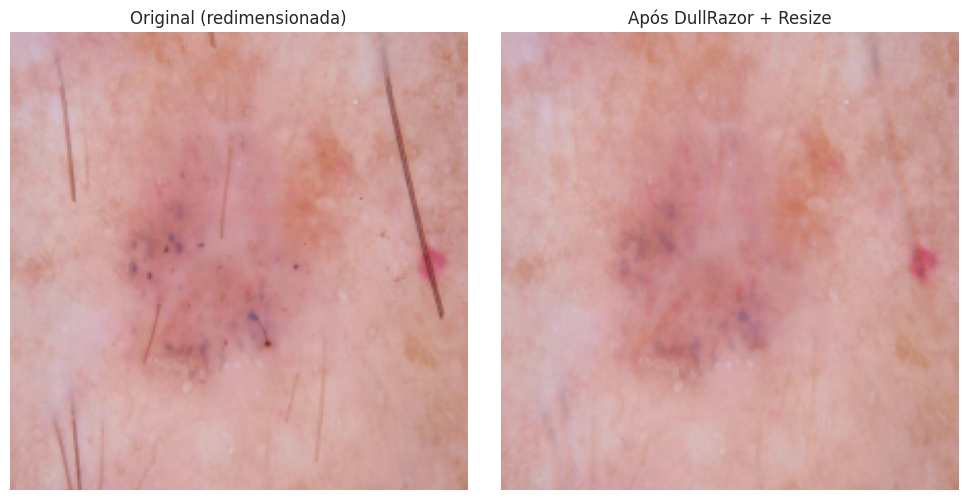

Exemplo salvo em: /content/data/processed/exemplo_dullrazor.png

Dividindo em treino / validação / teste
Agrupamento primário: lesion_id | registros sem lesion_id: 1663
Calculando pHash das imagens para localizar duplicidades perceptuais...


pHash: 100%|██████████| 23391/23391 [05:40<00:00, 68.78it/s] 


treino: 16447 imagens | 9011 grupos | classes={'nevo_melanocitico': 9012, 'melanoma': 3245, 'carcinoma_basocelular': 2286, 'ceratose_seborreica': 948, 'ceratose_actinica': 611, 'dermatofibroma': 177, 'lesao_vascular': 168}
validacao: 3538 imagens | 1931 grupos | classes={'nevo_melanocitico': 1956, 'melanoma': 670, 'carcinoma_basocelular': 538, 'ceratose_seborreica': 171, 'ceratose_actinica': 130, 'lesao_vascular': 40, 'dermatofibroma': 33}
teste: 3406 imagens | 1931 grupos | classes={'nevo_melanocitico': 1903, 'melanoma': 607, 'carcinoma_basocelular': 499, 'ceratose_seborreica': 197, 'ceratose_actinica': 126, 'lesao_vascular': 45, 'dermatofibroma': 29}
Candidatos pHash avaliados: 190 | rejeitados pelo histograma de cor: 27
Pares perceptuais confirmados e agrupados (não removidos): 163
Auditoria salva em: /content/data/processed/split_audit.csv
Pares perceptuais salvos em: /content/data/processed/perceptual_duplicates.csv

Processando e salvando imagens (DullRazor + resize)


Processando test: 100%|██████████| 3406/3406 [08:21<00:00,  6.79it/s]



CONCLUÍDO
Treino: 16447 imagens processadas
Validação: 3538 imagens processadas
Teste: 3406 imagens processadas

Distribuição de classes no treino:
classe
nevo_melanocitico        9012
melanoma                 3245
carcinoma_basocelular    2286
ceratose_seborreica       948
ceratose_actinica         611
dermatofibroma            177
lesao_vascular            168
Name: count, dtype: int64


In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("=" * 60)
    print("Carregando dataset limpo")
    print("=" * 60)
    df = pd.read_csv(ENTRADA_CSV)
    print(f"Total de registros: {len(df)}")

    print("\n" + "=" * 60)
    print("Exemplo visual do DullRazor (conferência antes de processar tudo)")
    print("=" * 60)
    visualizar_exemplo_dullrazor(df, indice=0)

    print("\n" + "=" * 60)
    print("Dividindo em treino / validação / teste")
    print("=" * 60)
    df_treino, df_val, df_teste = dividir_dataset(df)

    print("\n" + "=" * 60)
    print("Processando e salvando imagens (DullRazor + resize)")
    print("=" * 60)
    df_treino_proc = processar_e_salvar(df_treino, "train")
    df_val_proc = processar_e_salvar(df_val, "val")
    df_teste_proc = processar_e_salvar(df_teste, "test")

    # Salva os CSVs finais de cada split — serão a entrada do DataLoader
    df_treino_proc.to_csv(os.path.join(SAIDA_BASE, "train.csv"), index=False)
    df_val_proc.to_csv(os.path.join(SAIDA_BASE, "val.csv"), index=False)
    df_teste_proc.to_csv(os.path.join(SAIDA_BASE, "test.csv"), index=False)

    print("\n" + "=" * 60)
    print("CONCLUÍDO")
    print("=" * 60)
    print(f"Treino: {len(df_treino_proc)} imagens processadas")
    print(f"Validação: {len(df_val_proc)} imagens processadas")
    print(f"Teste: {len(df_teste_proc)} imagens processadas")
    print(f"\nDistribuição de classes no treino:")
    print(df_treino_proc["classe"].value_counts())

### Pré-processamento — versões com/sem DullRazor, figuras e padronização (acréscimos)

Esta seção acrescenta, sem alterar o que já existia:

1. **Versão "sem DullRazor"** das mesmas imagens e do **mesmo split** (só redimensionadas), usada no teste A/B de remoção de pelos.
2. **Figuras antes/depois** do pré-processamento em treino, validação e teste.
3. **Análise de artefatos**: quanto do pixel é alterado pelo DullRazor, por classe, e se a alteração se concentra no centro da imagem (onde fica a lesão).
4. **Verificação de padronização**: prova que a filtragem é idêntica nos três conjuntos e salva o `pipeline_config.json`.

In [ ]:
# ============================================================
# VERSÃO "SEM DULLRAZOR" — imagens originais, apenas redimensionadas
# Usa exatamente os mesmos registros/split de train.csv, val.csv e test.csv
# ============================================================
SUBPASTA_SEM_DR = "sem_dullrazor"

def gerar_dataset_sem_dullrazor():
    col_id = None
    for split in ["train", "val", "test"]:
        df_split = pd.read_csv(os.path.join(SAIDA_BASE, f"{split}.csv"), low_memory=False)
        col_id = col_id or identificar_coluna_id(df_split)

        df_origem = df_split.drop(columns=["caminho_processado"])
        df_proc = processar_e_salvar(df_origem, split, aplicar_dullrazor=False,
                                     subpasta=SUBPASTA_SEM_DR)
        df_proc.to_csv(os.path.join(SAIDA_BASE, f"{split}_{SUBPASTA_SEM_DR}.csv"), index=False)

        mesmo_split = set(df_proc[col_id]) == set(df_split[col_id])
        print(f"[{split}] {len(df_proc)} imagens sem DullRazor | "
              f"mesmo conjunto de imagens que a versão com DullRazor: "
              f"{'SIM' if mesmo_split else 'NÃO (verifique falhas acima)'}")

if __name__ == "__main__":
    gerar_dataset_sem_dullrazor()

Processando train: 100%|██████████| 16447/16447 [04:20<00:00, 63.19it/s] 


[train] 16447 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


Processando val: 100%|██████████| 3538/3538 [00:57<00:00, 61.32it/s] 


[val] 3538 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


Processando test: 100%|██████████| 3406/3406 [00:57<00:00, 59.15it/s] 


[test] 3406 imagens sem DullRazor | mesmo conjunto de imagens que a versão com DullRazor: SIM


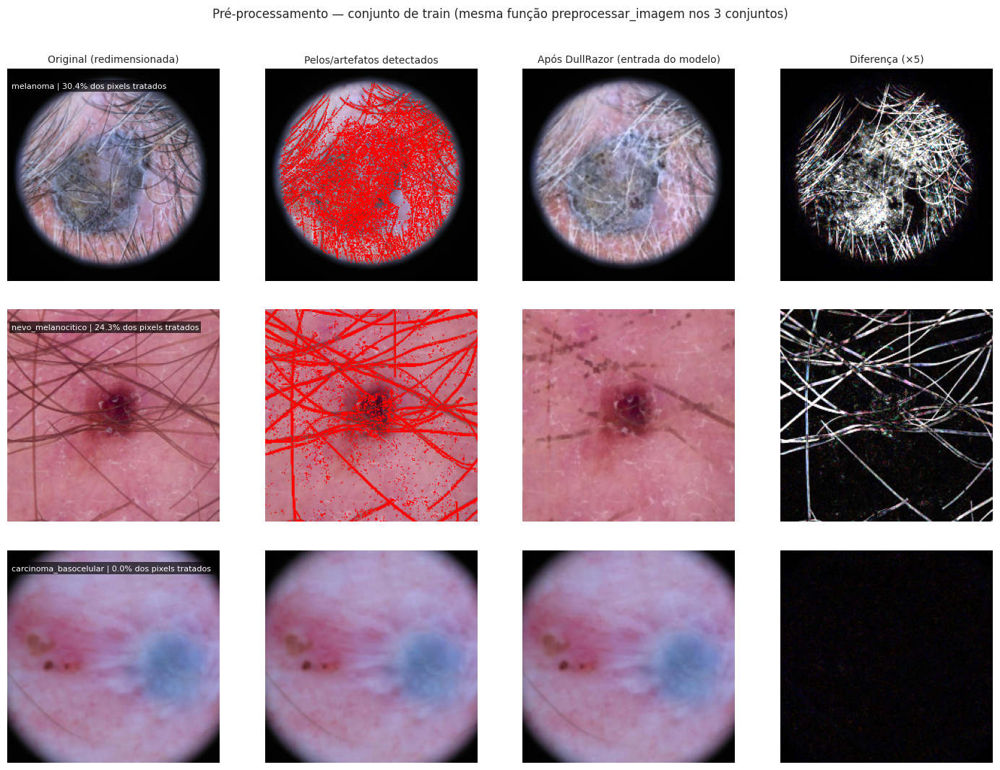

Figura salva em: /content/data/processed/figura_preprocessamento_train.png


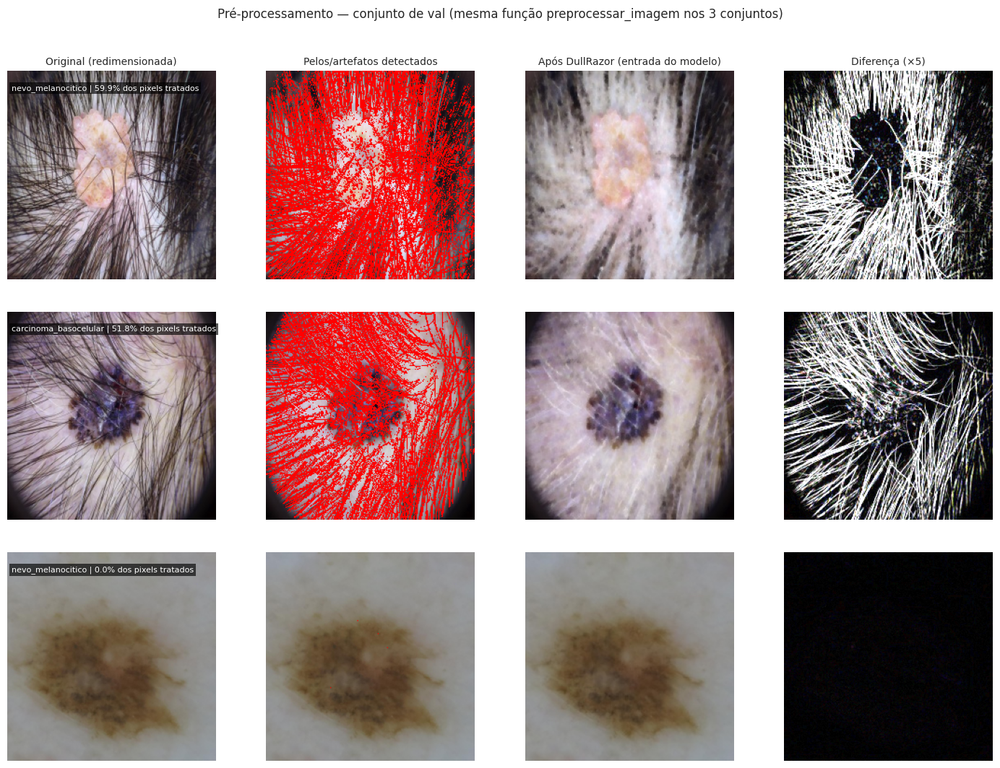

Figura salva em: /content/data/processed/figura_preprocessamento_val.png


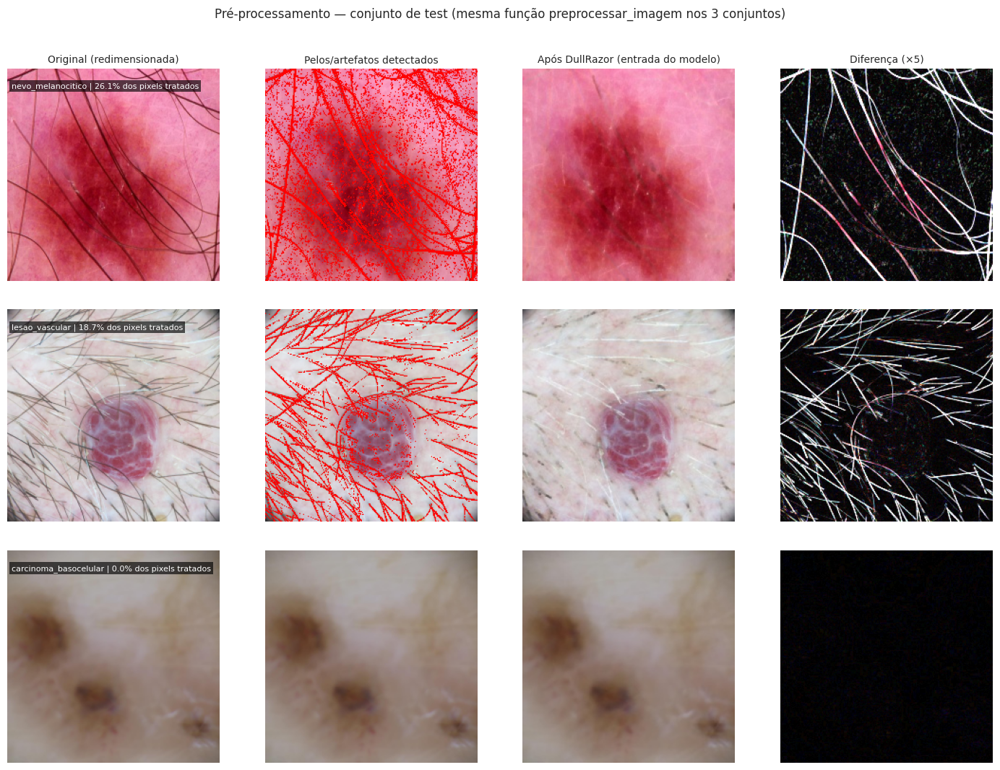

Figura salva em: /content/data/processed/figura_preprocessamento_test.png


In [ ]:
# ============================================================
# FIGURAS DE PRÉ-PROCESSAMENTO (antes/depois) — TREINO, VALIDAÇÃO E TESTE
# ============================================================
N_AMOSTRA_PELOS = 300   # imagens por split para medir a fração de pixels tratados

def calcular_fracao_pelos(df_split, n=N_AMOSTRA_PELOS, seed=SEED):
    """Mede, na imagem ORIGINAL, que fração dos pixels o DullRazor marca como pelo/artefato
    (total, região central e periferia). Só calcula a máscara (rápido), sem inpainting."""
    amostra = df_split.sample(n=min(n, len(df_split)), random_state=seed).copy()
    total, centro_l, borda_l = [], [], []
    for caminho in tqdm(amostra["caminho_imagem"], desc="Máscara de pelos", leave=False):
        img = cv2.imread(caminho)
        if img is None:
            total.append(np.nan); centro_l.append(np.nan); borda_l.append(np.nan)
            continue
        m = mascara_pelos(img) > 0
        h, w = m.shape
        centro = np.zeros_like(m)
        centro[h // 4: 3 * h // 4, w // 4: 3 * w // 4] = True
        total.append(m.mean())
        centro_l.append(m[centro].mean())
        borda_l.append(m[~centro].mean())
    amostra["frac_mascara"] = total
    amostra["frac_centro"] = centro_l
    amostra["frac_borda"] = borda_l
    return amostra.dropna(subset=["frac_mascara"])


def figura_antes_depois(amostra, nome_split, n_com_pelos=2, n_sem_pelos=1):
    """Linhas = exemplos (os mais e o menos afetados pelo DullRazor no split).
    Colunas = original | pelos detectados | após DullRazor (o que entra no modelo) | diferença."""
    ordenado = amostra.sort_values("frac_mascara", ascending=False)
    escolhidas = pd.concat([ordenado.head(n_com_pelos), ordenado.tail(n_sem_pelos)])

    fig, eixos = plt.subplots(len(escolhidas), 4, figsize=(14, 3.6 * len(escolhidas)))
    titulos = ["Original (redimensionada)", "Pelos/artefatos detectados",
               "Após DullRazor (entrada do modelo)", "Diferença (×5)"]

    for i, (_, r) in enumerate(escolhidas.iterrows()):
        img = cv2.imread(r["caminho_imagem"])
        original = preprocessar_imagem(img, aplicar_dullrazor=False)
        mascara = cv2.resize(mascara_pelos(img), (TAMANHO_IMAGEM, TAMANHO_IMAGEM),
                             interpolation=cv2.INTER_NEAREST) > 0
        tratada = cv2.imread(r["caminho_processado"])   # exatamente o arquivo usado no treino/teste

        sobreposta = original.copy()
        sobreposta[mascara] = (0, 0, 255)   # BGR: vermelho
        diferenca = np.clip(cv2.absdiff(original, tratada).astype(np.int32) * 5, 0, 255).astype(np.uint8)

        for j, im in enumerate([original, sobreposta, tratada, diferenca]):
            eixos[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            eixos[i, j].axis("off")
            if i == 0:
                eixos[i, j].set_title(titulos[j], fontsize=10)
        eixos[i, 0].text(4, 14, f"{r['classe']} | {r['frac_mascara']:.1%} dos pixels tratados",
                         fontsize=8, color="white", va="top",
                         bbox=dict(facecolor="black", alpha=0.65, pad=2, edgecolor="none"))

    fig.suptitle(f"Pré-processamento — conjunto de {nome_split} "
                 f"(mesma função preprocessar_imagem nos 3 conjuntos)", fontsize=12, y=1.0)
    plt.tight_layout()
    caminho = os.path.join(SAIDA_BASE, f"figura_preprocessamento_{nome_split}.png")
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figura salva em: {caminho}")


AMOSTRAS_PELOS = {}
if __name__ == "__main__":
    for nome_split in ["train", "val", "test"]:
        df_s = pd.read_csv(os.path.join(SAIDA_BASE, f"{nome_split}.csv"), low_memory=False)
        AMOSTRAS_PELOS[nome_split] = calcular_fracao_pelos(df_s)
        figura_antes_depois(AMOSTRAS_PELOS[nome_split], nome_split)

--- Pixels tratados pelo DullRazor, por classe (amostra) ---
                         n  pct_pixels_media  pct_pixels_mediana  pct_imgs_acima_5pct  razao_centro_borda_mediana
classe                                                                                                           
carcinoma_basocelular  165              2.55                0.89                13.33                        3.45
ceratose_actinica       29              1.74                1.01                 6.90                        3.89
ceratose_seborreica     47              3.55                0.96                21.28                        2.87
dermatofibroma          13              1.72                1.10                 7.69                        3.67
lesao_vascular          12              3.28                0.74                25.00                        5.10
melanoma               160              3.56                1.94                23.75                        3.46
nevo_melanocitico      474 

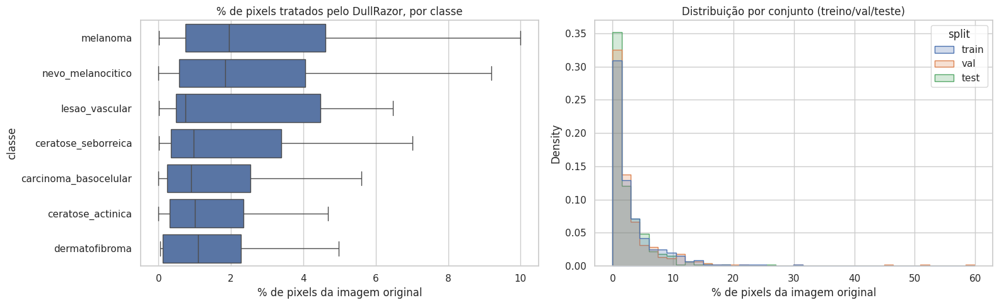


Como interpretar:
 - Se a razão centro/borda for >> 1, o DullRazor está mexendo mais no centro (onde fica a lesão)
   do que na periferia: sinal de que pode estar apagando estruturas da própria lesão
   (rede pigmentar, pontos/glóbulos) em vez de apenas pelos.
 - Classes com muito mais pixels tratados (ex.: melanoma/nevo, lesões escuras) merecem atenção.
 - O efeito real sobre o desempenho é medido no Teste A/B (com x sem DullRazor), adiante.


In [ ]:
# ============================================================
# ANÁLISE DE ARTEFATOS DO DULLRAZOR — ele altera sinais da lesão?
# ============================================================
def analisar_artefatos_dullrazor(amostras):
    df = pd.concat([a.assign(split=s) for s, a in amostras.items()], ignore_index=True)
    df["pct_pixels_tratados"] = df["frac_mascara"] * 100
    df["razao_centro_borda"] = df["frac_centro"] / (df["frac_borda"] + 1e-9)

    por_classe = df.groupby("classe").agg(
        n=("frac_mascara", "size"),
        pct_pixels_media=("pct_pixels_tratados", "mean"),
        pct_pixels_mediana=("pct_pixels_tratados", "median"),
        pct_imgs_acima_5pct=("pct_pixels_tratados", lambda x: (x > 5).mean() * 100),
        razao_centro_borda_mediana=("razao_centro_borda", "median"),
    ).round(2)
    print("--- Pixels tratados pelo DullRazor, por classe (amostra) ---")
    print(por_classe.to_string())

    por_split = df.groupby("split").agg(
        n=("frac_mascara", "size"),
        pct_pixels_media=("pct_pixels_tratados", "mean"),
        pct_pixels_mediana=("pct_pixels_tratados", "median"),
    ).round(2)
    print("\n--- Mesma distribuição nos três conjuntos? (padronização) ---")
    print(por_split.to_string())

    fig, eixos = plt.subplots(1, 2, figsize=(16, 5))
    sns.boxplot(data=df, y="classe", x="pct_pixels_tratados", ax=eixos[0], showfliers=False)
    eixos[0].set_title("% de pixels tratados pelo DullRazor, por classe")
    eixos[0].set_xlabel("% de pixels da imagem original")
    sns.histplot(data=df, x="pct_pixels_tratados", hue="split", bins=40,
                 stat="density", common_norm=False, element="step", ax=eixos[1])
    eixos[1].set_title("Distribuição por conjunto (treino/val/teste)")
    eixos[1].set_xlabel("% de pixels da imagem original")
    plt.tight_layout()
    caminho = os.path.join(SAIDA_BASE, "analise_artefatos_dullrazor.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    por_classe.to_csv(os.path.join(SAIDA_BASE, "analise_artefatos_dullrazor_por_classe.csv"))

    print("\nComo interpretar:")
    print(" - Se a razão centro/borda for >> 1, o DullRazor está mexendo mais no centro (onde fica a lesão)")
    print("   do que na periferia: sinal de que pode estar apagando estruturas da própria lesão")
    print("   (rede pigmentar, pontos/glóbulos) em vez de apenas pelos.")
    print(" - Classes com muito mais pixels tratados (ex.: melanoma/nevo, lesões escuras) merecem atenção.")
    print(" - O efeito real sobre o desempenho é medido no Teste A/B (com x sem DullRazor), adiante.")
    return por_classe, por_split

if __name__ == "__main__":
    if AMOSTRAS_PELOS:
        analisar_artefatos_dullrazor(AMOSTRAS_PELOS)
    else:
        print("[AVISO] Rode antes a célula das figuras de pré-processamento (AMOSTRAS_PELOS vazio).")

In [ ]:
import json

# ============================================================
# VERIFICAÇÃO DE PADRONIZAÇÃO — mesma filtragem em treino, validação e teste
# ============================================================
def verificar_padronizacao(n_por_split=15):
    """Reaplica preprocessar_imagem a uma amostra de cada conjunto e confere, pixel a pixel,
    se o arquivo salvo em disco é exatamente o resultado esperado (prova de que o pipeline
    é determinístico e idêntico nos três conjuntos)."""
    registros = []
    variantes = [("com_dullrazor", True, ""), ("sem_dullrazor", False, f"_{SUBPASTA_SEM_DR}")]
    for nome_versao, aplicar, sufixo in variantes:
        for split in ["train", "val", "test"]:
            caminho_csv = os.path.join(SAIDA_BASE, f"{split}{sufixo}.csv")
            if not os.path.exists(caminho_csv):
                continue
            df = pd.read_csv(caminho_csv, low_memory=False)
            amostra = df.sample(n=min(n_por_split, len(df)), random_state=SEED)
            iguais = 0
            for _, r in amostra.iterrows():
                esperado = preprocessar_imagem(cv2.imread(r["caminho_imagem"]), aplicar_dullrazor=aplicar)
                # o arquivo em disco passou por compressão JPEG: aplica a mesma compressão ao esperado
                esperado = cv2.imdecode(cv2.imencode(".jpg", esperado, PARAMS_JPEG)[1], cv2.IMREAD_COLOR)
                salvo = cv2.imread(r["caminho_processado"])
                iguais += int(salvo is not None and np.array_equal(esperado, salvo))
            registros.append({
                "versao": nome_versao, "conjunto": split, "n_imagens": len(df),
                "verificadas": len(amostra), "identicas_ao_pipeline": iguais,
            })

    df_verif = pd.DataFrame(registros)
    print(df_verif.to_string(index=False))

    config = {
        "funcao_unica": "preprocessar_imagem(img, aplicar_dullrazor)",
        "aplicado_em": ["train", "val", "test"],
        "dullrazor": {"kernel_blackhat": DR_KERNEL, "limiar_binarizacao": DR_LIMIAR,
                      "inpaint_raio": DR_RAIO_INPAINT, "inpaint_metodo": "TELEA"},
        "resize": {"tamanho": TAMANHO_IMAGEM, "interpolacao": "INTER_AREA"},
        "jpeg_qualidade": PARAMS_JPEG[1],
        "split": {"seed": SEED, "treino": PROPORCAO_TREINO, "val": PROPORCAO_VAL,
                  "teste": PROPORCAO_TESTE, "inclui_sem_lesion_id": INCLUIR_SEM_LESION_ID,
                  "agrupamento_primario": "lesion_id",
                  "duplicidade_perceptual": "pHash DCT 64-bit, distância de Hamming <= PHASH_DISTANCIA_MAX; grupos unidos, não removidos"},
        "normalizacao_e_augmentation": "feitas dinamicamente no DataLoader (não no disco): "
                                       "eval_transform (val/teste) = só normalização ImageNet; "
                                       "augmentation apenas no treino",
        "verificacao_pixel_a_pixel": df_verif.to_dict(orient="records"),
    }
    caminho = os.path.join(SAIDA_BASE, "pipeline_config.json")
    with open(caminho, "w") as f:
        json.dump(config, f, indent=2, ensure_ascii=False, default=int)

    todas_ok = bool((df_verif["verificadas"] == df_verif["identicas_ao_pipeline"]).all()) if len(df_verif) else False
    print("\nREGISTRO PARA O TCC:")
    print(f"  A filtragem (DullRazor: kernel {DR_KERNEL}x{DR_KERNEL}, limiar {DR_LIMIAR}, inpainting TELEA raio {DR_RAIO_INPAINT}; "
          f"resize {TAMANHO_IMAGEM}x{TAMANHO_IMAGEM}, INTER_AREA) é aplicada pela mesma função e com os mesmos")
    print("  parâmetros em treino, validação e teste. Normalização e augmentation não são gravados em disco.")
    print(f"  Verificação pixel a pixel: {'APROVADA' if todas_ok else 'REVISAR (há divergências na tabela)'}.")
    print(f"  Configuração salva em: {caminho}")
    return df_verif

if __name__ == "__main__":
    verificar_padronizacao()

       versao conjunto  n_imagens  verificadas  identicas_ao_pipeline
com_dullrazor    train      16447           15                     15
com_dullrazor      val       3538           15                     15
com_dullrazor     test       3406           15                     15
sem_dullrazor    train      16447           15                     15
sem_dullrazor      val       3538           15                     15
sem_dullrazor     test       3406           15                     15

REGISTRO PARA O TCC:
  A filtragem (DullRazor: kernel 9x9, limiar 10, inpainting TELEA raio 3; resize 224x224, INTER_AREA) é aplicada pela mesma função e com os mesmos
  parâmetros em treino, validação e teste. Normalização e augmentation não são gravados em disco.
  Verificação pixel a pixel: APROVADA.
  Configuração salva em: /content/data/processed/pipeline_config.json


### Dataset PyTorch

Dataset PyTorch para carregar as imagens já pré-processadas (DullRazor + resize,
feitos em preprocessamento.py) e aplicar, dinamicamente a cada carregamento:
  - Normalização com média/desvio-padrão do ImageNet
  - Data augmentation (apenas no split de treino)

Uso típico:
    from dataset_pytorch import criar_dataloaders
    train_loader, val_loader, test_loader, mapa_classes = criar_dataloaders()

In [ ]:
import pandas as pd
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
SAIDA_BASE = "/content/data/processed"
MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
BATCH_SIZE = 32
NUM_WORKERS = 2   # o Colab tem 2 CPUs; mais workers que isso só atrapalha (ver aviso do DataLoader)

# Modo de teste rápido (opcional): use p.ex. 0.05 para treinar/avaliar com ~5% das imagens
# e conferir se o notebook inteiro roda, antes de gastar horas de GPU. None = usa tudo.
FRACAO_DADOS_DEBUG = None

In [ ]:
# ============================================================
# TRANSFORMS
# ============================================================
# ATENÇÃO (teste de cor): o ColorJitter do Albumentations, quando 'hue' não é informado, aplica
# uma rotação de MATIZ por padrão (nas versões 2.x: até ±0.5 do círculo cromático, i.e. qualquer cor).
# Isso muda a cor da lesão — um sinal clínico central (critério "C" do ABCDE) — em metade das imagens.
# Esta é a configuração da versão anterior e é mantida como variante "original" para comparação.
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# Val/teste: SEM augmentation aleatório — só normalização, para avaliação justa e reprodutível
eval_transform = A.Compose([
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# ------------------------------------------------------------
# Variantes de augmentation de COR (usadas no "Teste de alterações de cor")
#   "original"         -> a configuração acima (brilho, contraste, saturação E matiz padrão do Albumentations)
#   "brilho_contraste" -> só brilho e contraste (±20%); saturação e matiz FIXOS (cor da lesão preservada)
#   "sem_cor"          -> nenhuma alteração de cor (só flips/rotações/escala)
# ------------------------------------------------------------
def construir_train_transform(variante_cor="original"):
    if variante_cor == "original":
        return train_transform
    if variante_cor == "brilho_contraste":
        cor = [A.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                             saturation=(1.0, 1.0), hue=(0.0, 0.0), p=0.5)]
    elif variante_cor == "sem_cor":
        cor = []
    else:
        raise ValueError(f"Variante de cor desconhecida: {variante_cor}")
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        *cor,
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
        A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
        ToTensorV2(),
    ])

TRAIN_TRANSFORMS = {v: construir_train_transform(v)
                    for v in ["original", "brilho_contraste", "sem_cor"]}

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# ============================================================
# DATASET
# ============================================================
from PIL import Image, ImageEnhance

def aplicar_perturbacao_cor(img_rgb, brilho=0.0, contraste=0.0, saturacao=0.0, matiz=0.0):
    """Perturbação DETERMINÍSTICA de cor (usada só na avaliação de robustez, nunca no treino).
    brilho/contraste/saturacao: variação relativa (0.2 = +20%, -0.2 = -20%).
    matiz: fração do círculo cromático (0.1 = 36 graus)."""
    pil = Image.fromarray(img_rgb)
    if brilho:
        pil = ImageEnhance.Brightness(pil).enhance(1.0 + brilho)
    if contraste:
        pil = ImageEnhance.Contrast(pil).enhance(1.0 + contraste)
    if saturacao:
        pil = ImageEnhance.Color(pil).enhance(1.0 + saturacao)
    if matiz:
        h, s, v = pil.convert("HSV").split()
        deslocamento = int(round(matiz * 255))
        h = h.point(lambda x: (x + deslocamento) % 256)
        pil = Image.merge("HSV", (h, s, v)).convert("RGB")
    return np.array(pil)


class DermatoDataset(Dataset):
    def __init__(self, dataframe, mapa_classes, transform=None, perturbacao=None):
        self.df = dataframe.reset_index(drop=True)
        self.mapa_classes = mapa_classes
        self.transform = transform
        self.perturbacao = perturbacao   # dict p/ aplicar_perturbacao_cor (None = sem perturbação)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        linha = self.df.iloc[idx]
        img = cv2.imread(linha["caminho_processado"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.perturbacao:
            img = aplicar_perturbacao_cor(img, **self.perturbacao)

        if self.transform:
            img = self.transform(image=img)["image"]

        rotulo = self.mapa_classes[linha["classe"]]
        return img, rotulo

In [ ]:
# ============================================================
# CRIAÇÃO DOS DATALOADERS
# ============================================================
# Qual versão das imagens é usada por padrão: "com_dullrazor" (train.csv...) ou "sem_dullrazor".
# A célula de seleção da configuração final (mais adiante) atualiza este valor.
DADOS_ATIVOS = "com_dullrazor"

def caminho_csv_split(split, dados):
    sufixo = "" if dados == "com_dullrazor" else f"_{dados}"
    return f"{SAIDA_BASE}/{split}{sufixo}.csv"

def _ler_split(split, dados):
    df = pd.read_csv(caminho_csv_split(split, dados), low_memory=False)
    if FRACAO_DADOS_DEBUG:
        df = (df.groupby("classe", group_keys=False)
                .apply(lambda g: g.sample(n=max(2, int(len(g) * FRACAO_DADOS_DEBUG)),
                                          random_state=SEED)
                       if len(g) > 2 else g))
    return df

def criar_dataloaders(batch_size=BATCH_SIZE, dados=None, variante_cor="original"):
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    df_val = _ler_split("val", dados)
    df_teste = _ler_split("test", dados)

    classes_ordenadas = sorted(df_treino["classe"].unique())
    mapa_classes = {nome: idx for idx, nome in enumerate(classes_ordenadas)}
    print("Mapa de classes:", mapa_classes)
    print(f"Dados: {dados} | augmentation de cor: {variante_cor}")

    ds_treino = DermatoDataset(df_treino, mapa_classes, transform=TRAIN_TRANSFORMS[variante_cor])
    ds_val = DermatoDataset(df_val, mapa_classes, transform=eval_transform)
    ds_teste = DermatoDataset(df_teste, mapa_classes, transform=eval_transform)

    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=pin,
                               persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(ds_teste, batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin)

    return train_loader, val_loader, test_loader, mapa_classes


def criar_loader_teste(dados=None, perturbacao=None, batch_size=BATCH_SIZE):
    """DataLoader de TESTE (sem augmentation), opcionalmente com perturbação determinística
    de cor — usado na avaliação de robustez a brilho/contraste."""
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    mapa_classes = {n: i for i, n in enumerate(sorted(df_treino["classe"].unique()))}
    ds = DermatoDataset(_ler_split("test", dados), mapa_classes,
                        transform=eval_transform, perturbacao=perturbacao)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
    return loader, mapa_classes

In [ ]:
if __name__ == "__main__":
    train_loader, val_loader, test_loader, mapa_classes = criar_dataloaders()

    print(f"\nBatches de treino: {len(train_loader)}")
    print(f"Batches de validação: {len(val_loader)}")
    print(f"Batches de teste: {len(test_loader)}")

    # Conferência rápida: pega um batch e mostra o shape
    imagens, rotulos = next(iter(train_loader))
    print(f"\nShape de um batch de imagens: {imagens.shape}")
    print(f"Shape de um batch de rótulos: {rotulos.shape}")
    print(f"Valores de rótulo no batch: {rotulos.unique().tolist()}")

Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Batches de treino: 514
Batches de validação: 111
Batches de teste: 107

Shape de um batch de imagens: torch.Size([32, 3, 224, 224])
Shape de um batch de rótulos: torch.Size([32])
Valores de rótulo no batch: [0, 1, 4, 5, 6]


### BASELINE — ResNet50

BASELINE — ResNet50 com poucas épocas, só para validar o pipeline ponta a ponta
(dados -> modelo -> treino -> avaliação) antes de investir no treinamento completo
com fine-tuning em duas etapas.

Não espere um modelo bom aqui. O objetivo é confirmar que:
  1. Os DataLoaders entregam batches no formato certo.
  2. O modelo treina sem erro de shape/dispositivo/memória.
  3. A loss cai (nem que pouco) ao longo das épocas.
  4. A avaliação roda e produz métricas coerentes (nem que ruins).

Se tudo isso funcionar aqui, o próximo passo é o treinamento completo.

In [ ]:
import os
import time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

In [ ]:
# ============================================================
# CONFIGURAÇÃO DO BASELINE
# ============================================================
NUM_EPOCAS = 5          # poucas épocas mesmo — é só validação de pipeline
LEARNING_RATE = 1e-3    # taxa mais alta, já que só treinaremos a cabeça (camadas congeladas)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CAMINHO_CHECKPOINT = "/content/data/processed/baseline_resnet50.pt"

In [ ]:
def verificar_ambiente():
    print(f"Dispositivo: {DEVICE}")
    if DEVICE.type == "cpu":
        print("[AVISO] Nenhuma GPU detectada. Em Colab: Ambiente de execução > "
              "Alterar tipo de ambiente de execução > GPU. Treinar CNN em CPU "
              "é MUITO lento, mesmo para um baseline de 5 épocas.")
    else:
        print(f"GPU: {torch.cuda.get_device_name(0)}")

In [ ]:
def verificar_ambiente():
    print(f"Dispositivo: {DEVICE}")
    if DEVICE.type == "cpu":
        print("[AVISO] Nenhuma GPU detectada. Em Colab: Ambiente de execução > "
              "Alterar tipo de ambiente de execução > GPU. Treinar CNN em CPU "
              "é MUITO lento, mesmo para um baseline de 5 épocas.")
    else:
        print(f"GPU: {torch.cuda.get_device_name(0)}")

In [ ]:
# ============================================================
# CONSTRUÇÃO DO MODELO (transfer learning, cabeça descongelada só)
# ============================================================
def construir_modelo_baseline(num_classes):
    modelo = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

    # Congela todas as camadas convolucionais (features já aprendidas no ImageNet)
    for param in modelo.parameters():
        param.requires_grad = False

    # Substitui e descongela só a última camada (classificador)
    modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)

    return modelo.to(DEVICE)

In [ ]:
# ============================================================
# CLASS WEIGHTS (dataset desbalanceado, como já mapeamos na EDA)
# ============================================================
def calcular_pesos_classe(train_loader, mapa_classes):
    todos_rotulos = []
    for _, rotulos in train_loader:
        todos_rotulos.extend(rotulos.tolist())

    classes_presentes = sorted(set(todos_rotulos))
    pesos = compute_class_weight(
        class_weight="balanced",
        classes=np.array(classes_presentes),
        y=np.array(todos_rotulos),
    )
    # Garante que o vetor de pesos tenha o tamanho certo mesmo se alguma
    # classe rara não aparecer em nenhum batch do treino (caso extremo)
    vetor_pesos = np.ones(len(mapa_classes))
    for classe_idx, peso in zip(classes_presentes, pesos):
        vetor_pesos[classe_idx] = peso

    print("Pesos por classe (compensa o desbalanceamento):")
    nomes_ordenados = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    for nome, peso in zip(nomes_ordenados, vetor_pesos):
        print(f"  {nome}: {peso:.3f}")

    return torch.tensor(vetor_pesos, dtype=torch.float32).to(DEVICE)

In [ ]:
# ============================================================
# LOOP DE TREINO E VALIDAÇÃO
# ============================================================
def treinar_epoca(modelo, loader, criterio, otimizador):
    modelo.train()
    perda_total = 0.0
    acertos = 0
    total = 0

    for imagens, rotulos in loader:
        imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)

        otimizador.zero_grad()
        saidas = modelo(imagens)
        perda = criterio(saidas, rotulos)
        perda.backward()
        otimizador.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
def validar_epoca(modelo, loader, criterio):
    modelo.eval()
    perda_total = 0.0
    acertos = 0
    total = 0

    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)

            perda_total += perda.item() * imagens.size(0)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
# ============================================================
# AVALIAÇÃO FINAL NO CONJUNTO DE TESTE
# ============================================================
def avaliar_teste(modelo, test_loader, mapa_classes):
    modelo.eval()
    todos_rotulos = []
    todas_preds = []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            saidas = modelo(imagens)
            preds = saidas.argmax(dim=1).cpu().numpy()

            todos_rotulos.extend(rotulos.numpy())
            todas_preds.extend(preds)

    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])

    print("\n--- Matriz de confusão (baseline, teste) ---")
    print(confusion_matrix(todos_rotulos, todas_preds))

    print("\n--- Relatório de classificação (baseline, teste) ---")
    print(classification_report(todos_rotulos, todas_preds, target_names=nomes_classes, zero_division=0))

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    verificar_ambiente()

    print("\n" + "=" * 60)
    print("Carregando DataLoaders")
    print("=" * 60)
    train_loader, val_loader, test_loader, mapa_classes = criar_dataloaders()
    num_classes = len(mapa_classes)
    print(f"Número de classes: {num_classes}")

    print("\n" + "=" * 60)
    print("Construindo modelo baseline (ResNet50, cabeça descongelada)")
    print("=" * 60)
    modelo = construir_modelo_baseline(num_classes)

    print("\n" + "=" * 60)
    print("Calculando pesos de classe (dataset desbalanceado)")
    print("=" * 60)
    pesos_classe = calcular_pesos_classe(train_loader, mapa_classes)
    criterio = nn.CrossEntropyLoss(weight=pesos_classe)

    otimizador = torch.optim.Adam(
        filter(lambda p: p.requires_grad, modelo.parameters()),
        lr=LEARNING_RATE
    )

    print("\n" + "=" * 60)
    print(f"Treinando baseline por {NUM_EPOCAS} épocas")
    print("=" * 60)

    for epoca in range(1, NUM_EPOCAS + 1):
        inicio = time.time()

        perda_treino, acc_treino = treinar_epoca(modelo, train_loader, criterio, otimizador)
        perda_val, acc_val = validar_epoca(modelo, val_loader, criterio)

        duracao = time.time() - inicio
        print(f"Época {epoca}/{NUM_EPOCAS} "
              f"| Treino: loss={perda_treino:.4f} acc={acc_treino:.4f} "
              f"| Val: loss={perda_val:.4f} acc={acc_val:.4f} "
              f"| Tempo: {duracao:.1f}s")

    torch.save(modelo.state_dict(), CAMINHO_CHECKPOINT)
    print(f"\nCheckpoint salvo em: {CAMINHO_CHECKPOINT}")

    print("\n" + "=" * 60)
    print("Avaliação final no conjunto de TESTE (só para conferência do pipeline)")
    print("=" * 60)
    avaliar_teste(modelo, test_loader, mapa_classes)

    print("\n" + "=" * 60)
    print("CHECKLIST DE VALIDAÇÃO DO PIPELINE")
    print("=" * 60)
    print("[ ] A loss de treino caiu ao longo das épocas? (confira o log acima)")
    print("[ ] Não houve erro de shape/memória/dispositivo?")
    print("[ ] A matriz de confusão tem valores em quase todas as classes")
    print("    (mesmo que a acurácia esteja baixa)?")
    print("[ ] Se sim para tudo: pipeline validado, pronto para o treinamento completo.")

Dispositivo: cuda
GPU: Tesla T4

Carregando DataLoaders
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original
Número de classes: 7

Construindo modelo baseline (ResNet50, cabeça descongelada)

Calculando pesos de classe (dataset desbalanceado)
Pesos por classe (compensa o desbalanceamento):
  carcinoma_basocelular: 1.028
  ceratose_actinica: 3.845
  ceratose_seborreica: 2.478
  dermatofibroma: 13.274
  lesao_vascular: 13.986
  melanoma: 0.724
  nevo_melanocitico: 0.261

Treinando baseline por 5 épocas
Época 1/5 | Treino: loss=1.5263 acc=0.5113 | Val: loss=1.1396 acc=0.5517 | Tempo: 72.1s
Época 2/5 | Treino: loss=1.3345 acc=0.5375 | Val: loss=1.0261 acc=0.6283 | Tempo: 71.6s
Época 3/5 | Treino: loss=1.2520 acc=0.5576 | Val: loss=1.1358 acc=0.5772 | Tempo: 71.7s
Época 4/5 | Treino: loss=1.2483 acc=0.5492 | Val: los

### TREINAMENTO COMPLETO

TREINAMENTO COMPLETO — Fine-tuning em duas etapas, comparando ResNet50 e
EfficientNet-B0 (item 3.5 do TCC).

Etapa 1 (por arquitetura): treina só a cabeça de classificação, com as
  camadas convolucionais congeladas (features do ImageNet mantidas).
Etapa 2: descongela toda a rede e faz fine-tuning com taxa de aprendizado
  bem menor, ajustando as representações para o domínio das lesões de pele.

Usa early stopping baseado no F1-macro de validação, class_weights (ou Focal Loss) para lidar
com o desbalanceamento das classes, e salva o melhor checkpoint de cada
arquitetura para comparação final.

O Dataset PyTorch e os DataLoaders são definidos nas células anteriores deste notebook; não é necessário um arquivo externo `dataset_pytorch.py`.

MELHORIAS DESTA VERSÃO (sobre o treinamento anterior):
  - Escalonador de taxa de aprendizado (cosseno com warmup) e LR da etapa 2 de 1e-5 -> 1e-4
    (antes a loss ainda caía na época 20: o modelo estava subtreinado);
  - Focal Loss opcional (CFG['perda'] = 'focal');
  - Precisão mista (AMP) e pesos de classe calculados sem percorrer o DataLoader (mais rápido);
  - Melhor checkpoint escolhido por F1-macro de validação, não pela loss;
  - Sementes fixas para comparações justas entre experimentos.


In [ ]:
import os
import copy
import time
import json
import math
import random
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import LambdaLR, ReduceLROnPlateau
from torchvision import models
import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, f1_score, balanced_accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

#from dataset_pytorch import criar_dataloaders


def coletar_metadados_ambiente():
    """Metadados reais da execução Colab para documentar reprodutibilidade."""
    import platform
    import sys
    dados = {
        "python": sys.version.split()[0], "plataforma": platform.platform(),
        "pytorch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "cuda_disponivel": bool(torch.cuda.is_available()), "cuda_versao_pytorch": torch.version.cuda,
        "dispositivo": str(DEVICE), "semente": int(SEED),
        "batch_size": int(BATCH_SIZE), "num_workers": int(NUM_WORKERS),
    }
    if torch.cuda.is_available():
        dados["gpu"] = torch.cuda.get_device_name(0)
        dados["memoria_gpu_total_gb"] = round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2)
    else:
        dados["gpu"] = None
    return dados


In [ ]:
# ============================================================
# CONFIGURAÇÃO GERAL
# ============================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
USAR_AMP = DEVICE.type == "cuda"   # precisão mista (fp16): ~2x mais rápido na T4, sem perda de qualidade

# Etapa 1 (cabeça congelada): converge rápido, não precisa de muitas épocas
EPOCAS_ETAPA1 = 6
LR_ETAPA1 = 1e-3

# Etapa 2 (fine-tuning completo)
# LR_ETAPA2 era 1e-5 e constante: com 20 épocas a loss ainda estava caindo (subajuste).
# Agora o pico é 1e-4, com aquecimento (warmup) e decaimento cosseno (escalonador).
EPOCAS_ETAPA2 = 24
LR_ETAPA2 = 1e-4
FATOR_LR_CABECA = 10.0   # a cabeça (camada nova) aprende 10x mais rápido que o corpo pré-treinado

PACIENCIA_EARLY_STOPPING = 7  # nº de épocas sem melhora antes de parar
MONITOR_METRICA = "f1_macro"  # critério de early stopping/melhor checkpoint: "f1_macro" (recomendado
                              # com classes desbalanceadas) ou "loss" (comportamento anterior)

# Configuração padrão do treinamento (cada chave pode ser sobrescrita nos experimentos)
CFG_PADRAO = {
    "dados": "com_dullrazor",        # "com_dullrazor" | "sem_dullrazor"
    "cor": "brilho_contraste",       # "original" | "brilho_contraste" | "sem_cor"
    "perda": "ce",                   # "ce" (CrossEntropy ponderada) | "focal"
    "focal_gamma": 2.0,
    "focal_alpha": "raiz",           # peso por classe na focal: "pesos" | "raiz" (√pesos) | "nenhum"
    "scheduler": "cosine",           # "cosine" | "plateau" | "nenhum"
    "epocas_e1": EPOCAS_ETAPA1,
    "epocas_e2": EPOCAS_ETAPA2,
    "lr_e1": LR_ETAPA1,
    "lr_e2": LR_ETAPA2,
    "fator_lr_cabeca": FATOR_LR_CABECA,
    "seed": 42,
}
CFG_FINAL = dict(CFG_PADRAO)   # atualizada pela célula de seleção (após os experimentos)

In [ ]:
# ============================================================
# UTILITÁRIOS DE TREINO MELHORADO: semente, Focal Loss, escalonador e validação completa
# ============================================================
def fixar_semente(seed=42):
    """Reprodutibilidade: comparações entre experimentos só fazem sentido com a mesma semente."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class FocalLoss(nn.Module):
    """
    Focal Loss multiclasse (Lin et al., 2017):  FL = -alpha_t * (1 - p_t)^gamma * log(p_t)
    O fator (1 - p_t)^gamma reduz a contribuição dos exemplos FÁCEIS (ex.: nevos já bem
    classificados) e concentra o gradiente nos exemplos DIFÍCEIS e nas classes raras.
      gamma = 0  -> equivale à Cross-Entropy (ponderada, se houver alpha)
      alpha      -> vetor de pesos por classe (opcional)
    """
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("alpha", alpha if alpha is not None else None)

    def forward(self, logits, alvo):
        logp = F.log_softmax(logits.float(), dim=1)             # sempre em fp32 (estável sob AMP)
        logp_t = logp.gather(1, alvo.unsqueeze(1)).squeeze(1)
        p_t = logp_t.exp()
        perda = -((1.0 - p_t) ** self.gamma) * logp_t
        if self.alpha is not None:
            perda = perda * self.alpha[alvo]
        return perda.mean()


def criar_criterio(cfg, pesos_classe):
    if cfg["perda"] == "focal":
        alpha = {"pesos": pesos_classe,
                 "raiz": pesos_classe.sqrt(),
                 "nenhum": None}[cfg["focal_alpha"]]
        return FocalLoss(gamma=cfg["focal_gamma"], alpha=alpha)
    return nn.CrossEntropyLoss(weight=pesos_classe)


def criar_scheduler(otimizador, tipo, num_epocas, passos_por_epoca,
                    epocas_warmup=1, lr_min_fator=0.01):
    """
    Retorna (scheduler, modo). modo diz quando chamar scheduler.step():
      "batch"      -> a cada batch (cosseno com warmup linear)
      "epoca_val"  -> uma vez por época, passando o F1-macro de validação (ReduceLROnPlateau)
      None         -> sem escalonador (taxa de aprendizado constante)
    """
    if tipo in (None, "nenhum"):
        return None, None

    if tipo == "cosine":
        total = max(1, num_epocas * passos_por_epoca)
        warm = max(1, min(epocas_warmup * passos_por_epoca, total // 2))

        def fator(passo):
            if passo < warm:
                return (passo + 1) / warm
            progresso = min(1.0, (passo - warm) / max(1, total - warm))
            return lr_min_fator + (1 - lr_min_fator) * 0.5 * (1 + math.cos(math.pi * progresso))

        return LambdaLR(otimizador, lr_lambda=fator), "batch"

    if tipo == "plateau":
        return ReduceLROnPlateau(otimizador, mode="max", factor=0.5, patience=2), "epoca_val"

    raise ValueError(f"Escalonador desconhecido: {tipo}")


def validar_epoca_completa(modelo, loader, criterio):
    """Como validar_epoca, mas devolve também F1-macro e sensibilidade de melanoma
    (as métricas que importam com classes desbalanceadas)."""
    modelo.eval()
    perda_total, total = 0.0, 0
    todos_rotulos, todas_preds = [], []

    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens)
                perda = criterio(saidas, rotulos)
            perda_total += perda.item() * imagens.size(0)
            total += imagens.size(0)
            todas_preds.append(saidas.argmax(dim=1).cpu())
            todos_rotulos.append(rotulos.cpu())

    rotulos_np = torch.cat(todos_rotulos).numpy()
    preds_np = torch.cat(todas_preds).numpy()
    mapa = loader.dataset.mapa_classes
    f1_macro = f1_score(rotulos_np, preds_np, labels=list(range(len(mapa))),
                        average="macro", zero_division=0)
    idx_mel = mapa.get("melanoma")
    if idx_mel is not None and (rotulos_np == idx_mel).any():
        sens_mel = float(((preds_np == idx_mel) & (rotulos_np == idx_mel)).sum() / (rotulos_np == idx_mel).sum())
    else:
        sens_mel = float("nan")

    return {"loss": perda_total / total, "acc": float((rotulos_np == preds_np).mean()),
            "f1_macro": float(f1_macro), "sens_melanoma": sens_mel}

In [ ]:
# ============================================================
# CONSTRUÇÃO DOS MODELOS
# ============================================================
def construir_modelo(arquitetura: str, num_classes: int):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
        camada_classificadora = modelo.fc
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
        camada_classificadora = modelo.classifier[1]
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    return modelo.to(DEVICE), camada_classificadora


In [ ]:
def congelar_camadas_base(modelo, camada_classificadora):
    for param in modelo.parameters():
        param.requires_grad = False
    for param in camada_classificadora.parameters():
        param.requires_grad = True
    return modelo

In [ ]:
def descongelar_tudo(modelo):
    for param in modelo.parameters():
        param.requires_grad = True
    return modelo

In [ ]:
# ============================================================
# CLASS WEIGHTS
# ============================================================
def calcular_pesos_classe(train_loader, mapa_classes):
    # Lê os rótulos direto do DataFrame do dataset: é o mesmo resultado de percorrer o loader,
    # mas sem decodificar e aumentar ~15 mil imagens só para contar classes (economiza ~1 min).
    todos_rotulos = train_loader.dataset.df["classe"].map(mapa_classes).tolist()

    classes_presentes = sorted(set(todos_rotulos))
    pesos = compute_class_weight(
        class_weight="balanced",
        classes=np.array(classes_presentes),
        y=np.array(todos_rotulos),
    )
    vetor_pesos = np.ones(len(mapa_classes))
    for classe_idx, peso in zip(classes_presentes, pesos):
        vetor_pesos[classe_idx] = peso

    return torch.tensor(vetor_pesos, dtype=torch.float32).to(DEVICE)

In [ ]:
# ============================================================
# LOOPS DE TREINO / VALIDAÇÃO
# ============================================================
def treinar_epoca(modelo, loader, criterio, otimizador, scaler=None, scheduler=None):
    """scheduler: se informado, é chamado a cada batch (modo "batch" do criar_scheduler)."""
    modelo.train()
    perda_total, acertos, total = 0.0, 0, 0

    for imagens, rotulos in loader:
        imagens, rotulos = imagens.to(DEVICE, non_blocking=True), rotulos.to(DEVICE, non_blocking=True)

        otimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)

        if scaler is not None and scaler.is_enabled():
            scaler.scale(perda).backward()
            scaler.step(otimizador)
            scaler.update()
        else:
            perda.backward()
            otimizador.step()

        if scheduler is not None:
            scheduler.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
def validar_epoca(modelo, loader, criterio):
    modelo.eval()
    perda_total, acertos, total = 0.0, 0, 0

    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(DEVICE), rotulos.to(DEVICE)
            saidas = modelo(imagens)
            perda = criterio(saidas, rotulos)

            perda_total += perda.item() * imagens.size(0)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            total += imagens.size(0)

    return perda_total / total, acertos / total

In [ ]:
def treinar_com_early_stopping(modelo, train_loader, val_loader, criterio,
                                 otimizador, num_epocas, nome_etapa,
                                 scheduler=None, modo_scheduler=None, scaler=None):
    # Critério do melhor checkpoint: F1-macro de validação (ou -loss, se MONITOR_METRICA == "loss")
    melhor_valor = -float("inf")
    melhor_estado = copy.deepcopy(modelo.state_dict())
    epocas_sem_melhora = 0
    historico = []

    for epoca in range(1, num_epocas + 1):
        inicio = time.time()

        sched_batch = scheduler if modo_scheduler == "batch" else None
        perda_treino, acc_treino = treinar_epoca(modelo, train_loader, criterio, otimizador,
                                                 scaler=scaler, scheduler=sched_batch)
        m = validar_epoca_completa(modelo, val_loader, criterio)
        perda_val, acc_val = m["loss"], m["acc"]

        if modo_scheduler == "epoca_val":
            scheduler.step(m["f1_macro"])

        lr_atual = otimizador.param_groups[0]["lr"]
        duracao = time.time() - inicio
        print(f"  [{nome_etapa}] Época {epoca}/{num_epocas} "
              f"| Treino: loss={perda_treino:.4f} acc={acc_treino:.4f} "
              f"| Val: loss={perda_val:.4f} acc={acc_val:.4f} F1m={m['f1_macro']:.4f} "
              f"SensMel={m['sens_melanoma']:.3f} "
              f"| lr={lr_atual:.2e} | {duracao:.1f}s")

        historico.append({
            "epoca": epoca, "perda_treino": perda_treino, "acc_treino": acc_treino,
            "perda_val": perda_val, "acc_val": acc_val,
            "f1_macro_val": m["f1_macro"], "sens_melanoma_val": m["sens_melanoma"],
            "lr": lr_atual,
        })

        valor_monitor = m["f1_macro"] if MONITOR_METRICA == "f1_macro" else -perda_val
        if valor_monitor > melhor_valor + 1e-6:
            melhor_valor = valor_monitor
            melhor_estado = copy.deepcopy(modelo.state_dict())
            epocas_sem_melhora = 0
        else:
            epocas_sem_melhora += 1
            if epocas_sem_melhora >= PACIENCIA_EARLY_STOPPING:
                print(f"  [{nome_etapa}] Early stopping na época {epoca} "
                      f"(sem melhora por {PACIENCIA_EARLY_STOPPING} épocas).")
                break

    modelo.load_state_dict(melhor_estado)
    return modelo, historico

In [ ]:
# ============================================================
# PIPELINE COMPLETO DE UMA ARQUITETURA
# ============================================================
def treinar_arquitetura(arquitetura, train_loader, val_loader, mapa_classes, pesos_classe,
                         cfg=None, caminho_checkpoint=None):
    """cfg: dicionário com as chaves de CFG_PADRAO (as ausentes usam o padrão).
    caminho_checkpoint: onde salvar o melhor modelo (padrão: SAIDA_BASE/modelo_{arquitetura}.pt)."""
    cfg = {**CFG_PADRAO, **(cfg or {})}

    print("\n" + "=" * 60)
    print(f"ARQUITETURA: {arquitetura} | perda={cfg['perda']} | escalonador={cfg['scheduler']} "
          f"| cor={cfg['cor']} | dados={cfg['dados']}")
    print("=" * 60)

    num_classes = len(mapa_classes)
    modelo, camada_classificadora = construir_modelo(arquitetura, num_classes)
    criterio = criar_criterio(cfg, pesos_classe)
    scaler = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
    passos = len(train_loader)

    # --- ETAPA 1: só a cabeça ---
    print(f"\n--- Etapa 1: treinando só a cabeça (camadas congeladas) ---")
    modelo = congelar_camadas_base(modelo, camada_classificadora)
    otimizador = torch.optim.Adam(
        filter(lambda p: p.requires_grad, modelo.parameters()), lr=cfg["lr_e1"]
    )
    sched, modo = criar_scheduler(otimizador, cfg["scheduler"], cfg["epocas_e1"], passos)
    modelo, historico_etapa1 = treinar_com_early_stopping(
        modelo, train_loader, val_loader, criterio, otimizador,
        cfg["epocas_e1"], "Etapa 1", scheduler=sched, modo_scheduler=modo, scaler=scaler
    )

    # --- ETAPA 2: fine-tuning completo (taxas diferentes: corpo pré-treinado x cabeça nova) ---
    print(f"\n--- Etapa 2: fine-tuning completo (toda a rede descongelada) ---")
    modelo = descongelar_tudo(modelo)
    ids_cabeca = {id(p) for p in camada_classificadora.parameters()}
    params_corpo = [p for p in modelo.parameters() if id(p) not in ids_cabeca]
    params_cabeca = list(camada_classificadora.parameters())
    otimizador = torch.optim.Adam([
        {"params": params_corpo, "lr": cfg["lr_e2"]},
        {"params": params_cabeca, "lr": cfg["lr_e2"] * cfg["fator_lr_cabeca"]},
    ])
    sched, modo = criar_scheduler(otimizador, cfg["scheduler"], cfg["epocas_e2"], passos)
    modelo, historico_etapa2 = treinar_com_early_stopping(
        modelo, train_loader, val_loader, criterio, otimizador,
        cfg["epocas_e2"], "Etapa 2", scheduler=sched, modo_scheduler=modo, scaler=scaler
    )

    # Salva checkpoint final
    caminho_checkpoint = caminho_checkpoint or os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    os.makedirs(os.path.dirname(caminho_checkpoint), exist_ok=True)
    torch.save(modelo.state_dict(), caminho_checkpoint)
    print(f"\nCheckpoint salvo em: {caminho_checkpoint}")

    # Identifica etapa e numeração global para curvas e relato metodológico.
    for i, registro in enumerate(historico_etapa1, start=1):
        registro["etapa"] = "cabeca_congelada"
        registro["epoca_global"] = i
    for i, registro in enumerate(historico_etapa2, start=1):
        registro["etapa"] = "fine_tuning_completo"
        registro["epoca_global"] = len(historico_etapa1) + i
    return modelo, historico_etapa1 + historico_etapa2

In [ ]:
# ============================================================
# AVALIAÇÃO NO CONJUNTO DE TESTE
# ============================================================
def calcular_especificidade_por_classe(matriz_confusao):
    especificidades = []
    total = matriz_confusao.sum()
    for i in range(len(matriz_confusao)):
        vp = matriz_confusao[i, i]
        fn = matriz_confusao[i, :].sum() - vp
        fp = matriz_confusao[:, i].sum() - vp
        vn = total - vp - fn - fp
        especificidade = vn / (vn + fp) if (vn + fp) > 0 else 0.0
        especificidades.append(especificidade)
    return especificidades

In [ ]:
def avaliar_no_teste(modelo, test_loader, mapa_classes, nome_arquitetura, verbose=True):
    modelo.eval()
    todos_rotulos, todas_probs, todas_preds = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens)
            probs = torch.softmax(saidas.float(), dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            todos_rotulos.extend(rotulos.numpy())
            todas_probs.extend(probs)
            todas_preds.extend(preds)

    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    matriz = confusion_matrix(todos_rotulos, todas_preds, labels=list(range(len(nomes_classes))))
    especificidades = calcular_especificidade_por_classe(matriz)

    try:
        auc = roc_auc_score(todos_rotulos, todas_probs, labels=list(range(len(nomes_classes))),
                            multi_class="ovr", average="macro")
    except ValueError as e:
        print(f"[AVISO] Não foi possível calcular AUC-ROC: {e}")
        auc = None

    relatorio_dict = classification_report(
        todos_rotulos, todas_preds, labels=list(range(len(nomes_classes))),
        target_names=nomes_classes, output_dict=True, zero_division=0
    )

    if verbose:
        print(f"\n--- Resultados no teste: {nome_arquitetura} ---")
        print(f"Matriz de confusão:\n{matriz}")
        print(f"\nAUC-ROC (OVR): {auc:.4f}" if auc else "\nAUC-ROC: não calculável")
        print("\nEspecificidade por classe:")
        for nome, esp in zip(nomes_classes, especificidades):
            print(f"  {nome}: {esp:.4f}")
        print(f"\nAcurácia geral: {relatorio_dict['accuracy']:.4f}")
        print(f"Acurácia balanceada: {balanced_accuracy_score(todos_rotulos, todas_preds):.4f}")
        print(f"Sensibilidade (recall) macro: {relatorio_dict['macro avg']['recall']:.4f}")
        print(f"Precisão macro: {relatorio_dict['macro avg']['precision']:.4f}")
        print(f"F1-score macro: {relatorio_dict['macro avg']['f1-score']:.4f}")
        if "melanoma" in relatorio_dict:
            print(f"Sensibilidade de MELANOMA: {relatorio_dict['melanoma']['recall']:.4f}")

    return {
        "arquitetura": nome_arquitetura,
        "acuracia": relatorio_dict["accuracy"],
        "acuracia_balanceada": float(balanced_accuracy_score(todos_rotulos, todas_preds)),
        "sensibilidade_macro": relatorio_dict["macro avg"]["recall"],
        "precisao_macro": relatorio_dict["macro avg"]["precision"],
        "f1_macro": relatorio_dict["macro avg"]["f1-score"],
        "auc_roc_ovr": auc,
        "especificidade_media": float(np.mean(especificidades)),
        "matriz_confusao": matriz.tolist(),
        "relatorio_completo": relatorio_dict,
    }

### EXPERIMENTOS (ablações) — DullRazor, cor, Focal Loss e escalonador

Cada teste muda **um fator por vez** em relação à configuração padrão (`CFG_PADRAO`), com a mesma semente, o mesmo split e o mesmo número de épocas. Os resultados ficam em cache em `/content/data/processed/experimentos/` — se o Colab desconectar no meio, basta reexecutar: o que já foi treinado é reaproveitado.

| Teste | Pergunta | Variantes comparadas |
|---|---|---|
| 1. DullRazor | Remover pelos melhora ou gera artefatos prejudiciais? | com × sem DullRazor (ResNet50 e EfficientNet-B0) |
| 2. Cor | Brilho/contraste alteram sinais clínicos da lesão? | augmentation de cor: brilho+contraste × ColorJitter completo (versão anterior, inclui matiz) × nenhum; + robustez a brilho/contraste no teste |
| 3. Focal Loss | Dar mais peso a classes raras/difíceis ajuda? | CrossEntropy ponderada × Focal Loss (γ=2) |
| 4. Escalonador | O escalonador melhora a convergência? | cosseno com warmup × LR constante 1e-4 × LR constante 1e-5 (versão anterior) |

A **escolha da configuração final usa o F1-macro de VALIDAÇÃO** (nunca o teste), e só troca o padrão se a melhora passar de uma margem mínima (`MARGEM_F1_VAL`). Os números de teste são apenas relatados. Diferenças pequenas (< ~1 p.p.) com uma única semente podem ser ruído; para mais confiança, aumente `SEEDS`.

> Orçamento de tempo (Colab T4): cada ablação usa épocas reduzidas (`EPOCAS_ABLACAO`); o treinamento final, mais abaixo, usa as épocas completas. Use `EXECUTAR` para pular testes e `FRACAO_DADOS_DEBUG` (célula do DataLoader) para um ensaio rápido.

In [ ]:
# ============================================================
# INFRAESTRUTURA DOS EXPERIMENTOS
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

EXPERIMENTOS_DIR = os.path.join(SAIDA_BASE, "experimentos")
os.makedirs(EXPERIMENTOS_DIR, exist_ok=True)

ARQ_ABLACAO = "efficientnet_b0"                          # arquitetura das ablações (mais rápida)
ARQS_TESTE_DULLRAZOR = ["efficientnet_b0", "resnet50"]   # o teste do DullRazor roda nas duas
EPOCAS_ABLACAO = (4, 12)                                 # (etapa 1, etapa 2) das ablações
SEEDS = [42]                                             # ex.: [42, 7, 123] para média ± desvio
MARGEM_F1_VAL = 0.005                                    # melhora mínima (F1-macro val) p/ trocar o padrão
EXECUTAR = {"escalonador": True, "focal": True, "dullrazor": True,
            "cor": True, "robustez_cor": True}

# Primeiro rótulo de cada fator = configuração padrão (CFG_PADRAO). Os demais mudam só aquele fator.
FATORES = {
    "escalonador": {
        "cosine@1e-4 (novo)": {},
        "constante@1e-4": {"scheduler": "nenhum"},
        "constante@1e-5 (versão anterior)": {"scheduler": "nenhum", "lr_e2": 1e-5},
    },
    "perda": {
        "CrossEntropy ponderada": {},
        "Focal Loss (γ=2)": {"perda": "focal", "focal_alpha": "pesos"},
    },
    "dullrazor": {
        "com DullRazor": {},
        "sem DullRazor": {"dados": "sem_dullrazor"},
    },
    "cor": {
        "brilho + contraste": {},
        "ColorJitter completo (versão anterior)": {"cor": "original"},
        "sem alteração de cor": {"cor": "sem_cor"},
    },
}
RESULTADOS_FATORES = {}   # preenchido pelas células de cada teste


def cfg_ablacao(arquitetura, **mudancas):
    return {**CFG_PADRAO, "arquitetura": arquitetura,
            "epocas_e1": EPOCAS_ABLACAO[0], "epocas_e2": EPOCAS_ABLACAO[1], **mudancas}


def nome_experimento(cfg):
    return (f"{cfg['arquitetura']}__{cfg['dados']}__{cfg['cor']}__{cfg['perda']}"
            f"__{cfg['scheduler']}__lr{cfg['lr_e2']:g}__ep{cfg['epocas_e1']}-{cfg['epocas_e2']}"
            f"__s{cfg['seed']}__split_lesion_phash_v2")


def _json_seguro(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def rodar_experimento(cfg, forcar=False):
    """Treina + avalia (validação e teste) uma configuração. Resultado em cache (JSON)."""
    nome = nome_experimento(cfg)
    pasta = os.path.join(EXPERIMENTOS_DIR, nome)
    os.makedirs(pasta, exist_ok=True)
    caminho_json = os.path.join(pasta, "resultado.json")

    if os.path.exists(caminho_json) and not forcar:
        print(f"[CACHE] {nome}")
        with open(caminho_json) as f:
            return json.load(f)

    print("\n" + "#" * 70)
    print(f"EXPERIMENTO: {nome}")
    print("#" * 70)
    fixar_semente(cfg["seed"])
    train_loader, val_loader, test_loader, mapa = criar_dataloaders(
        dados=cfg["dados"], variante_cor=cfg["cor"])
    pesos = calcular_pesos_classe(train_loader, mapa)

    inicio = time.time()
    modelo, historico = treinar_arquitetura(
        cfg["arquitetura"], train_loader, val_loader, mapa, pesos, cfg=cfg,
        caminho_checkpoint=os.path.join(pasta, "modelo.pt"))
    tempo = time.time() - inicio

    val = validar_epoca_completa(modelo, val_loader, criar_criterio(cfg, pesos))
    teste = avaliar_no_teste(modelo, test_loader, mapa, nome, verbose=False)
    rel = teste["relatorio_completo"]
    teste["sens_melanoma"] = rel["melanoma"]["recall"] if "melanoma" in rel else None
    teste["f1_por_classe"] = {k: rel[k]["f1-score"] for k in mapa}
    teste["recall_por_classe"] = {k: rel[k]["recall"] for k in mapa}

    resultado = {"cfg": cfg, "nome": nome, "tempo_s": tempo, "val": val,
                 "teste": teste, "historico": historico}
    with open(caminho_json, "w") as f:
        json.dump(resultado, f, indent=2, default=_json_seguro)

    print(f"\n>> {nome}\n   VAL  : F1m={val['f1_macro']:.4f} acc={val['acc']:.4f} SensMel={val['sens_melanoma']:.3f}"
          f"\n   TESTE: F1m={teste['f1_macro']:.4f} acc={teste['acuracia']:.4f} "
          f"SensMel={teste['sens_melanoma']:.3f} AUC={teste['auc_roc_ovr']:.4f} | {tempo/60:.1f} min")

    del modelo, train_loader, val_loader, test_loader
    gc.collect()
    torch.cuda.empty_cache()
    return resultado


def executar_fator(fator, arquiteturas):
    """Roda todas as variantes de um fator. Retorna {rotulo: {arquitetura: [resultados por seed]}}."""
    resultados = {}
    for rotulo, mudancas in FATORES[fator].items():
        resultados[rotulo] = {}
        for arq in arquiteturas:
            resultados[rotulo][arq] = [
                rodar_experimento(cfg_ablacao(arq, seed=s, **mudancas)) for s in SEEDS]
    RESULTADOS_FATORES[fator] = resultados
    return resultados


def _media(lista, getter):
    valores = [getter(r) for r in lista]
    valores = [v for v in valores if v is not None and not (isinstance(v, float) and np.isnan(v))]
    return float(np.mean(valores)) if valores else float("nan")


def resumir_fator(fator, resultados, titulo):
    linhas = []
    for rotulo, por_arq in resultados.items():
        for arq, lista in por_arq.items():
            linhas.append({
                "variante": rotulo, "arquitetura": arq,
                "val_f1_macro": _media(lista, lambda r: r["val"]["f1_macro"]),
                "val_sens_melanoma": _media(lista, lambda r: r["val"]["sens_melanoma"]),
                "teste_acuracia": _media(lista, lambda r: r["teste"]["acuracia"]),
                "teste_acuracia_balanceada": _media(lista, lambda r: r["teste"].get("acuracia_balanceada")),
                "teste_f1_macro": _media(lista, lambda r: r["teste"]["f1_macro"]),
                "teste_sens_macro": _media(lista, lambda r: r["teste"]["sensibilidade_macro"]),
                "teste_sens_melanoma": _media(lista, lambda r: r["teste"]["sens_melanoma"]),
                "teste_auc": _media(lista, lambda r: r["teste"]["auc_roc_ovr"]),
                "tempo_min": _media(lista, lambda r: r["tempo_s"] / 60),
            })
    df = pd.DataFrame(linhas)
    print(f"\n{'=' * 70}\n{titulo}\n{'=' * 70}")
    print(df.round(4).to_string(index=False))
    df.to_csv(os.path.join(EXPERIMENTOS_DIR, f"resumo_{fator}.csv"), index=False)

    metricas = {"teste_f1_macro": "F1-macro", "teste_sens_melanoma": "Sensibilidade melanoma",
                "teste_sens_macro": "Sensibilidade macro", "teste_acuracia": "Acurácia"}
    arqs = list(df["arquitetura"].unique())
    fig, eixos = plt.subplots(1, len(arqs), figsize=(7.5 * len(arqs), 5), squeeze=False)
    for ax, arq in zip(eixos[0], arqs):
        d = df[df["arquitetura"] == arq].melt(
            id_vars="variante", value_vars=list(metricas), var_name="metrica", value_name="valor")
        d["metrica"] = d["metrica"].map(metricas)
        sns.barplot(data=d, x="metrica", y="valor", hue="variante", ax=ax)
        ax.set_title(f"{titulo} — {arq} (teste)")
        ax.set_ylim(0, 1)
        ax.set_xlabel("")
        ax.legend(fontsize=7, loc="lower right")
        ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    caminho = os.path.join(EXPERIMENTOS_DIR, f"comparacao_{fator}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Gráfico salvo em: {caminho}")
    return df

#### Teste 1 — com × sem DullRazor


######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]



--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.6207 acc=0.4713 | Val: loss=1.2229 acc=0.5800 F1m=0.3964 SensMel=0.472 | lr=1.00e-03 | 51.0s
  [Etapa 1] Época 2/4 | Treino: loss=1.2594 acc=0.5565 | Val: loss=1.1123 acc=0.5907 F1m=0.4101 SensMel=0.481 | lr=7.52e-04 | 47.5s
  [Etapa 1] Época 3/4 | Treino: loss=1.1590 acc=0.5752 | Val: loss=1.0711 acc=0.6037 F1m=0.4182 SensMel=0.452 | lr=2.58e-04 | 47.2s
  [Etapa 1] Época 4/4 | Treino: loss=1.1411 acc=0.5690 | Val: loss=1.0907 acc=0.5981 F1m=0.4207 SensMel=0.504 | lr=1.00e-05 | 46.6s

--- Etapa 2: fine-tuning completo (toda a rede descongelada) ---
  [Etapa 2] Época 1/12 | Treino: loss=1.0823 acc=0.5947 | Val: loss=0.9652 acc=0.6303 F1m=0.4764 SensMel=0.504 | lr=1.00e-04 | 68.0s
  [Etapa 2] Época 2/12 | Treino: loss=0.8572 acc=0.6489 | Val: loss=0.8167 acc=0.6942 F1m=0.5238 SensMel=0.522 | lr=9.80e-05 | 64.7s
  [Etapa 2] Época 3/12 | Treino: loss=0.7059 acc=0.6947 | Val: loss=0.7394 acc=

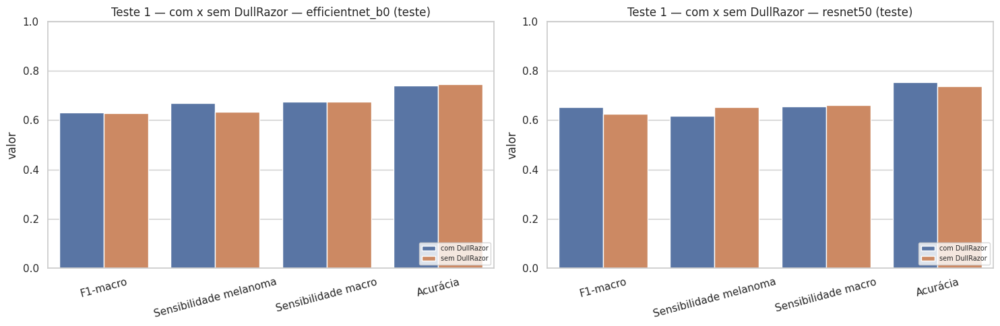

Gráfico salvo em: /content/data/processed/experimentos/comparacao_dullrazor.png


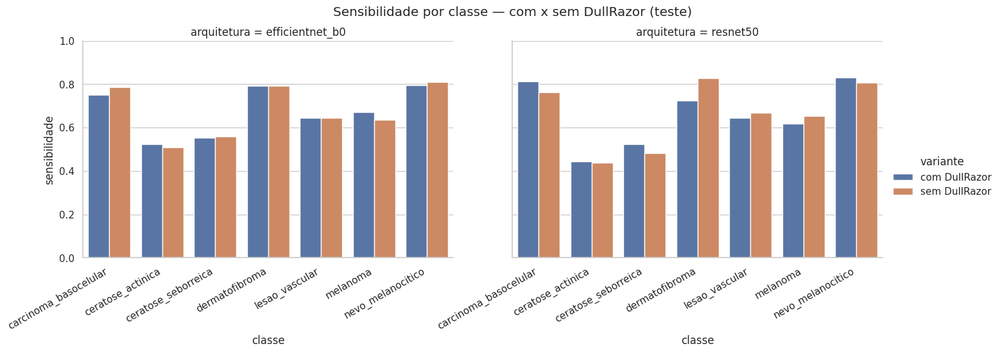

In [ ]:
# ============================================================
# TESTE 1 — COM x SEM DULLRAZOR (imagens tratadas x originais)
# ============================================================
if EXECUTAR["dullrazor"]:
    if not os.path.exists(caminho_csv_split("train", "sem_dullrazor")):
        raise FileNotFoundError("Versão 'sem DullRazor' não encontrada. Rode antes a célula "
                                "'VERSÃO SEM DULLRAZOR' (seção de pré-processamento).")
    res_dr = executar_fator("dullrazor", ARQS_TESTE_DULLRAZOR)
    df_dr = resumir_fator("dullrazor", res_dr, "Teste 1 — com x sem DullRazor")

    # Foco nas classes em que pelos/artefatos mais importam: sensibilidade por classe
    linhas = []
    for rotulo, por_arq in res_dr.items():
        for arq, lista in por_arq.items():
            for classe, rec in lista[0]["teste"]["recall_por_classe"].items():
                linhas.append({"variante": rotulo, "arquitetura": arq, "classe": classe, "sensibilidade": rec})
    df_cls = pd.DataFrame(linhas)
    g = sns.catplot(data=df_cls, x="classe", y="sensibilidade", hue="variante",
                    col="arquitetura", kind="bar", height=4.5, aspect=1.5)
    g.set_xticklabels(rotation=30, ha="right"); g.set(ylim=(0, 1))
    g.figure.suptitle("Sensibilidade por classe — com x sem DullRazor (teste)", y=1.03)
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "dullrazor_sensibilidade_por_classe.png"), dpi=150, bbox_inches="tight")
    plt.show()

#### Teste 2 — alterações de cor (brilho/contraste)

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__original__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=cosine | cor=original | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.6911 acc=0.4479 | Val: loss=1.2759 acc=0.5430 F1m=0.3738 SensMel=0.506 | lr=1.00e-03 | 47.6s
  [Etapa 1] Época 2/4 | Treino: loss=1.3862 acc=0.5248 | Val: loss=1.1069 acc=0.5986 F1m=0.4016 SensMel=0.49

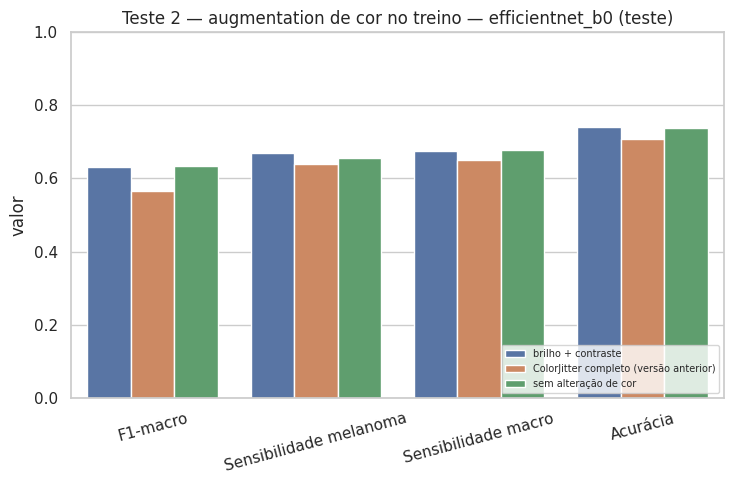

Gráfico salvo em: /content/data/processed/experimentos/comparacao_cor.png


In [ ]:
# ============================================================
# TESTE 2 — ALTERAÇÕES DE COR (brilho/contraste): treino com diferentes augmentations de cor
# ============================================================
if EXECUTAR["cor"]:
    res_cor = executar_fator("cor", [ARQ_ABLACAO])
    df_cor = resumir_fator("cor", res_cor, "Teste 2 — augmentation de cor no treino")

Efeito de cor: 100%|██████████| 150/150 [00:05<00:00, 29.63it/s]


Deslocamento médio de cor causado por cada perturbação (ΔE*ab; ≈2-3 já é perceptível a olho nu):
                    delta_E  var_contraste_L_pct  var_variegacao_ab_pct
perturbacao                                                            
brilho -20%           12.03           -16.930000             -16.709999
brilho +20%           10.95            13.620000              21.559999
contraste -20%         4.83           -18.940001             -21.590000
contraste +20%         4.41            15.760000              22.920000
saturação ±20% (+)     3.56            -1.410000              20.420000
matiz +0,10 (36°)     15.66           -10.690000              10.840000
matiz +0,25 (90°)     31.84           -10.880000              39.669998
matiz +0,50 (180°)    32.43            -5.210000             -20.160000


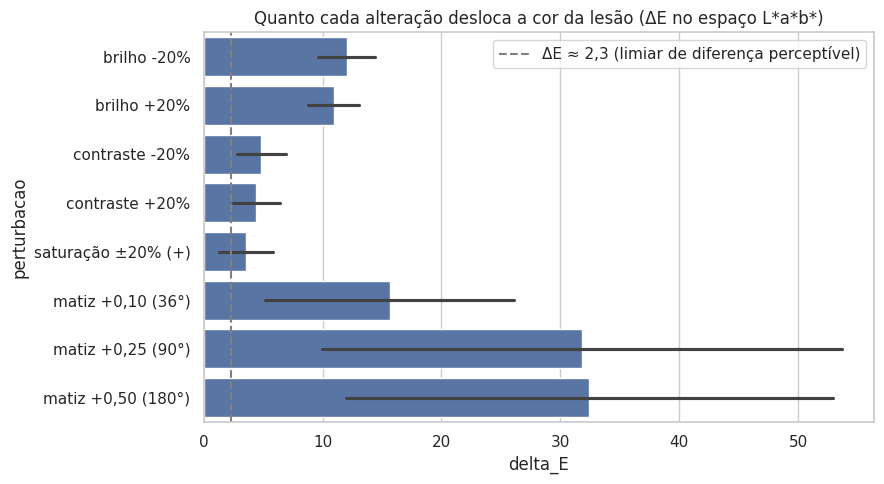

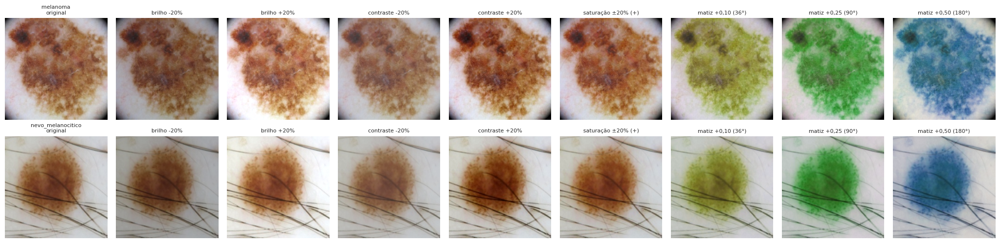

In [ ]:
# ============================================================
# TESTE 2 (cont.) — brilho/contraste/matiz alteram os sinais de COR da lesão? (nível de imagem)
# Mede, em imagens de teste, quanto cada perturbação desloca a cor no espaço CIE L*a*b*.
# ============================================================
PERTURBACOES_IMG = {
    "brilho -20%":        {"brilho": -0.2},
    "brilho +20%":        {"brilho": +0.2},
    "contraste -20%":     {"contraste": -0.2},
    "contraste +20%":     {"contraste": +0.2},
    "saturação ±20% (+)": {"saturacao": +0.2},
    "matiz +0,10 (36°)":  {"matiz": 0.10},
    "matiz +0,25 (90°)":  {"matiz": 0.25},
    "matiz +0,50 (180°)": {"matiz": 0.50},   # equivalente ao pior caso do ColorJitter padrão (versão anterior)
}

def _lab(img_rgb):
    return cv2.cvtColor(img_rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)

def analisar_efeito_cor_nas_imagens(n=150, dados=None):
    dados = dados or DADOS_ATIVOS
    df = _ler_split("test", dados)
    df = df.sample(n=min(n, len(df)), random_state=SEED)
    linhas = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="Efeito de cor"):
        img = cv2.cvtColor(cv2.imread(r["caminho_processado"]), cv2.COLOR_BGR2RGB)
        lab0 = _lab(img)
        base_std_L = lab0[..., 0].std()
        base_var_ab = lab0[..., 1].std() + lab0[..., 2].std()   # variegação de cor (proxy do "C" do ABCDE)
        for nome, kw in PERTURBACOES_IMG.items():
            lab1 = _lab(aplicar_perturbacao_cor(img, **kw))
            delta_e = np.sqrt(((lab1 - lab0) ** 2).sum(axis=2)).mean()   # ΔE*ab (CIE76) médio por pixel
            linhas.append({
                "perturbacao": nome, "classe": r["classe"], "delta_E": delta_e,
                "var_contraste_L_pct": 100 * (lab1[..., 0].std() - base_std_L) / (base_std_L + 1e-9),
                "var_variegacao_ab_pct": 100 * ((lab1[..., 1].std() + lab1[..., 2].std()) - base_var_ab) / (base_var_ab + 1e-9),
            })
    df_res = pd.DataFrame(linhas)
    resumo = df_res.groupby("perturbacao", sort=False)[["delta_E", "var_contraste_L_pct", "var_variegacao_ab_pct"]].mean().round(2)
    print("Deslocamento médio de cor causado por cada perturbação (ΔE*ab; ≈2-3 já é perceptível a olho nu):")
    print(resumo.to_string())
    resumo.to_csv(os.path.join(EXPERIMENTOS_DIR, "efeito_cor_nas_imagens.csv"))

    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_res, y="perturbacao", x="delta_E", order=list(PERTURBACOES_IMG), errorbar="sd")
    plt.axvline(2.3, color="gray", ls="--", label="ΔE ≈ 2,3 (limiar de diferença perceptível)")
    plt.title("Quanto cada alteração desloca a cor da lesão (ΔE no espaço L*a*b*)")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "efeito_cor_delta_e.png"), dpi=150)
    plt.show()

    # Exemplo visual: um melanoma e um nevo sob as perturbações
    exemplos = []
    for classe in ["melanoma", "nevo_melanocitico"]:
        sel = df[df["classe"] == classe]
        if len(sel):
            exemplos.append(sel.iloc[0])
    if exemplos:
        nomes = list(PERTURBACOES_IMG)
        fig, eixos = plt.subplots(len(exemplos), len(nomes) + 1, figsize=(2.3 * (len(nomes) + 1), 2.6 * len(exemplos)))
        eixos = np.atleast_2d(eixos)
        for i, r in enumerate(exemplos):
            img = cv2.cvtColor(cv2.imread(r["caminho_processado"]), cv2.COLOR_BGR2RGB)
            eixos[i, 0].imshow(img); eixos[i, 0].set_title(f"{r['classe']}\noriginal", fontsize=8)
            for j, nome in enumerate(nomes, start=1):
                eixos[i, j].imshow(aplicar_perturbacao_cor(img, **PERTURBACOES_IMG[nome]))
                eixos[i, j].set_title(nome, fontsize=8)
            for ax in eixos[i]:
                ax.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(EXPERIMENTOS_DIR, "exemplos_perturbacoes_cor.png"), dpi=150)
        plt.show()
    return resumo

if __name__ == "__main__":
    analisar_efeito_cor_nas_imagens()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


>>> Robustez: brilho + contraste

>>> Robustez: ColorJitter completo (versão anterior)

>>> Robustez: sem alteração de cor

                       variante_treino       tipo  nivel  f1_macro  sens_melanoma  acuracia  pct_predicoes_alteradas
                    brilho + contraste referência    0.0    0.6302         0.6705    0.7408                   0.0000
                    brilho + contraste     brilho   -0.4    0.6147         0.6590    0.7366                  13.1533
                    brilho + contraste     brilho   -0.2    0.6359         0.6639    0.7416                   5.9014
                    brilho + contraste     brilho    0.2    0.6170         0.6573    0.7428                   7.5455
                    brilho + contraste     brilho    0.4    0.5770         0.6359    0.7099                  15.7957
                    brilho + contraste  contraste   -0.4    0.5726         0.4992    0.7137                  16.0012
                    brilho + contraste  contraste   -0.2

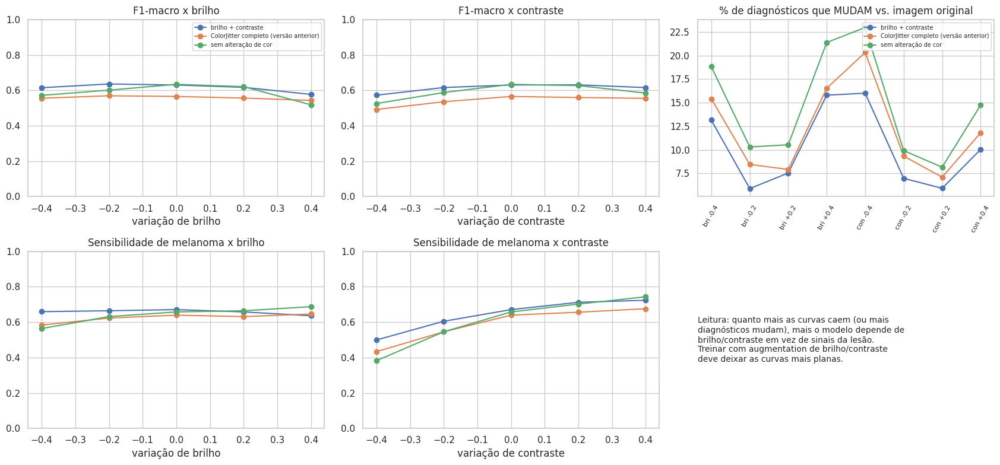

In [ ]:
# ============================================================
# TESTE 2 (cont.) — ROBUSTEZ DOS MODELOS A BRILHO/CONTRASTE NO TESTE
# Aplica perturbações determinísticas ao conjunto de TESTE e mede quanto as predições mudam.
# Um modelo que muda de diagnóstico só por brilho/contraste está usando sinal não clínico.
# ============================================================
NIVEIS_PERTURBACAO = [-0.4, -0.2, 0.2, 0.4]

def carregar_modelo_experimento(arquitetura, num_classes, caminho):
    if arquitetura == "resnet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(arquitetura)
    m.load_state_dict(torch.load(caminho, map_location=DEVICE))
    return m.to(DEVICE).eval()


def predizer_teste(modelo, perturbacao, dados):
    loader, mapa = criar_loader_teste(dados=dados, perturbacao=perturbacao)
    preds, rotulos = [], []
    with torch.no_grad():
        for imagens, rot in loader:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USAR_AMP):
                saidas = modelo(imagens.to(DEVICE))
            preds.append(saidas.argmax(dim=1).cpu())
            rotulos.append(rot)
    return torch.cat(preds).numpy(), torch.cat(rotulos).numpy(), mapa


def testar_robustez_brilho_contraste():
    linhas = []
    for rotulo, mudancas in FATORES["cor"].items():
        cfg = cfg_ablacao(ARQ_ABLACAO, seed=SEEDS[0], **mudancas)
        caminho = os.path.join(EXPERIMENTOS_DIR, nome_experimento(cfg), "modelo.pt")
        if not os.path.exists(caminho):
            print(f"[AVISO] Checkpoint não encontrado para '{rotulo}' — rode o Teste 2 antes. Pulando.")
            continue
        print(f"\n>>> Robustez: {rotulo}")
        dados = cfg["dados"]
        loader0, mapa = criar_loader_teste(dados=dados)
        modelo = carregar_modelo_experimento(ARQ_ABLACAO, len(mapa), caminho)
        idx_mel = mapa["melanoma"]

        preds_ref, rotulos, _ = predizer_teste(modelo, None, dados)
        cenarios = [("referência", 0.0, 0.0, preds_ref)]
        for tipo in ["brilho", "contraste"]:
            for nivel in NIVEIS_PERTURBACAO:
                p, _, _ = predizer_teste(modelo, {tipo: nivel}, dados)
                cenarios.append((tipo, nivel, None, p))

        for tipo, nivel, _, p in cenarios:
            linhas.append({
                "variante_treino": rotulo,
                "tipo": tipo, "nivel": 0.0 if tipo == "referência" else nivel,
                "f1_macro": f1_score(rotulos, p, labels=list(range(len(mapa))), average="macro", zero_division=0),
                "sens_melanoma": float(((p == idx_mel) & (rotulos == idx_mel)).sum() / max(1, (rotulos == idx_mel).sum())),
                "acuracia": float((p == rotulos).mean()),
                "pct_predicoes_alteradas": float((p != preds_ref).mean() * 100),
            })
        del modelo
        gc.collect(); torch.cuda.empty_cache()

    df = pd.DataFrame(linhas)
    if df.empty:
        return df
    df.to_csv(os.path.join(EXPERIMENTOS_DIR, "robustez_brilho_contraste.csv"), index=False)
    print("\n" + df.round(4).to_string(index=False))

    ref = df[df["tipo"] == "referência"]
    fig, eixos = plt.subplots(2, 3, figsize=(17, 8))
    for j, (tipo, titulo) in enumerate([("brilho", "Brilho"), ("contraste", "Contraste")]):
        for i, (metrica, nome_m) in enumerate([("f1_macro", "F1-macro"), ("sens_melanoma", "Sensibilidade de melanoma")]):
            ax = eixos[i, j]
            for variante, g in df.groupby("variante_treino", sort=False):
                pts = pd.concat([g[g["tipo"] == tipo][["nivel", metrica]],
                                 ref[ref["variante_treino"] == variante][["nivel", metrica]]]).sort_values("nivel")
                ax.plot(pts["nivel"], pts[metrica], marker="o", label=variante)
            ax.set_title(f"{nome_m} x {titulo.lower()}"); ax.set_xlabel(f"variação de {titulo.lower()}")
            ax.set_ylim(0, 1)
    ax = eixos[0, 2]
    for variante, g in df[df["tipo"] != "referência"].groupby("variante_treino", sort=False):
        ax.plot(range(len(g)), g["pct_predicoes_alteradas"].values, marker="o", label=variante)
    rotulos_x = [f"{t[:3]} {n:+.1f}" for t in ["brilho", "contraste"] for n in NIVEIS_PERTURBACAO]
    ax.set_xticks(range(len(rotulos_x))); ax.set_xticklabels(rotulos_x, rotation=60, fontsize=8)
    ax.set_title("% de diagnósticos que MUDAM vs. imagem original"); ax.legend(fontsize=7)
    eixos[1, 2].axis("off")
    eixos[1, 2].text(0, 0.5, "Leitura: quanto mais as curvas caem (ou mais\ndiagnósticos mudam), mais o modelo depende de\nbrilho/contraste em vez de sinais da lesão.\n"
                      "Treinar com augmentation de brilho/contraste\ndeve deixar as curvas mais planas.", fontsize=10, va="center")
    eixos[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "robustez_brilho_contraste.png"), dpi=150)
    plt.show()
    return df

if __name__ == "__main__" and EXECUTAR["robustez_cor"]:
    df_robustez = testar_robustez_brilho_contraste()

#### Teste 3 — Focal Loss × CrossEntropy ponderada

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__focal__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=focal | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.0946 acc=0.4313 | Val: loss=0.7970 acc=0.5387 F1m=0.3784 SensMel=0.473 | lr=1.00e-03 | 44.8s
  [Etapa 1] Época 2/4 | Treino: loss=0.7692 acc=0.5186 | Val: loss=0.7207 acc=

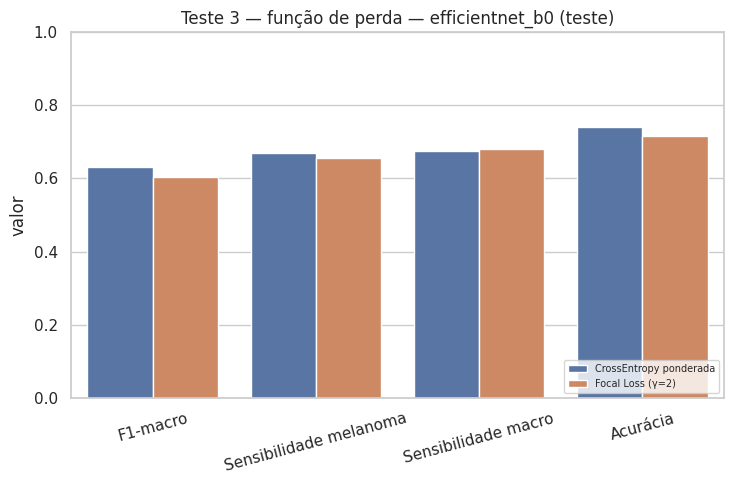

Gráfico salvo em: /content/data/processed/experimentos/comparacao_perda.png

Sensibilidade (recall) e F1 por classe — teste:
                               sensibilidade                                      f1                 
variante              CrossEntropy ponderada Focal Loss (γ=2) CrossEntropy ponderada Focal Loss (γ=2)
classe                                                                                               
carcinoma_basocelular                  0.752            0.743                  0.732            0.719
ceratose_actinica                      0.524            0.524                  0.423            0.401
ceratose_seborreica                    0.553            0.619                  0.506            0.527
dermatofibroma                         0.793            0.793                  0.667            0.590
lesao_vascular                         0.644            0.667                  0.617            0.571
melanoma                               0.671            0.6

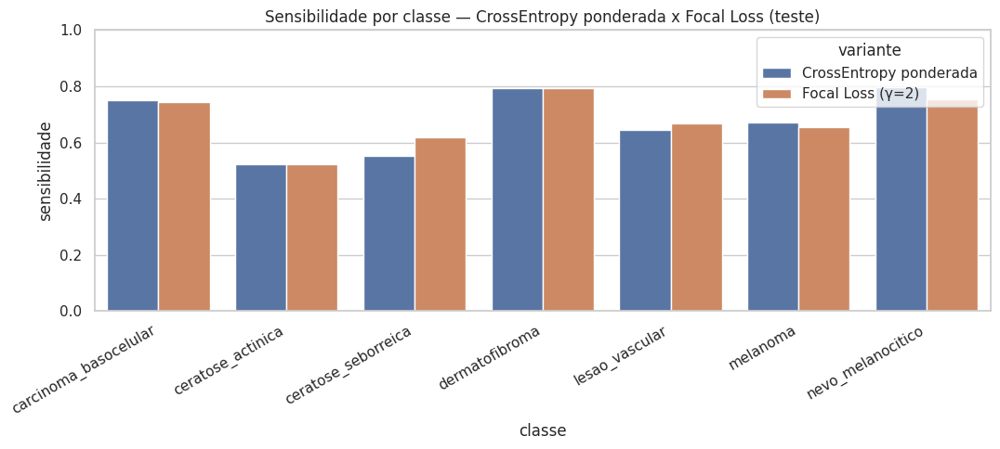

In [ ]:
# ============================================================
# TESTE 3 — FOCAL LOSS x CROSS-ENTROPY PONDERADA
# ============================================================
if EXECUTAR["focal"]:
    res_focal = executar_fator("perda", [ARQ_ABLACAO])
    df_focal = resumir_fator("perda", res_focal, "Teste 3 — função de perda")

    # O que a Focal Loss deveria fazer: melhorar as classes RARAS/DIFÍCEIS sem derrubar as demais.
    linhas = []
    for rotulo, por_arq in res_focal.items():
        r = por_arq[ARQ_ABLACAO][0]
        for classe, rec in r["teste"]["recall_por_classe"].items():
            linhas.append({"variante": rotulo, "classe": classe,
                           "sensibilidade": rec, "f1": r["teste"]["f1_por_classe"][classe]})
    df_cls = pd.DataFrame(linhas)
    print("\nSensibilidade (recall) e F1 por classe — teste:")
    print(df_cls.pivot(index="classe", columns="variante", values=["sensibilidade", "f1"]).round(3).to_string())

    plt.figure(figsize=(11, 5))
    sns.barplot(data=df_cls, x="classe", y="sensibilidade", hue="variante")
    plt.title("Sensibilidade por classe — CrossEntropy ponderada x Focal Loss (teste)")
    plt.xticks(rotation=30, ha="right"); plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "focal_sensibilidade_por_classe.png"), dpi=150)
    plt.show()

#### Teste 4 — escalonador de taxa de aprendizado

[CACHE] efficientnet_b0__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: efficientnet_b0__com_dullrazor__brilho_contraste__ce__nenhum__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: efficientnet_b0 | perda=ce | escalonador=nenhum | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.4300 acc=0.5402 | Val: loss=1.1689 acc=0.5757 F1m=0.4032 SensMel=0.485 | lr=1.00e-03 | 43.6s
  [Etapa 1] Época 2/4 | Treino: loss=1.2140 acc=0.5611 | Val: loss=1.0983 acc=0.5933

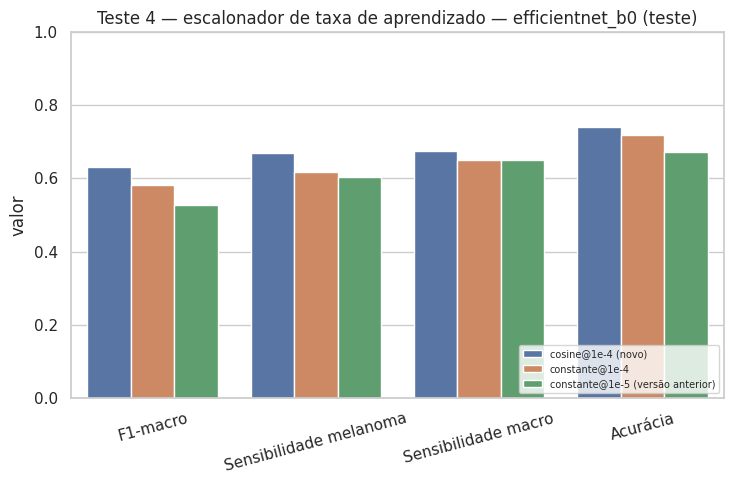

Gráfico salvo em: /content/data/processed/experimentos/comparacao_escalonador.png


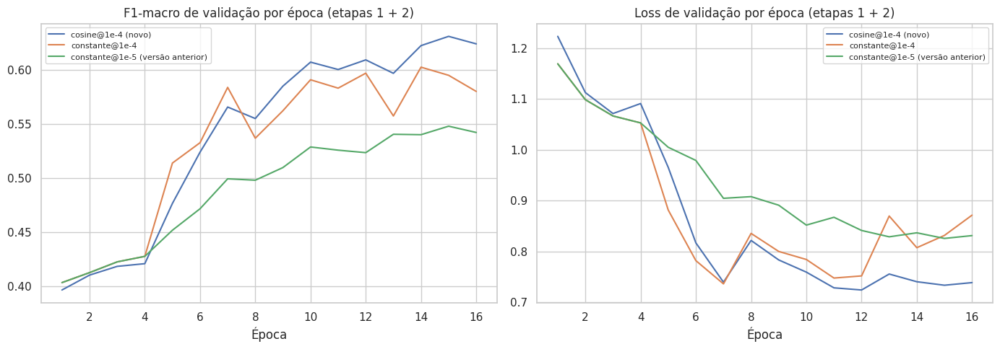

In [ ]:
# ============================================================
# TESTE 4 — ESCALONADOR DE TAXA DE APRENDIZADO
# ============================================================
if EXECUTAR["escalonador"]:
    res_esc = executar_fator("escalonador", [ARQ_ABLACAO])
    df_esc = resumir_fator("escalonador", res_esc, "Teste 4 — escalonador de taxa de aprendizado")

    # Curvas de convergência (F1-macro de validação por época e taxa de aprendizado)
    fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
    for rotulo, por_arq in res_esc.items():
        h = pd.DataFrame(por_arq[ARQ_ABLACAO][0]["historico"])
        h["epoca_global"] = range(1, len(h) + 1)
        eixos[0].plot(h["epoca_global"], h["f1_macro_val"], label=rotulo)
        eixos[1].plot(h["epoca_global"], h["perda_val"], label=rotulo)
    eixos[0].set_title("F1-macro de validação por época (etapas 1 + 2)")
    eixos[1].set_title("Loss de validação por época (etapas 1 + 2)")
    for ax in eixos:
        ax.set_xlabel("Época"); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(EXPERIMENTOS_DIR, "convergencia_escalonador.png"), dpi=150)
    plt.show()

In [ ]:
# ============================================================
# ABLACAO EXPLÍCITA EXIGIDA NO TCC: QUATRO CENÁRIOS COMPARÁVEIS
# ============================================================
# Todos os cenários usam o mesmo split sem vazamento, seed, número de épocas e protocolo.
# As épocas de ablação são menores que as do treinamento final para tornar a comparação
# viável; informe esse limite na metodologia e não misture estas métricas com as finais.
EXECUTAR_ABLACAO_TCC = True

CENARIOS_ABLACAO_TCC = [
    {"id": "ResNet50_DR_nao_Focal_nao", "arquitetura": "resnet50", "dados": "sem_dullrazor", "perda": "ce"},
    {"id": "ResNet50_DR_sim_Focal_nao", "arquitetura": "resnet50", "dados": "com_dullrazor", "perda": "ce"},
    {"id": "ResNet50_DR_sim_Focal_sim", "arquitetura": "resnet50", "dados": "com_dullrazor", "perda": "focal", "focal_alpha": "pesos"},
    {"id": "EfficientNetB0_DR_sim_Focal_sim", "arquitetura": "efficientnet_b0", "dados": "com_dullrazor", "perda": "focal", "focal_alpha": "pesos"},
]

if EXECUTAR_ABLACAO_TCC:
    linhas_ab_tcc = []
    for cenario in CENARIOS_ABLACAO_TCC:
        mudancas = {k: cenario[k] for k in ["dados", "perda"]}
        if cenario.get("focal_alpha"):
            mudancas["focal_alpha"] = cenario["focal_alpha"]
        cfg = cfg_ablacao(cenario["arquitetura"], **mudancas)
        resultado = rodar_experimento(cfg)
        teste = resultado["teste"]
        linhas_ab_tcc.append({
            "cenario": cenario["id"], "modelo": cenario["arquitetura"],
            "dullrazor": "Sim" if cenario["dados"] == "com_dullrazor" else "Não",
            "focal_loss": "Sim" if cenario["perda"] == "focal" else "Não",
            "acuracia_balanceada": teste.get("acuracia_balanceada"),
            "macro_f1": teste.get("f1_macro"),
            "recall_melanoma": teste.get("sens_melanoma"),
            "tempo_treinamento_s": resultado.get("tempo_s"),
            "epocas_executadas": len(resultado.get("historico", [])),
        })
    df_ab_tcc = pd.DataFrame(linhas_ab_tcc)
    caminho_ab_tcc = os.path.join(EXPERIMENTOS_DIR, "ablation_tcc_quatro_cenarios.csv")
    df_ab_tcc.to_csv(caminho_ab_tcc, index=False)
    print("\nTabela de ablação exigida pelo TCC:")
    print(df_ab_tcc.round(4).to_string(index=False))
    print(f"Salvo em: {caminho_ab_tcc}")


[CACHE] resnet50__sem_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
[CACHE] resnet50__com_dullrazor__brilho_contraste__ce__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2

######################################################################
EXPERIMENTO: resnet50__com_dullrazor__brilho_contraste__focal__cosine__lr0.0001__ep4-12__s42__split_lesion_phash_v2
######################################################################
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: brilho_contraste

ARQUITETURA: resnet50 | perda=focal | escalonador=cosine | cor=brilho_contraste | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/4 | Treino: loss=1.1292 acc=0.4200 | Val: loss=0.8677 acc=0.5342 F1m=0.3752 SensMel=0.464 | lr=1.00e-03

In [ ]:
import shutil
from google.colab import files

shutil.make_archive('/content/data', 'zip', '/content/data')
files.download('/content/data.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Seleção da configuração final

In [ ]:
# ============================================================
# SELEÇÃO DA CONFIGURAÇÃO FINAL (pelo F1-macro de VALIDAÇÃO)
# ============================================================
def escolher_vencedor(fator, resultados):
    rotulos = list(FATORES[fator])
    base = rotulos[0]

    def score(rotulo):
        return float(np.mean([_media(lista, lambda r: r["val"]["f1_macro"])
                              for lista in resultados[rotulo].values()]))

    pontuacoes = {r: score(r) for r in rotulos if r in resultados}
    melhor = max(pontuacoes, key=pontuacoes.get)
    if melhor != base and pontuacoes[melhor] - pontuacoes[base] < MARGEM_F1_VAL:
        melhor = base   # diferença dentro do ruído: mantém o padrão
    return melhor, pontuacoes


CFG_FINAL = dict(CFG_PADRAO)
decisoes = []
for fator, resultados in RESULTADOS_FATORES.items():
    vencedor, pontuacoes = escolher_vencedor(fator, resultados)
    CFG_FINAL.update(FATORES[fator][vencedor])
    decisoes.append({"fator": fator, "escolha": vencedor,
                     **{f"F1val[{k}]": round(v, 4) for k, v in pontuacoes.items()}})

if decisoes:
    print("DECISÕES (critério: F1-macro de validação; margem mínima = "
          f"{MARGEM_F1_VAL}):")
    for d in decisoes:
        print(f"  - {d['fator']}: {d['escolha']}")
        for k, v in d.items():
            if k.startswith("F1val"):
                print(f"        {k} = {v}")
else:
    print("Nenhum teste foi executado — a configuração final é a padrão (CFG_PADRAO).")

DADOS_ATIVOS = CFG_FINAL["dados"]   # downstream (avaliação, Grad-CAM, equidade) usa a mesma versão das imagens
print("\nCONFIGURAÇÃO FINAL:")
print(json.dumps({k: CFG_FINAL[k] for k in ["dados", "cor", "perda", "focal_gamma", "focal_alpha",
                                              "scheduler", "lr_e1", "lr_e2", "fator_lr_cabeca"]}, indent=2))
with open(os.path.join(EXPERIMENTOS_DIR, "config_final.json"), "w") as f:
    json.dump({"config_final": CFG_FINAL, "decisoes": decisoes}, f, indent=2, default=_json_seguro)

DECISÕES (critério: F1-macro de validação; margem mínima = 0.005):
  - dullrazor: com DullRazor
        F1val[com DullRazor] = 0.6418
        F1val[sem DullRazor] = 0.6255
  - cor: sem alteração de cor
        F1val[brilho + contraste] = 0.6308
        F1val[ColorJitter completo (versão anterior)] = 0.5933
        F1val[sem alteração de cor] = 0.6367
  - perda: CrossEntropy ponderada
        F1val[CrossEntropy ponderada] = 0.6308
        F1val[Focal Loss (γ=2)] = 0.594
  - escalonador: cosine@1e-4 (novo)
        F1val[cosine@1e-4 (novo)] = 0.6308
        F1val[constante@1e-4] = 0.6023
        F1val[constante@1e-5 (versão anterior)] = 0.5478

CONFIGURAÇÃO FINAL:
{
  "dados": "com_dullrazor",
  "cor": "sem_cor",
  "perda": "ce",
  "focal_gamma": 2.0,
  "focal_alpha": "raiz",
  "scheduler": "cosine",
  "lr_e1": 0.001,
  "lr_e2": 0.0001,
  "fator_lr_cabeca": 10.0
}


### Treinamento final com a configuração escolhida

A célula abaixo treina **ResNet50 e EfficientNet-B0 com as épocas completas** usando `CFG_FINAL` (definida na seleção acima; se os experimentos não foram executados, vale `CFG_PADRAO`). Ela salva `modelo_resnet50.pt` e `modelo_efficientnet_b0.pt` em `/content/data/processed/`, que são lidos pelas seções seguintes (avaliação, Grad-CAM e equidade).

**Nota sobre resultados anteriores:** os valores do split antigo foram removidos da comparação automática, pois não são diretamente comparáveis ao novo protocolo agrupado por `lesion_id` e pHash. Use somente os resultados gerados após executar este notebook corrigido.


Dispositivo: cuda

Configuração final: {'dados': 'com_dullrazor', 'cor': 'sem_cor', 'perda': 'ce', 'focal_gamma': 2.0, 'focal_alpha': 'raiz', 'scheduler': 'cosine', 'epocas_e1': 6, 'epocas_e2': 24, 'lr_e1': 0.001, 'lr_e2': 0.0001, 'fator_lr_cabeca': 10.0, 'seed': 42}

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: sem_cor
Classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}

Calculando pesos de classe...

ARQUITETURA: resnet50 | perda=ce | escalonador=cosine | cor=sem_cor | dados=com_dullrazor

--- Etapa 1: treinando só a cabeça (camadas congeladas) ---
  [Etapa 1] Época 1/6 | Treino: loss=1.6563 acc=0.4934 | Val: loss=1.3288 acc=0.5068 F1m=0.3595 SensMel=0.466 | lr=1.00e-03 

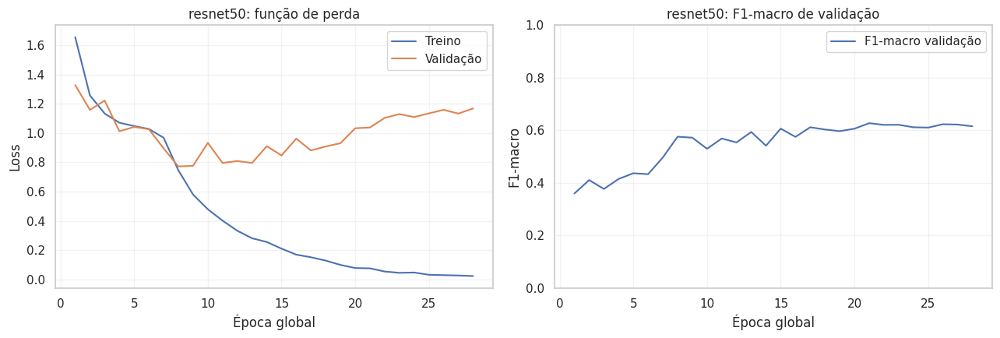

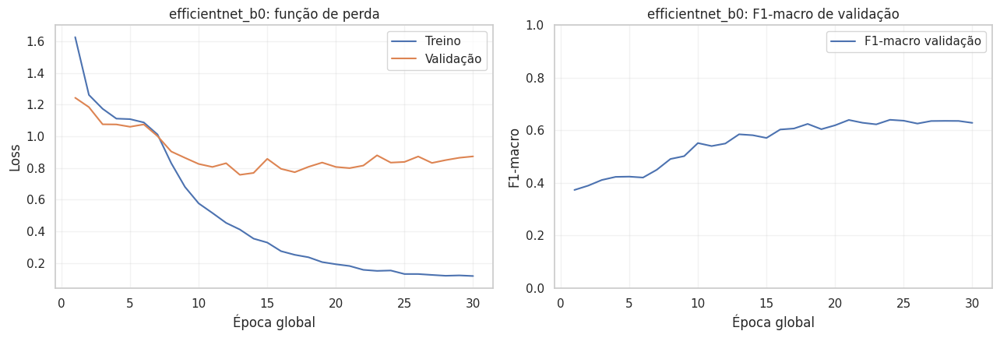


Resultados completos salvos em: /content/data/processed/resultados_comparacao.json


In [ ]:
# ============================================================
# EXECUÇÃO PRINCIPAL — treinamento FINAL (épocas completas) com a configuração escolhida
# nos experimentos (CFG_FINAL). Sem rodar os experimentos, usa a configuração padrão.
# ============================================================
if __name__ == "__main__":
    print(f"Dispositivo: {DEVICE}")
    if DEVICE.type == "cpu":
        print("[AVISO] Sem GPU — esse treinamento completo vai ser MUITO lento em CPU.")

    cfg_final = {**CFG_PADRAO, **CFG_FINAL}
    DADOS_ATIVOS = cfg_final["dados"]
    print(f"\nConfiguração final: {cfg_final}")

    print("\nCarregando DataLoaders...")
    train_loader, val_loader, test_loader, mapa_classes = criar_dataloaders(
        dados=cfg_final["dados"], variante_cor=cfg_final["cor"])
    print(f"Classes: {mapa_classes}")

    print("\nCalculando pesos de classe...")
    pesos_classe = calcular_pesos_classe(train_loader, mapa_classes)

    resultados_comparacao = []
    historicos = {}
    tempos_treinamento = {}
    resumo_epocas = {}

    for arquitetura in ["resnet50", "efficientnet_b0"]:
        fixar_semente(cfg_final["seed"])
        inicio_treino = time.time()
        modelo, historico = treinar_arquitetura(
            arquitetura, train_loader, val_loader, mapa_classes, pesos_classe, cfg=cfg_final
        )
        tempos_treinamento[arquitetura] = time.time() - inicio_treino
        historicos[arquitetura] = historico
        if historico:
            # O checkpoint final é selecionado dentro da etapa 2; não comparar com épocas da etapa 1.
            candidatos_melhor = [h for h in historico if h.get("etapa") == "fine_tuning_completo"] or historico
            melhor_registro = max(candidatos_melhor, key=lambda h: h.get("f1_macro_val", -1))
            resumo_epocas[arquitetura] = {
                "epocas_executadas_total": len(historico),
                "epocas_etapa1": sum(h.get("etapa") == "cabeca_congelada" for h in historico),
                "epocas_etapa2": sum(h.get("etapa") == "fine_tuning_completo" for h in historico),
                "melhor_epoca_global_por_f1_validacao": int(melhor_registro.get("epoca_global", 0)),
                "melhor_epoca_na_etapa2": int(melhor_registro.get("epoca", 0)),
                "melhor_f1_macro_validacao": float(melhor_registro.get("f1_macro_val", float("nan"))),
                "tempo_treinamento_segundos": float(tempos_treinamento[arquitetura]),
                "tempo_treinamento_minutos": float(tempos_treinamento[arquitetura] / 60),
            }

        resultado = avaliar_no_teste(modelo, test_loader, mapa_classes, arquitetura)
        resultado["sens_melanoma"] = resultado["relatorio_completo"]["melanoma"]["recall"]
        resultados_comparacao.append(resultado)

        # Libera memória de GPU antes da próxima arquitetura
        del modelo
        torch.cuda.empty_cache()

    # ============================================================
    # TABELA COMPARATIVA FINAL
    # ============================================================
    print("\n" + "=" * 70)
    print("TABELA COMPARATIVA FINAL — ResNet50 vs. EfficientNet-B0")
    print("=" * 70)
    print(f"{'Métrica':<28}{'ResNet50':>18}{'EfficientNet-B0':>20}")
    print("-" * 70)

    r0, r1 = resultados_comparacao[0], resultados_comparacao[1]
    linhas = [
        ("Acurácia", "acuracia"),
        ("Acurácia balanceada", "acuracia_balanceada"),
        ("Sensibilidade (macro)", "sensibilidade_macro"),
        ("Precisão (macro)", "precisao_macro"),
        ("F1-score (macro)", "f1_macro"),
        ("AUC-ROC (OVR)", "auc_roc_ovr"),
        ("Especificidade média", "especificidade_media"),
        ("Sensibilidade melanoma", "sens_melanoma"),
    ]
    for rotulo, chave in linhas:
        v0 = r0[chave] if r0[chave] is not None else float("nan")
        v1 = r1[chave] if r1[chave] is not None else float("nan")
        print(f"{rotulo:<28}{v0:>18.4f}{v1:>20.4f}")

    # Curvas finais de loss e F1-macro de validação e históricos por época
    pasta_curvas = os.path.join(SAIDA_BASE, "curvas_treinamento")
    os.makedirs(pasta_curvas, exist_ok=True)
    for arquitetura, hist in historicos.items():
        df_hist = pd.DataFrame(hist)
        df_hist.to_csv(os.path.join(pasta_curvas, f"historico_{arquitetura}.csv"), index=False)
        if len(df_hist):
            eixo = df_hist["epoca_global"] if "epoca_global" in df_hist.columns else np.arange(1, len(df_hist) + 1)
            fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
            ax[0].plot(eixo, df_hist["perda_treino"], label="Treino")
            ax[0].plot(eixo, df_hist["perda_val"], label="Validação")
            ax[0].set_title(f"{arquitetura}: função de perda")
            ax[0].set_xlabel("Época global"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=.25)
            ax[1].plot(eixo, df_hist["f1_macro_val"], label="F1-macro validação")
            ax[1].set_title(f"{arquitetura}: F1-macro de validação")
            ax[1].set_xlabel("Época global"); ax[1].set_ylabel("F1-macro"); ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].grid(alpha=.25)
            fig.tight_layout()
            fig.savefig(os.path.join(pasta_curvas, f"curvas_{arquitetura}.png"), dpi=160, bbox_inches="tight")
            plt.show()

    # Salva tudo em JSON para usar depois no capítulo de resultados
    caminho_resultados = os.path.join(SAIDA_BASE, "resultados_comparacao.json")
    with open(caminho_resultados, "w") as f:
        json.dump({
            "config_final": cfg_final,
            "resultados": resultados_comparacao,
            "historicos": historicos,
            "tempos_treinamento": tempos_treinamento,
            "resumo_epocas": resumo_epocas,
            "ambiente": coletar_metadados_ambiente(),
            "mapa_classes": mapa_classes,
        }, f, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
    print(f"\nResultados completos salvos em: {caminho_resultados}")

### AVALIAÇÃO COM MÉTRICAS CLÍNICAS + MATRIZ DE CONFUSÃO

Carrega os checkpoints já treinados (modelo_resnet50.pt, modelo_efficientnet_b0.pt)
e gera um pacote completo de avaliação, pronto para uso no Capítulo 4 (Resultados)
do TCC:

  - Matriz de confusão (heatmap) por arquitetura
  - Curvas ROC por classe (one-vs-rest) por arquitetura
  - Tabela de métricas clínicas por classe: sensibilidade, especificidade,
    precisão, F1-score
  - Tabela comparativa geral entre arquiteturas
  - Gráfico de barras comparando as arquiteturas
  - Tudo salvo em /content/data/processed/avaliacao/

Pré-requisito: rodar fine_tuning_completo.py antes (precisa dos checkpoints
e do dataset_pytorch.py disponível).

In [ ]:
import os
import json
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_AVALIACAO = os.path.join(SAIDA_BASE, "avaliacao")
os.makedirs(SAIDA_AVALIACAO, exist_ok=True)

ARQUITETURAS = ["resnet50", "efficientnet_b0"]

In [ ]:
# ============================================================
# RECONSTRUÇÃO DO MODELO E CARREGAMENTO DO CHECKPOINT
# ============================================================
def carregar_modelo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES NO CONJUNTO DE TESTE
# ============================================================
def coletar_predicoes(modelo, test_loader):
    todos_rotulos, todas_probs, todas_preds = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            saidas = modelo(imagens)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            todos_rotulos.extend(rotulos.numpy())
            todas_probs.extend(probs)
            todas_preds.extend(preds)

    return np.array(todos_rotulos), np.array(todas_probs), np.array(todas_preds)

In [ ]:
# ============================================================
# MATRIZ DE CONFUSÃO (HEATMAP)
# ============================================================
def plotar_matriz_confusao(rotulos_verdadeiros, predicoes, nomes_classes, arquitetura):
    matriz = confusion_matrix(rotulos_verdadeiros, predicoes)
    matriz_normalizada = matriz.astype("float") / matriz.sum(axis=1, keepdims=True)

    fig, eixos = plt.subplots(1, 2, figsize=(18, 7))

    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
                xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[0])
    eixos[0].set_title(f"Matriz de Confusão (contagem) — {arquitetura}")
    eixos[0].set_xlabel("Predito")
    eixos[0].set_ylabel("Verdadeiro")
    eixos[0].tick_params(axis="x", rotation=45)

    sns.heatmap(matriz_normalizada, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[1])
    eixos[1].set_title(f"Matriz de Confusão (normalizada por classe) — {arquitetura}")
    eixos[1].set_xlabel("Predito")
    eixos[1].set_ylabel("Verdadeiro")
    eixos[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    caminho = os.path.join(SAIDA_AVALIACAO, f"matriz_confusao_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Matriz de confusão salva em: {caminho}")

    return matriz

In [ ]:
# ============================================================
# CURVAS ROC POR CLASSE (ONE-VS-REST)
# ============================================================
def plotar_curvas_roc(rotulos_verdadeiros, probs, nomes_classes, arquitetura):
    num_classes = len(nomes_classes)
    rotulos_binarizados = label_binarize(rotulos_verdadeiros, classes=range(num_classes))

    plt.figure(figsize=(9, 7))
    valores_auc = {}

    for i, nome_classe in enumerate(nomes_classes):
        fpr, tpr, _ = roc_curve(rotulos_binarizados[:, i], probs[:, i])
        valor_auc = auc(fpr, tpr)
        valores_auc[nome_classe] = valor_auc
        plt.plot(fpr, tpr, label=f"{nome_classe} (AUC = {valor_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--", label="Aleatório (AUC = 0.5)")
    plt.xlabel("Taxa de Falso Positivo (1 - Especificidade)")
    plt.ylabel("Taxa de Verdadeiro Positivo (Sensibilidade)")
    plt.title(f"Curvas ROC por classe (one-vs-rest) — {arquitetura}")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()

    caminho = os.path.join(SAIDA_AVALIACAO, f"curvas_roc_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Curvas ROC salvas em: {caminho}")

    return valores_auc

In [ ]:
# ============================================================
# MÉTRICAS CLÍNICAS POR CLASSE
# ============================================================
def calcular_metricas_clinicas_por_classe(matriz, nomes_classes, valores_auc):
    linhas = []
    total = matriz.sum()

    for i, nome_classe in enumerate(nomes_classes):
        vp = matriz[i, i]
        fn = matriz[i, :].sum() - vp
        fp = matriz[:, i].sum() - vp
        vn = total - vp - fn - fp

        sensibilidade = vp / (vp + fn) if (vp + fn) > 0 else 0.0   # recall / taxa de detecção
        especificidade = vn / (vn + fp) if (vn + fp) > 0 else 0.0  # taxa de rejeição correta
        precisao = vp / (vp + fp) if (vp + fp) > 0 else 0.0        # valor preditivo positivo
        vpn = vn / (vn + fn) if (vn + fn) > 0 else 0.0             # valor preditivo negativo
        f1 = (2 * precisao * sensibilidade / (precisao + sensibilidade)
              if (precisao + sensibilidade) > 0 else 0.0)

        linhas.append({
            "classe": nome_classe,
            "n_amostras_teste": int(matriz[i, :].sum()),
            "sensibilidade": round(sensibilidade, 4),
            "especificidade": round(especificidade, 4),
            "precisao_vpp": round(precisao, 4),
            "vpn": round(vpn, 4),
            "f1_score": round(f1, 4),
            "auc_roc": round(valores_auc[nome_classe], 4),
        })

    return pd.DataFrame(linhas)

In [ ]:
# ============================================================
# AVALIAÇÃO COMPLETA DE UMA ARQUITETURA
# ============================================================
def avaliar_arquitetura(arquitetura, test_loader, mapa_classes):
    print("\n" + "=" * 60)
    print(f"Avaliando: {arquitetura}")
    print("=" * 60)

    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)

    modelo = carregar_modelo(arquitetura, num_classes)
    rotulos_verdadeiros, probs, predicoes = coletar_predicoes(modelo, test_loader)

    matriz = plotar_matriz_confusao(rotulos_verdadeiros, predicoes, nomes_classes, arquitetura)
    valores_auc = plotar_curvas_roc(rotulos_verdadeiros, probs, nomes_classes, arquitetura)
    df_metricas = calcular_metricas_clinicas_por_classe(matriz, nomes_classes, valores_auc)

    print(f"\nMétricas clínicas por classe — {arquitetura}:")
    print(df_metricas.to_string(index=False))

    caminho_csv = os.path.join(SAIDA_AVALIACAO, f"metricas_por_classe_{arquitetura}.csv")
    df_metricas.to_csv(caminho_csv, index=False)
    print(f"\nTabela salva em: {caminho_csv}")

    acuracia_geral = (predicoes == rotulos_verdadeiros).mean()
    acuracia_balanceada = float(df_metricas["sensibilidade"].mean())
    resumo_geral = {
        "arquitetura": arquitetura,
        "acuracia_geral": round(float(acuracia_geral), 4),
        "acuracia_balanceada": round(acuracia_balanceada, 4),
        "sensibilidade_media_macro": round(float(df_metricas["sensibilidade"].mean()), 4),
        "especificidade_media_macro": round(float(df_metricas["especificidade"].mean()), 4),
        "precisao_media_macro": round(float(df_metricas["precisao_vpp"].mean()), 4),
        "f1_medio_macro": round(float(df_metricas["f1_score"].mean()), 4),
        "auc_roc_media_macro": round(float(df_metricas["auc_roc"].mean()), 4),
    }

    del modelo
    torch.cuda.empty_cache()

    return df_metricas, resumo_geral

In [ ]:
# ============================================================
# COMPARAÇÃO VISUAL ENTRE ARQUITETURAS
# ============================================================
def plotar_comparacao_arquiteturas(resumos):
    df_resumo = pd.DataFrame(resumos)
    metricas_plotadas = [
        "acuracia_geral", "sensibilidade_media_macro", "especificidade_media_macro",
        "precisao_media_macro", "f1_medio_macro", "auc_roc_media_macro"
    ]

    df_plot = df_resumo.melt(
        id_vars="arquitetura", value_vars=metricas_plotadas,
        var_name="metrica", value_name="valor"
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_plot, x="metrica", y="valor", hue="arquitetura")
    plt.title("Comparação geral entre arquiteturas (médias macro)")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()

    caminho = os.path.join(SAIDA_AVALIACAO, "comparacao_arquiteturas.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"\nGráfico comparativo salvo em: {caminho}")

    return df_resumo

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Avaliando: resnet50


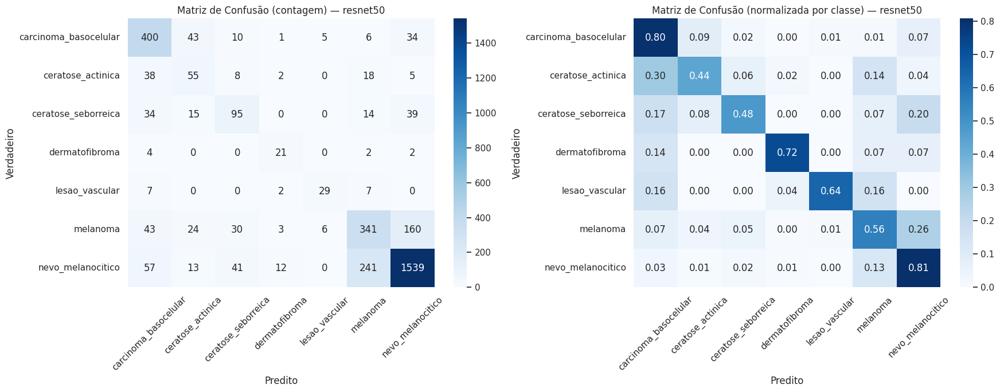

Matriz de confusão salva em: /content/data/processed/avaliacao/matriz_confusao_resnet50.png


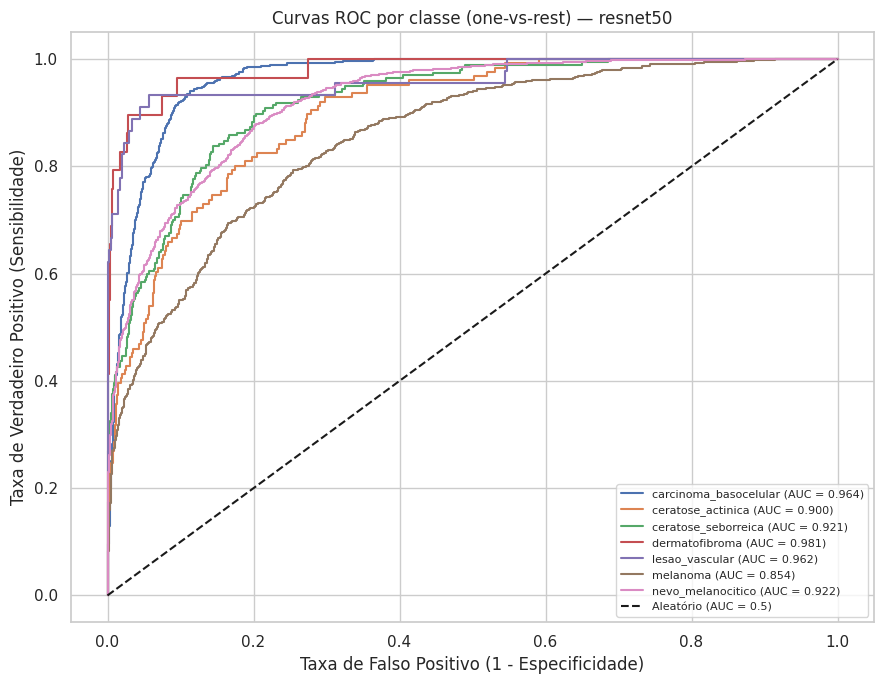

Curvas ROC salvas em: /content/data/processed/avaliacao/curvas_roc_resnet50.png

Métricas clínicas por classe — resnet50:
               classe  n_amostras_teste  sensibilidade  especificidade  precisao_vpp    vpn  f1_score  auc_roc
carcinoma_basocelular               499         0.8016          0.9370        0.6861 0.9649    0.7394   0.9636
    ceratose_actinica               126         0.4365          0.9710        0.3667 0.9782    0.3986   0.8997
  ceratose_seborreica               197         0.4822          0.9723        0.5163 0.9683    0.4987   0.9207
       dermatofibroma                29         0.7241          0.9941        0.5122 0.9976    0.6000   0.9806
       lesao_vascular                45         0.6444          0.9967        0.7250 0.9952    0.6824   0.9621
             melanoma               607         0.5618          0.8971        0.5421 0.9042    0.5518   0.8539
    nevo_melanocitico              1903         0.8087          0.8403        0.8651 0.7763    0.8360

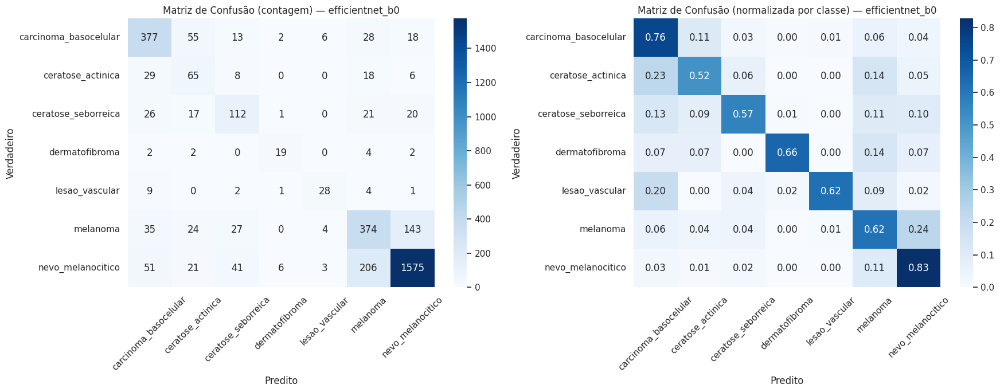

Matriz de confusão salva em: /content/data/processed/avaliacao/matriz_confusao_efficientnet_b0.png


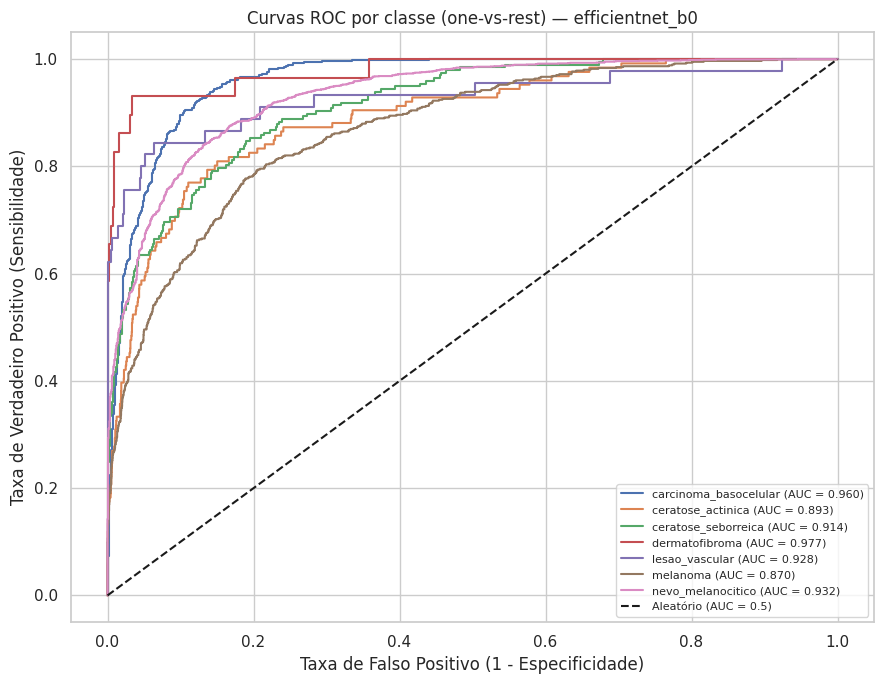

Curvas ROC salvas em: /content/data/processed/avaliacao/curvas_roc_efficientnet_b0.png

Métricas clínicas por classe — efficientnet_b0:
               classe  n_amostras_teste  sensibilidade  especificidade  precisao_vpp    vpn  f1_score  auc_roc
carcinoma_basocelular               499         0.7555          0.9477        0.7127 0.9576    0.7335   0.9603
    ceratose_actinica               126         0.5159          0.9637        0.3533 0.9811    0.4194   0.8929
  ceratose_seborreica               197         0.5685          0.9716        0.5517 0.9735    0.5600   0.9136
       dermatofibroma                29         0.6552          0.9970        0.6552 0.9970    0.6552   0.9772
       lesao_vascular                45         0.6222          0.9961        0.6829 0.9949    0.6512   0.9284
             melanoma               607         0.6161          0.8996        0.5710 0.9153    0.5927   0.8696
    nevo_melanocitico              1903         0.8276          0.8736        0.8924 0.

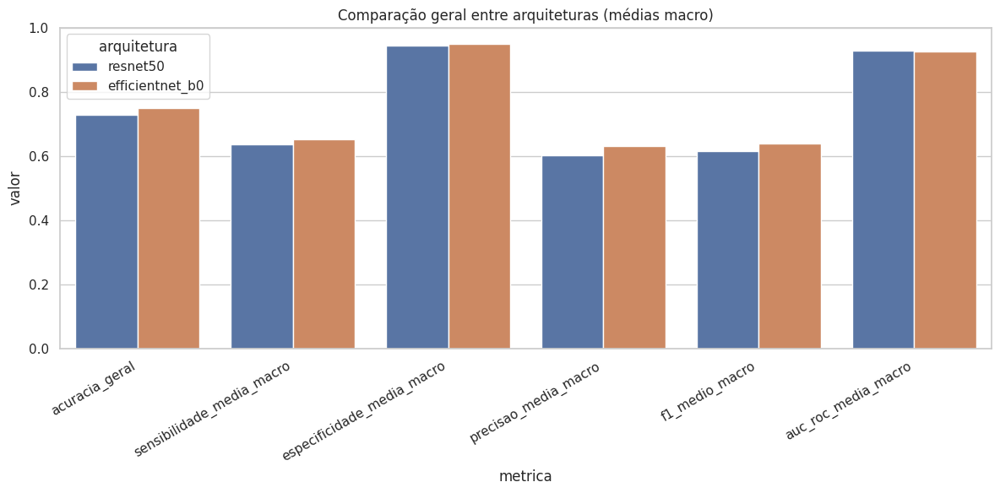


Gráfico comparativo salvo em: /content/data/processed/avaliacao/comparacao_arquiteturas.png
    arquitetura  acuracia_geral  acuracia_balanceada  sensibilidade_media_macro  especificidade_media_macro  precisao_media_macro  f1_medio_macro  auc_roc_media_macro
       resnet50          0.7281               0.6370                     0.6370                      0.9441                0.6019          0.6153               0.9289
efficientnet_b0          0.7487               0.6516                     0.6516                      0.9499                0.6313          0.6387               0.9249

Tabela comparativa salva em: /content/data/processed/avaliacao/comparacao_geral.csv
Avaliação completa consolidada em: /content/data/processed/avaliacao/avaliacao_completa.json

ARQUIVOS GERADOS EM: /content/data/processed/avaliacao
  - avaliacao_completa.json
  - comparacao_arquiteturas.png
  - comparacao_geral.csv
  - curvas_roc_efficientnet_b0.png
  - curvas_roc_resnet50.png
  - matriz_confusao_effi

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()

    resumos_gerais = []
    metricas_completas = {}

    for arquitetura in ARQUITETURAS:
        df_metricas, resumo = avaliar_arquitetura(arquitetura, test_loader, mapa_classes)
        resumos_gerais.append(resumo)
        metricas_completas[arquitetura] = df_metricas.to_dict(orient="records")

    print("\n" + "=" * 70)
    print("TABELA COMPARATIVA GERAL")
    print("=" * 70)
    df_comparacao = plotar_comparacao_arquiteturas(resumos_gerais)
    print(df_comparacao.to_string(index=False))

    caminho_comparacao_csv = os.path.join(SAIDA_AVALIACAO, "comparacao_geral.csv")
    df_comparacao.to_csv(caminho_comparacao_csv, index=False)
    print(f"\nTabela comparativa salva em: {caminho_comparacao_csv}")

    # Consolida tudo num único JSON para referência
    caminho_json = os.path.join(SAIDA_AVALIACAO, "avaliacao_completa.json")
    with open(caminho_json, "w") as f:
        json.dump({
            "resumo_geral": resumos_gerais,
            "metricas_por_classe": metricas_completas,
        }, f, indent=2)
    print(f"Avaliação completa consolidada em: {caminho_json}")

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_AVALIACAO)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_AVALIACAO)):
        print(f"  - {arquivo}")

In [ ]:
# ============================================================
# RASCUNHO AUTOMÁTICO DA DISCUSSÃO A PARTIR DOS RESULTADOS REAIS
# ============================================================
# Este código não inventa conclusões: só gera um rascunho quando os JSONs existem.
# Revise o texto, confronte com os estudos do referencial e não interprete correlação como causalidade.

def gerar_rascunho_discussao():
    caminho = os.path.join(SAIDA_BASE, "resultados_comparacao.json")
    if not os.path.exists(caminho):
        print("Resultados finais ainda não encontrados. Execute o treinamento final antes da discussão.")
        return None
    with open(caminho, encoding="utf-8") as f:
        dados = json.load(f)
    resultados = dados.get("resultados", [])
    if len(resultados) < 2:
        print("O arquivo não contém resultados para as duas arquiteturas.")
        return None
    por_nome = {r.get("arquitetura"): r for r in resultados}
    if "resnet50" not in por_nome or "efficientnet_b0" not in por_nome:
        print("Não foi possível identificar ambas as arquiteturas no JSON.")
        return None
    r, e = por_nome["resnet50"], por_nome["efficientnet_b0"]
    metricas = ["acuracia_balanceada", "f1_macro", "sens_melanoma", "auc_roc_ovr"]
    linhas = ["RASCUNHO PARA REVISÃO — DISCUSSÃO DOS RESULTADOS", ""]
    linhas.append(f"A ResNet50 obteve acurácia balanceada de {r.get('acuracia_balanceada', float('nan')):.4f} e macro F1 de {r.get('f1_macro', float('nan')):.4f}; a EfficientNet-B0 obteve acurácia balanceada de {e.get('acuracia_balanceada', float('nan')):.4f} e macro F1 de {e.get('f1_macro', float('nan')):.4f}.")
    chave = "acuracia_balanceada" if r.get("acuracia_balanceada") is not None and e.get("acuracia_balanceada") is not None else "f1_macro"
    melhor = "ResNet50" if (r.get(chave, -1) or -1) >= (e.get(chave, -1) or -1) else "EfficientNet-B0"
    linhas.append(f"Considerando {chave} como critério principal de comparação, a maior pontuação foi observada em {melhor}. Essa conclusão deve ser contextualizada pelas métricas por classe, e não apenas pela métrica agregada.")
    linhas.append(f"A sensibilidade para melanoma foi {r.get('sens_melanoma', float('nan')):.4f} na ResNet50 e {e.get('sens_melanoma', float('nan')):.4f} na EfficientNet-B0. O modelo com maior sensibilidade para melanoma foi {('ResNet50' if (r.get('sens_melanoma') or -1) >= (e.get('sens_melanoma') or -1) else 'EfficientNet-B0')}; isso deve ser discutido em conjunto com os falsos negativos e a especificidade.")
    linhas.append("As classes com maior confusão devem ser identificadas nas matrizes de confusão salvas. Relacione os erros às quantidades por classe e às métricas de sensibilidade/F1, evitando atribuir o efeito exclusivamente ao desbalanceamento sem evidência adicional.")
    linhas.append("A influência de DullRazor e Focal Loss deve ser descrita a partir do arquivo experimentos/ablation_tcc_quatro_cenarios.csv. Compare acurácia balanceada, macro F1 e sensibilidade de melanoma e informe que os experimentos de ablação usam o mesmo particionamento e número de épocas.")
    linhas.append("Por fim, confronte os resultados com os trabalhos citados no referencial teórico. Não declare concordância ou superioridade frente à literatura sem comparação explícita de bases, particionamento, classes, métricas e protocolo experimental.")
    texto = "\n\n".join(linhas)
    caminho_txt = os.path.join(SAIDA_BASE, "rascunho_discussao_resultados.txt")
    with open(caminho_txt, "w", encoding="utf-8") as f:
        f.write(texto)
    print(texto)
    print(f"\nRascunho salvo em: {caminho_txt}")
    return texto

if __name__ == "__main__":
    gerar_rascunho_discussao()


RASCUNHO PARA REVISÃO — DISCUSSÃO DOS RESULTADOS



A ResNet50 obteve acurácia balanceada de 0.6369 e macro F1 de 0.6153; a EfficientNet-B0 obteve acurácia balanceada de 0.6487 e macro F1 de 0.6370.

Considerando acuracia_balanceada como critério principal de comparação, a maior pontuação foi observada em EfficientNet-B0. Essa conclusão deve ser contextualizada pelas métricas por classe, e não apenas pela métrica agregada.

A sensibilidade para melanoma foi 0.5601 na ResNet50 e 0.6145 na EfficientNet-B0. O modelo com maior sensibilidade para melanoma foi EfficientNet-B0; isso deve ser discutido em conjunto com os falsos negativos e a especificidade.

As classes com maior confusão devem ser identificadas nas matrizes de confusão salvas. Relacione os erros às quantidades por classe e às métricas de sensibilidade/F1, evitando atribuir o efeito exclusivamente ao desbalanceamento sem evidência adicional.

A influência de DullRazor e Focal Loss deve ser descrita a partir do arquivo experimen

### GRAD-CAM E ANÁLISE QUALITATIVA

Gera mapas de calor Grad-CAM para entender ONDE cada modelo está "olhando"
ao tomar uma decisão, e organiza a análise qualitativa em quatro grupos,
que são exatamente o que interessa clinicamente:

  1. Acertos de alta confiança (o modelo aprendeu o padrão certo)
  2. Falsos negativos de melanoma (o mais grave clinicamente — o modelo
     disse "não é melanoma" quando era)
  3. Falsos positivos de melanoma (menos grave, mas gera ansiedade/
     encaminhamento desnecessário)
  4. Erros entre classes visualmente parecidas (mimetismo dermatológico,
     como discutido no referencial teórico do TCC)

Pré-requisito: pip install grad-cam

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=e7fff83867ba9815b1469bbe1e5090198adedd655eb782183a5a53898fc625e0
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_GRADCAM = os.path.join(SAIDA_BASE, "gradcam")
os.makedirs(SAIDA_GRADCAM, exist_ok=True)

# Ajuste este nome conforme a classe "melanoma" no seu mapa_classes
NOME_CLASSE_MELANOMA = "melanoma"

N_EXEMPLOS_POR_GRUPO = 8  # quantidade de imagens em cada grade de exemplos

In [ ]:
# ============================================================
# CARREGAMENTO DO MODELO E DA CAMADA-ALVO DO GRAD-CAM
# ============================================================
def carregar_modelo_e_camada_alvo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
        camada_alvo = modelo.layer4[-1]
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
        camada_alvo = modelo.features[-1]
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo, camada_alvo

In [ ]:
# ============================================================
# DESNORMALIZAÇÃO — para exibir a imagem original por trás do heatmap
# ============================================================
def desnormalizar_imagem(tensor_imagem):
    """Reverte a normalização ImageNet para exibir a imagem em RGB [0,1]."""
    img = tensor_imagem.cpu().numpy().transpose(1, 2, 0)
    mean = np.array(MEAN_IMAGENET)
    std = np.array(STD_IMAGENET)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES COM REFERÊNCIA ÀS IMAGENS (para poder gerar Grad-CAM depois)
# ============================================================
def coletar_predicoes_com_imagens(modelo, test_loader):
    registros = []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens_gpu = imagens.to(DEVICE)
            saidas = modelo(imagens_gpu)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            for i in range(imagens.size(0)):
                registros.append({
                    "tensor_imagem": imagens[i],  # mantém em CPU, sem normalização revertida ainda
                    "rotulo_verdadeiro": int(rotulos[i].item()),
                    "predicao": int(preds[i]),
                    "confianca": float(probs[i, preds[i]]),
                    "prob_todas_classes": probs[i],
                })

    return registros

In [ ]:
# ============================================================
# SELEÇÃO DOS GRUPOS DE ANÁLISE QUALITATIVA
# ============================================================
def selecionar_grupos_analise(registros, mapa_classes):
    idx_melanoma = mapa_classes.get(NOME_CLASSE_MELANOMA)

    acertos_alta_confianca = sorted(
        [r for r in registros if r["predicao"] == r["rotulo_verdadeiro"]],
        key=lambda r: -r["confianca"]
    )[:N_EXEMPLOS_POR_GRUPO]

    falsos_negativos_melanoma = []
    falsos_positivos_melanoma = []
    if idx_melanoma is not None:
        falsos_negativos_melanoma = [
            r for r in registros
            if r["rotulo_verdadeiro"] == idx_melanoma and r["predicao"] != idx_melanoma
        ][:N_EXEMPLOS_POR_GRUPO]

        falsos_positivos_melanoma = [
            r for r in registros
            if r["predicao"] == idx_melanoma and r["rotulo_verdadeiro"] != idx_melanoma
        ][:N_EXEMPLOS_POR_GRUPO]

    erros_gerais = sorted(
        [r for r in registros if r["predicao"] != r["rotulo_verdadeiro"]],
        key=lambda r: -r["confianca"]  # erros com ALTA confiança são os mais preocupantes
    )[:N_EXEMPLOS_POR_GRUPO]

    return {
        "acertos_alta_confianca": acertos_alta_confianca,
        "falsos_negativos_melanoma": falsos_negativos_melanoma,
        "falsos_positivos_melanoma": falsos_positivos_melanoma,
        "erros_alta_confianca": erros_gerais,
    }

In [ ]:
# ============================================================
# GERAÇÃO DA GRADE DE GRAD-CAM PARA UM GRUPO
# ============================================================
def gerar_grade_gradcam(modelo, camada_alvo, registros_grupo, nomes_classes,
                          titulo_grupo, arquitetura):
    if not registros_grupo:
        print(f"[AVISO] Nenhum exemplo encontrado para o grupo '{titulo_grupo}'. Pulando.")
        return

    cam = GradCAM(model=modelo, target_layers=[camada_alvo])

    n = len(registros_grupo)
    colunas = min(4, n)
    linhas = (n + colunas - 1) // colunas

    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * 4, linhas * 4.5))
    eixos = np.array(eixos).reshape(-1) if n > 1 else [eixos]

    for i, registro in enumerate(registros_grupo):
        tensor_img = registro["tensor_imagem"]
        img_desnormalizada = desnormalizar_imagem(tensor_img)

        alvo_classe = ClassifierOutputTarget(registro["predicao"])
        mapa_calor = cam(input_tensor=tensor_img.unsqueeze(0).to(DEVICE),
                          targets=[alvo_classe])[0]

        visualizacao = show_cam_on_image(img_desnormalizada, mapa_calor, use_rgb=True)

        nome_verdadeiro = nomes_classes[registro["rotulo_verdadeiro"]]
        nome_predito = nomes_classes[registro["predicao"]]
        confianca = registro["confianca"]

        eixos[i].imshow(visualizacao)
        cor_titulo = "green" if nome_verdadeiro == nome_predito else "red"
        eixos[i].set_title(
            f"Real: {nome_verdadeiro}\nPredito: {nome_predito} ({confianca:.1%})",
            fontsize=9, color=cor_titulo
        )
        eixos[i].axis("off")

    # Remove eixos vazios se o grid não fechar exatamente
    for j in range(len(registros_grupo), len(eixos)):
        eixos[j].axis("off")

    fig.suptitle(f"{titulo_grupo} — {arquitetura}", fontsize=13)
    plt.tight_layout()

    nome_arquivo = titulo_grupo.lower().replace(" ", "_").replace("ç", "c").replace("ã", "a")
    caminho = os.path.join(SAIDA_GRADCAM, f"gradcam_{nome_arquivo}_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Salvo: {caminho}")

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Grad-CAM: resnet50
Coletando predições no conjunto de teste...
Selecionando grupos de análise qualitativa...

--- Gerando Grad-CAM: Acertos de Alta Confianca (8 exemplos) ---


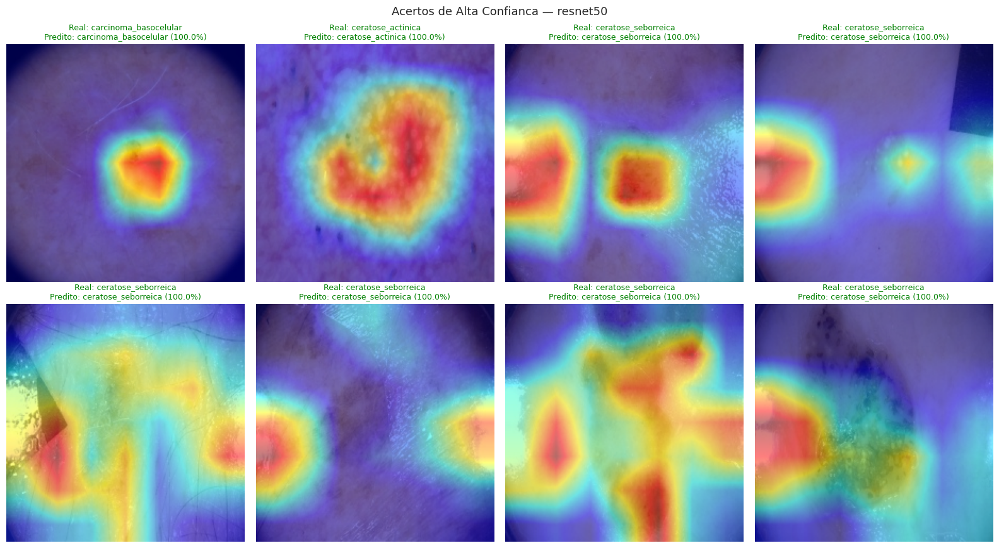

Salvo: /content/data/processed/gradcam/gradcam_acertos_de_alta_confianca_resnet50.png

--- Gerando Grad-CAM: Falsos Negativos de Melanoma (8 exemplos) ---


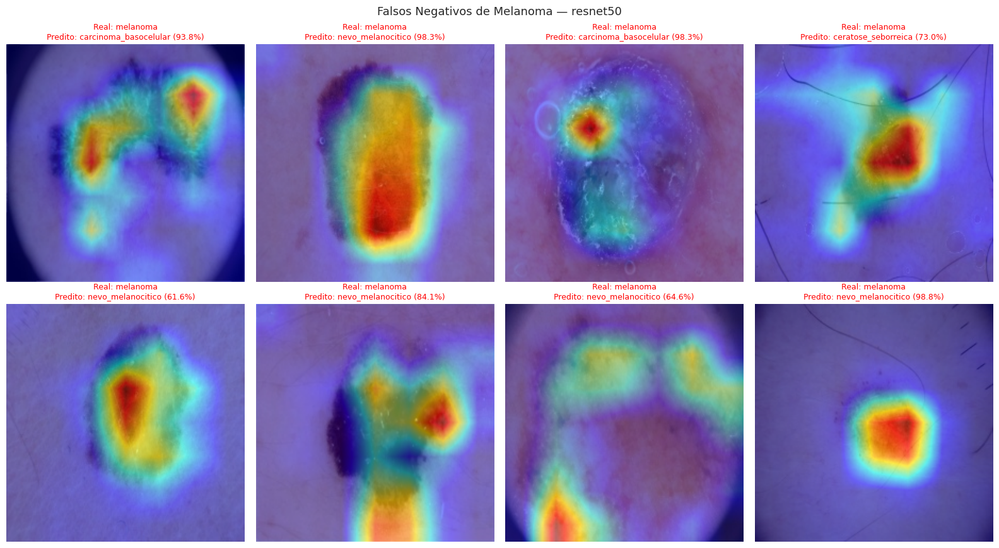

Salvo: /content/data/processed/gradcam/gradcam_falsos_negativos_de_melanoma_resnet50.png

--- Gerando Grad-CAM: Falsos Positivos de Melanoma (8 exemplos) ---


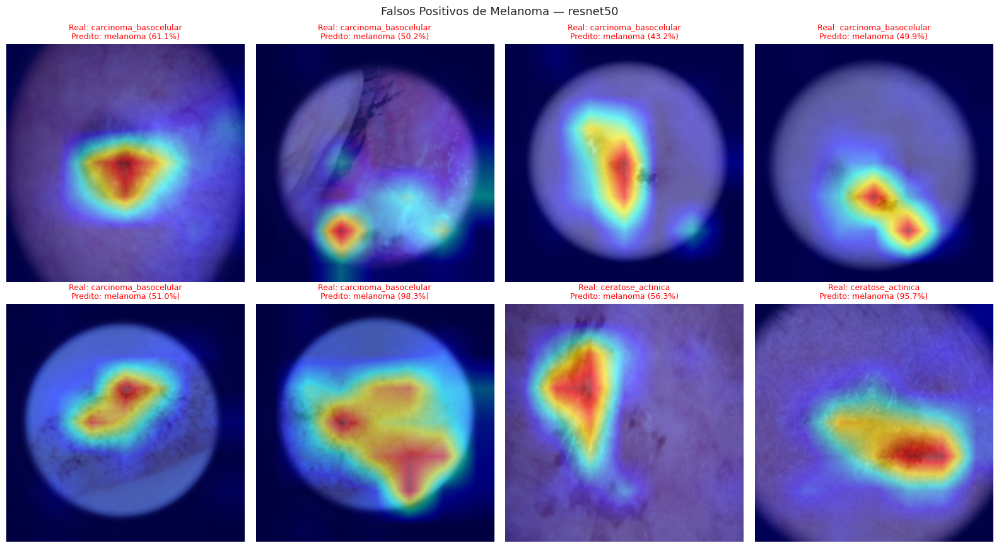

Salvo: /content/data/processed/gradcam/gradcam_falsos_positivos_de_melanoma_resnet50.png

--- Gerando Grad-CAM: Erros com Alta Confianca (geral) (8 exemplos) ---


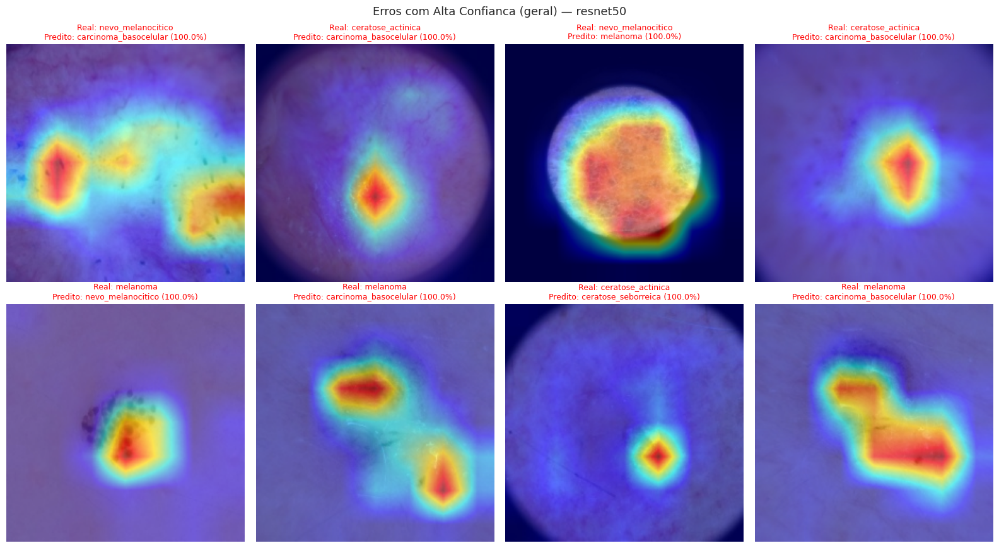

Salvo: /content/data/processed/gradcam/gradcam_erros_com_alta_confianca_(geral)_resnet50.png

[RESUMO CLÍNICO — resnet50] Falsos negativos de melanoma: 266/607 (43.8% dos melanomas reais foram classificados incorretamente como outra coisa)

Grad-CAM: efficientnet_b0
Coletando predições no conjunto de teste...
Selecionando grupos de análise qualitativa...

--- Gerando Grad-CAM: Acertos de Alta Confianca (8 exemplos) ---


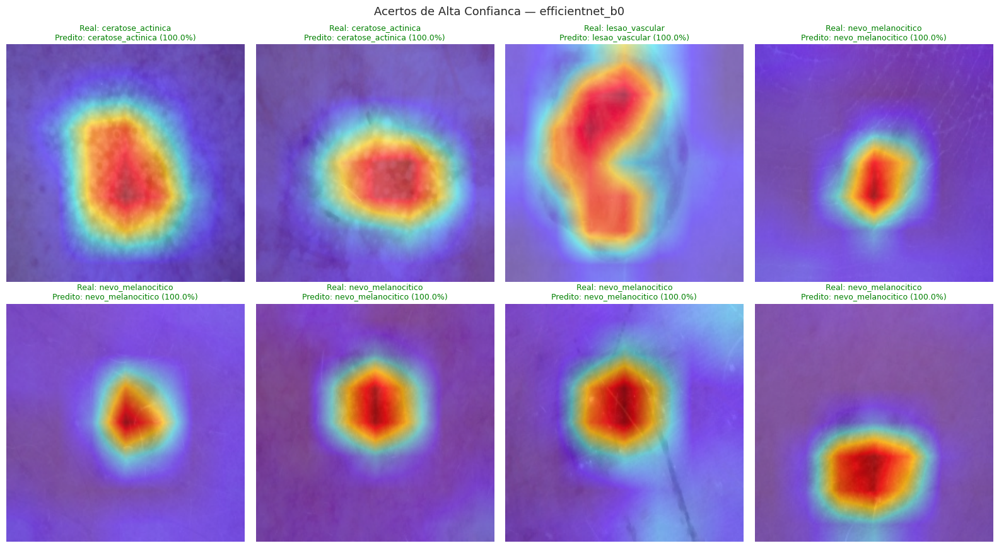

Salvo: /content/data/processed/gradcam/gradcam_acertos_de_alta_confianca_efficientnet_b0.png

--- Gerando Grad-CAM: Falsos Negativos de Melanoma (8 exemplos) ---


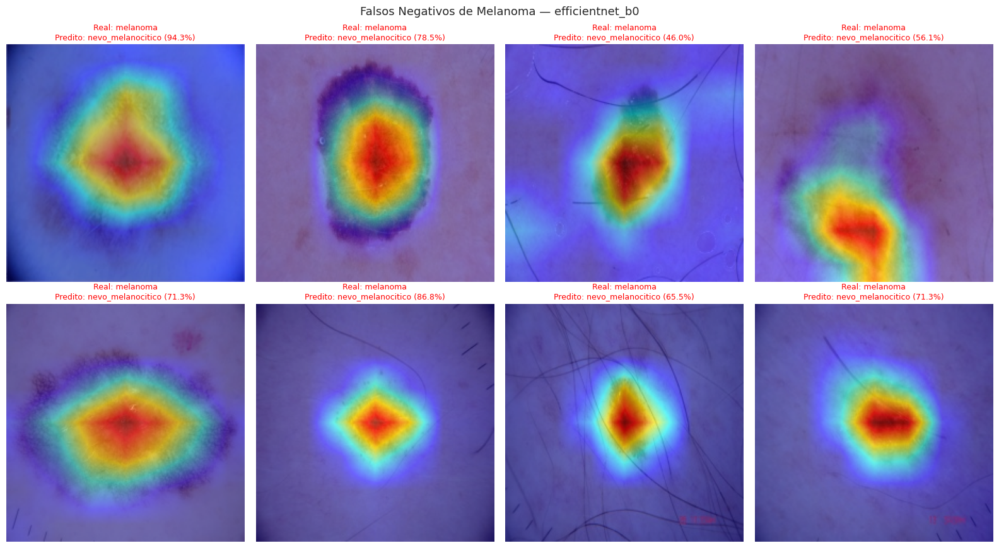

Salvo: /content/data/processed/gradcam/gradcam_falsos_negativos_de_melanoma_efficientnet_b0.png

--- Gerando Grad-CAM: Falsos Positivos de Melanoma (8 exemplos) ---


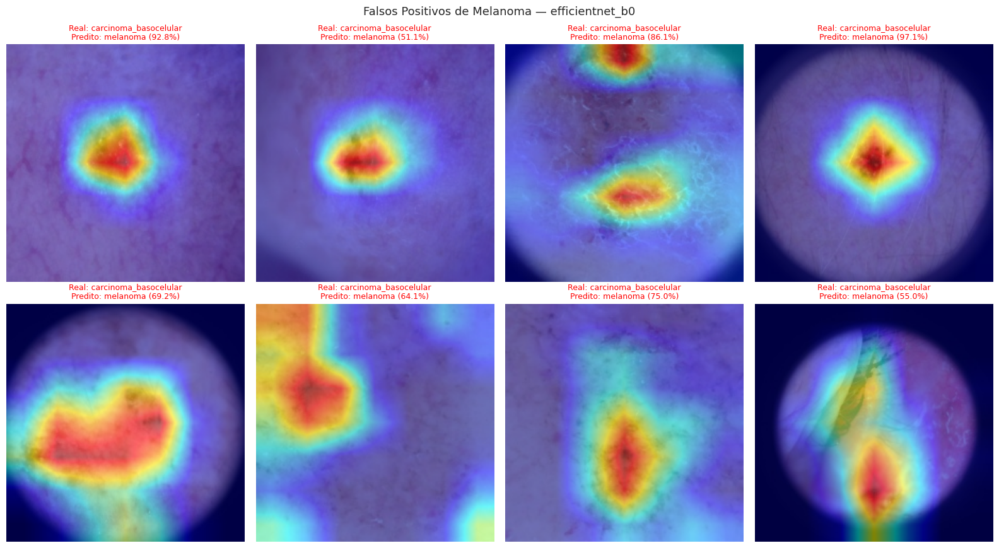

Salvo: /content/data/processed/gradcam/gradcam_falsos_positivos_de_melanoma_efficientnet_b0.png

--- Gerando Grad-CAM: Erros com Alta Confianca (geral) (8 exemplos) ---


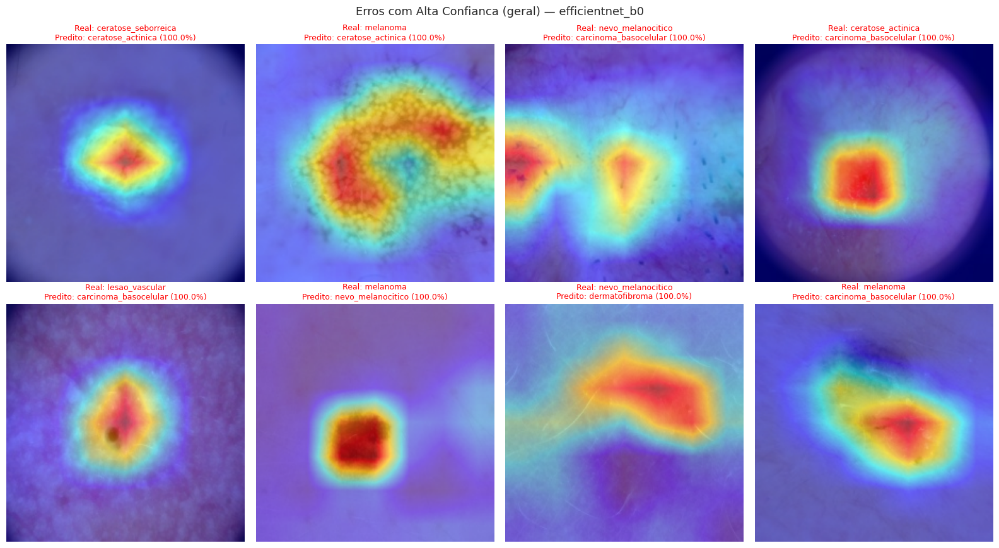

Salvo: /content/data/processed/gradcam/gradcam_erros_com_alta_confianca_(geral)_efficientnet_b0.png

[RESUMO CLÍNICO — efficientnet_b0] Falsos negativos de melanoma: 233/607 (38.4% dos melanomas reais foram classificados incorretamente como outra coisa)

ARQUIVOS GERADOS EM: /content/data/processed/gradcam
  - gradcam_acertos_de_alta_confianca_efficientnet_b0.png
  - gradcam_acertos_de_alta_confianca_resnet50.png
  - gradcam_erros_com_alta_confianca_(geral)_efficientnet_b0.png
  - gradcam_erros_com_alta_confianca_(geral)_resnet50.png
  - gradcam_falsos_negativos_de_melanoma_efficientnet_b0.png
  - gradcam_falsos_negativos_de_melanoma_resnet50.png
  - gradcam_falsos_positivos_de_melanoma_efficientnet_b0.png
  - gradcam_falsos_positivos_de_melanoma_resnet50.png


In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()
    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)

    if NOME_CLASSE_MELANOMA not in mapa_classes:
        print(f"[AVISO] Classe '{NOME_CLASSE_MELANOMA}' não encontrada em mapa_classes: "
              f"{list(mapa_classes.keys())}. Ajuste a variável NOME_CLASSE_MELANOMA no topo do script.")

    for arquitetura in ["resnet50", "efficientnet_b0"]:
        print("\n" + "=" * 60)
        print(f"Grad-CAM: {arquitetura}")
        print("=" * 60)

        modelo, camada_alvo = carregar_modelo_e_camada_alvo(arquitetura, num_classes)

        print("Coletando predições no conjunto de teste...")
        registros = coletar_predicoes_com_imagens(modelo, test_loader)

        print("Selecionando grupos de análise qualitativa...")
        grupos = selecionar_grupos_analise(registros, mapa_classes)

        for chave_grupo, titulo in [
            ("acertos_alta_confianca", "Acertos de Alta Confianca"),
            ("falsos_negativos_melanoma", "Falsos Negativos de Melanoma"),
            ("falsos_positivos_melanoma", "Falsos Positivos de Melanoma"),
            ("erros_alta_confianca", "Erros com Alta Confianca (geral)"),
        ]:
            print(f"\n--- Gerando Grad-CAM: {titulo} ({len(grupos[chave_grupo])} exemplos) ---")
            gerar_grade_gradcam(modelo, camada_alvo, grupos[chave_grupo],
                                  nomes_classes, titulo, arquitetura)

        # Resumo numérico da análise qualitativa
        n_fn_melanoma = len([
            r for r in registros
            if mapa_classes.get(NOME_CLASSE_MELANOMA) is not None
            and r["rotulo_verdadeiro"] == mapa_classes[NOME_CLASSE_MELANOMA]
            and r["predicao"] != mapa_classes[NOME_CLASSE_MELANOMA]
        ])
        n_total_melanoma = len([
            r for r in registros
            if mapa_classes.get(NOME_CLASSE_MELANOMA) is not None
            and r["rotulo_verdadeiro"] == mapa_classes[NOME_CLASSE_MELANOMA]
        ])

        if n_total_melanoma > 0:
            print(f"\n[RESUMO CLÍNICO — {arquitetura}] "
                  f"Falsos negativos de melanoma: {n_fn_melanoma}/{n_total_melanoma} "
                  f"({n_fn_melanoma/n_total_melanoma*100:.1f}% dos melanomas reais "
                  f"foram classificados incorretamente como outra coisa)")

        del modelo
        torch.cuda.empty_cache()

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_GRADCAM)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_GRADCAM)):
        print(f"  - {arquivo}")

### ANÁLISE DE EQUIDADE POR SUBGRUPO (idade, sexo)

Verifica se o desempenho do modelo é homogêneo entre diferentes subgrupos
demográficos, ou se há disparidades que precisam ser discutidas no TCC —
especialmente relevante dado que o próprio referencial teórico do trabalho
já identifica a sub-representação de certos perfis nas bases ISIC/HAM10000
(item 3.3 do método).

Cruza as predições do modelo (na mesma ordem do test.csv, já que o
DataLoader de teste usa shuffle=False) com os metadados demográficos
coletados na fase de EDA.

Pré-requisito: test.csv (de preprocessamento.py) precisa ter colunas de
idade e sexo — o script detecta automaticamente os nomes possíveis.

In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_EQUIDADE = os.path.join(SAIDA_BASE, "equidade")
os.makedirs(SAIDA_EQUIDADE, exist_ok=True)

In [ ]:
ARQUITETURAS = ["resnet50", "efficientnet_b0"]

# Limiar de disparidade: diferença de acurácia/sensibilidade entre subgrupos
# acima deste valor é sinalizada como potencialmente preocupante
LIMIAR_DISPARIDADE = 0.10  # 10 pontos percentuais

In [ ]:
# ============================================================
# CARREGAMENTO DO MODELO
# ============================================================
def carregar_modelo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES NA ORDEM EXATA DO test.csv
# (test_loader usa shuffle=False, então a ordem bate com o DataFrame)
# ============================================================
def coletar_predicoes_em_ordem(modelo, test_loader):
    todas_preds, todos_rotulos, todas_confiancas = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            saidas = modelo(imagens)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)
            confiancas = probs[np.arange(len(preds)), preds]

            todas_preds.extend(preds)
            todos_rotulos.extend(rotulos.numpy())
            todas_confiancas.extend(confiancas)

    return np.array(todas_preds), np.array(todos_rotulos), np.array(todas_confiancas)

In [ ]:
# ============================================================
# DETECÇÃO AUTOMÁTICA DAS COLUNAS DEMOGRÁFICAS
# ============================================================
def detectar_coluna(df, candidatos):
    for c in candidatos:
        if c in df.columns:
            return c
    return None

In [ ]:
def preparar_faixas_etarias(df, col_idade):
    """Agrupa idade em faixas clinicamente relevantes."""
    bins = [0, 20, 40, 60, 80, 150]
    labels = ["0-20", "21-40", "41-60", "61-80", "81+"]
    df["faixa_etaria"] = pd.cut(df[col_idade], bins=bins, labels=labels, right=True)
    return df

In [ ]:
# ============================================================
# CÁLCULO DE MÉTRICAS POR SUBGRUPO
# ============================================================
def calcular_metricas_por_subgrupo(df, coluna_subgrupo, nome_classe_melanoma, idx_melanoma):
    """
    Para cada valor do subgrupo (ex.: 'male'/'female', ou cada faixa etária),
    calcula acurácia geral e sensibilidade específica para melanoma.
    """
    linhas = []

    for valor_subgrupo, grupo in df.groupby(coluna_subgrupo, observed=True):
        if len(grupo) == 0:
            continue

        acuracia = (grupo["predicao"] == grupo["rotulo_verdadeiro"]).mean()

        if idx_melanoma is not None:
            grupo_melanoma_real = grupo[grupo["rotulo_verdadeiro"] == idx_melanoma]
            if len(grupo_melanoma_real) > 0:
                sensibilidade_melanoma = (
                    grupo_melanoma_real["predicao"] == idx_melanoma
                ).mean()
                n_melanoma = len(grupo_melanoma_real)
            else:
                sensibilidade_melanoma = np.nan
                n_melanoma = 0
        else:
            sensibilidade_melanoma = np.nan
            n_melanoma = 0

        linhas.append({
            "subgrupo": valor_subgrupo,
            "n_amostras_total": len(grupo),
            "n_amostras_melanoma": n_melanoma,
            "acuracia_geral": round(float(acuracia), 4),
            f"sensibilidade_{nome_classe_melanoma}": round(float(sensibilidade_melanoma), 4)
            if not np.isnan(sensibilidade_melanoma) else None,
            "confianca_media": round(float(grupo["confianca"].mean()), 4),
        })

    return pd.DataFrame(linhas)

In [ ]:
def sinalizar_disparidades(df_metricas, coluna_metrica, nome_subgrupo, arquitetura):
    """Verifica se a diferença entre o melhor e o pior subgrupo excede o limiar."""
    valores_validos = df_metricas[coluna_metrica].dropna()
    if len(valores_validos) < 2:
        print(f"  [AVISO] Dados insuficientes em '{nome_subgrupo}' para comparar disparidade em '{coluna_metrica}'.")
        return None

    maior = valores_validos.max()
    menor = valores_validos.min()
    diferenca = maior - menor

    subgrupo_maior = df_metricas.loc[df_metricas[coluna_metrica].idxmax(), "subgrupo"]
    subgrupo_menor = df_metricas.loc[df_metricas[coluna_metrica].idxmin(), "subgrupo"]

    if diferenca >= LIMIAR_DISPARIDADE:
        print(f"  [DISPARIDADE DETECTADA] {arquitetura} | {nome_subgrupo} | {coluna_metrica}: "
              f"{subgrupo_maior}={maior:.3f} vs. {subgrupo_menor}={menor:.3f} "
              f"(diferença de {diferenca:.3f}, acima do limiar de {LIMIAR_DISPARIDADE})")
    else:
        print(f"  [OK] {arquitetura} | {nome_subgrupo} | {coluna_metrica}: "
              f"diferença máxima de {diferenca:.3f} (dentro do limiar de {LIMIAR_DISPARIDADE})")

    return {
        "arquitetura": arquitetura,
        "subgrupo_analisado": nome_subgrupo,
        "metrica": coluna_metrica,
        "melhor_subgrupo": subgrupo_maior,
        "melhor_valor": round(float(maior), 4),
        "pior_subgrupo": subgrupo_menor,
        "pior_valor": round(float(menor), 4),
        "diferenca": round(float(diferenca), 4),
        "disparidade_relevante": bool(diferenca >= LIMIAR_DISPARIDADE),
    }

In [ ]:
# ============================================================
# VISUALIZAÇÃO
# ============================================================
def plotar_metricas_por_subgrupo(df_metricas, coluna_metrica, nome_subgrupo, arquitetura):
    plt.figure(figsize=(8, 5))
    df_plot = df_metricas.dropna(subset=[coluna_metrica])
    sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")
    plt.axhline(df_plot[coluna_metrica].mean(), color="red", linestyle="--",
                label=f"Média geral ({df_plot[coluna_metrica].mean():.3f})")
    plt.title(f"{coluna_metrica} por {nome_subgrupo} — {arquitetura}")
    plt.ylim(0, 1)
    plt.legend()
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    nome_arquivo = f"equidade_{nome_subgrupo}_{coluna_metrica}_{arquitetura}.png"
    caminho = os.path.join(SAIDA_EQUIDADE, nome_arquivo)
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"  Gráfico salvo em: {caminho}")

Carregando metadados do conjunto de teste...
Coluna de idade detectada: age_approx
Coluna de sexo detectada: sex

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Análise de equidade: resnet50

--- Equidade por sexo (sex) ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
  female              1613                  275          0.7068                  0.5418           0.8948
    male              1741                  313          0.7455                  0.5719           0.9004
  [OK] resnet50 | sexo | acuracia_geral: diferença máxima de 0.039 (dentro do limiar de 0.1)
  [OK] resnet50 | sexo | sensibilidade_melanoma: diferença máxima de 0.030 (dentro do limiar de 0.1)


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


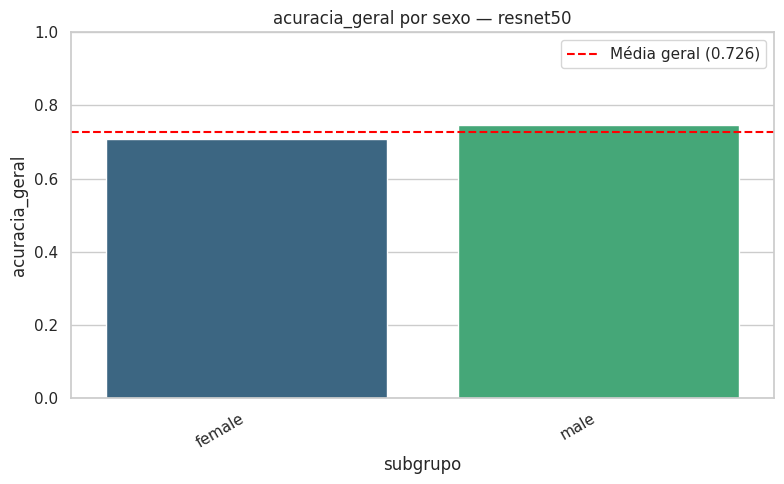

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_acuracia_geral_resnet50.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


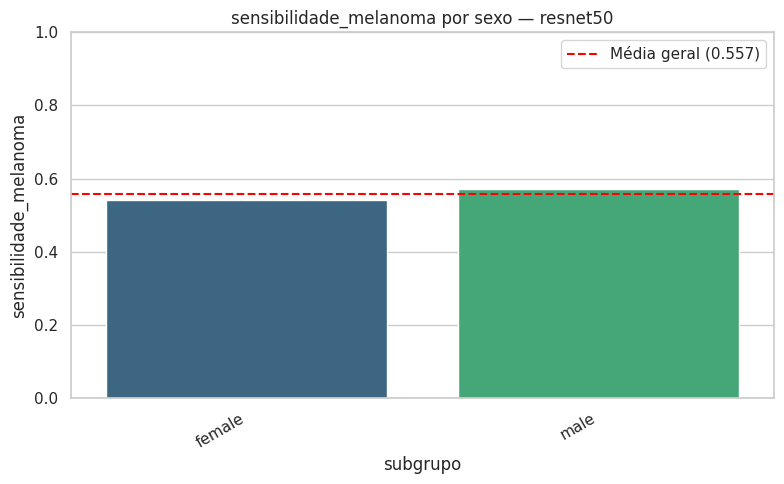

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_sensibilidade_melanoma_resnet50.png

--- Equidade por faixa etária ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
    0-20               126                    4          0.7937                  0.2500           0.9244
   21-40               788                   71          0.7246                  0.3803           0.9034
   41-60              1319                  218          0.7589                  0.5138           0.9056
   61-80               929                  249          0.6663                  0.6104           0.8804
     81+               176                   46          0.7614                  0.7826           0.8847
  [DISPARIDADE DETECTADA] resnet50 | faixa_etaria | acuracia_geral: 0-20=0.794 vs. 61-80=0.666 (diferença de 0.127, acima do limiar de 0.1)
  [DISPARIDADE DETECTADA] resnet50 | faixa_etaria | sensibilidade_melanoma: 81+=0.783 vs. 0-

/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


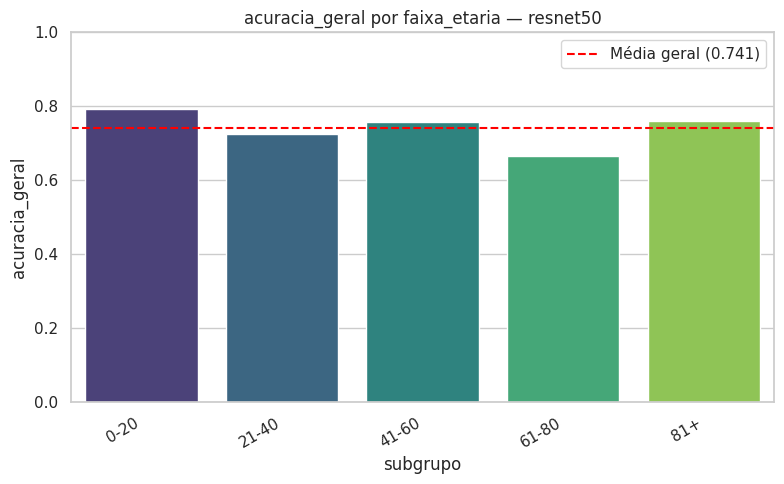

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_acuracia_geral_resnet50.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


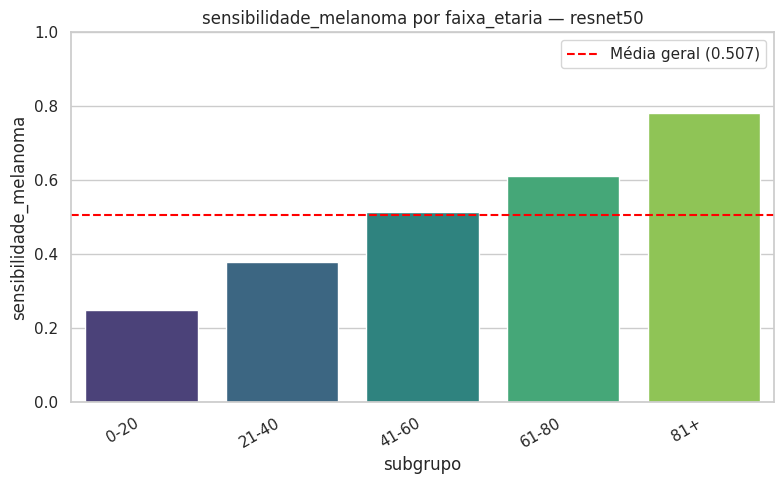

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_sensibilidade_melanoma_resnet50.png

Análise de equidade: efficientnet_b0

--- Equidade por sexo (sex) ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
  female              1613                  275          0.7390                  0.6036           0.8756
    male              1741                  313          0.7542                  0.6198           0.8810
  [OK] efficientnet_b0 | sexo | acuracia_geral: diferença máxima de 0.015 (dentro do limiar de 0.1)
  [OK] efficientnet_b0 | sexo | sensibilidade_melanoma: diferença máxima de 0.016 (dentro do limiar de 0.1)


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


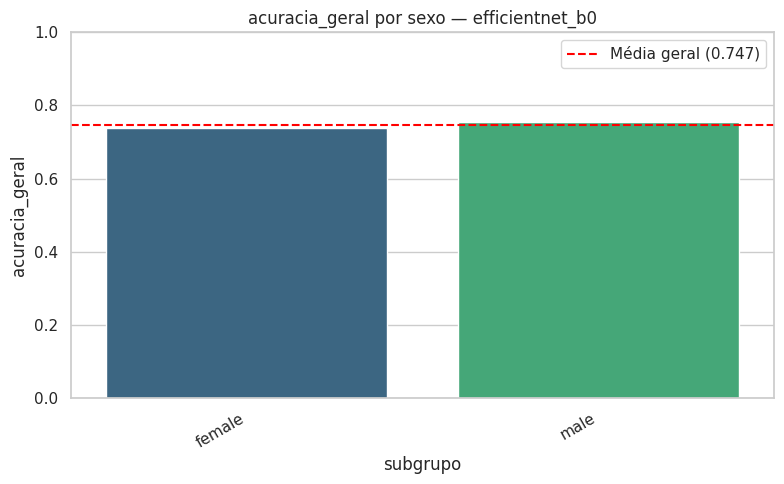

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_acuracia_geral_efficientnet_b0.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


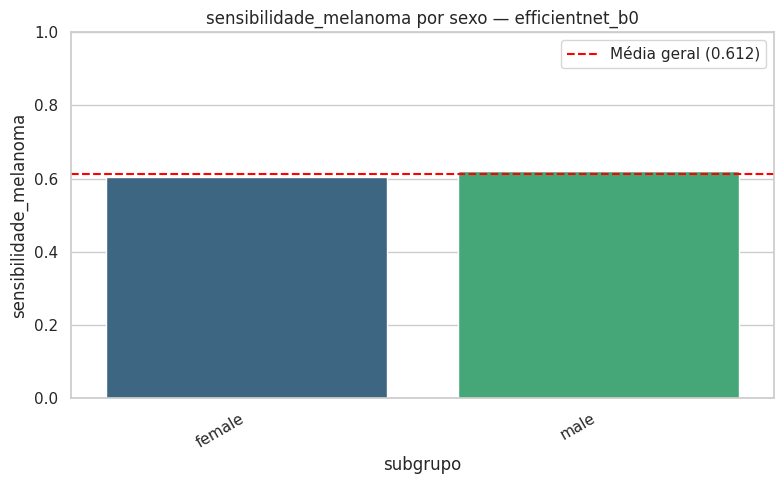

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_sensibilidade_melanoma_efficientnet_b0.png

--- Equidade por faixa etária ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
    0-20               126                    4          0.8651                  0.2500           0.9275
   21-40               788                   71          0.7513                  0.4507           0.8809
   41-60              1319                  218          0.7832                  0.5780           0.8830
   61-80               929                  249          0.6911                  0.6627           0.8655
     81+               176                   46          0.6477                  0.7826           0.8624
  [DISPARIDADE DETECTADA] efficientnet_b0 | faixa_etaria | acuracia_geral: 0-20=0.865 vs. 81+=0.648 (diferença de 0.217, acima do limiar de 0.1)
  [DISPARIDADE DETECTADA] efficientnet_b0 | faixa_etaria | sensibilidade_melanom

/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


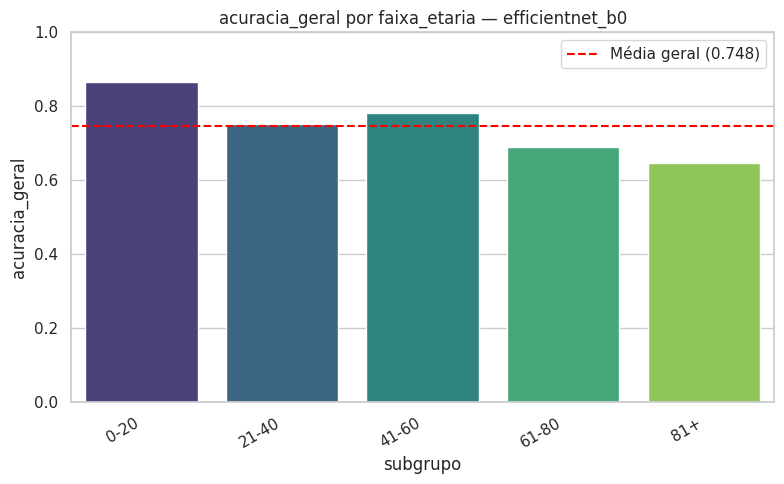

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_acuracia_geral_efficientnet_b0.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


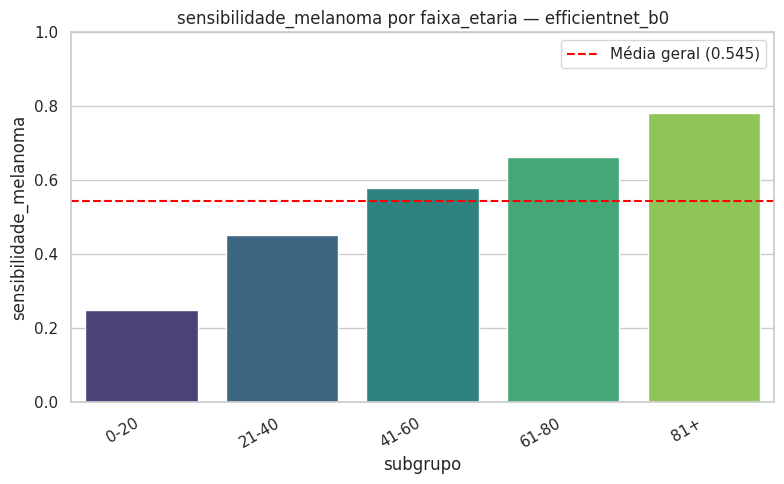

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_sensibilidade_melanoma_efficientnet_b0.png

RESUMO CONSOLIDADO DE DISPARIDADES ENTRE SUBGRUPOS
    arquitetura subgrupo_analisado                metrica melhor_subgrupo  melhor_valor pior_subgrupo  pior_valor  diferenca  disparidade_relevante
       resnet50               sexo         acuracia_geral            male        0.7455        female      0.7068     0.0387                  False
       resnet50               sexo sensibilidade_melanoma            male        0.5719        female      0.5418     0.0301                  False
       resnet50       faixa_etaria         acuracia_geral            0-20        0.7937         61-80      0.6663     0.1274                   True
       resnet50       faixa_etaria sensibilidade_melanoma             81+        0.7826          0-20      0.2500     0.5326                   True
efficientnet_b0               sexo         acuracia_geral            male        0.7542   

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando metadados do conjunto de teste...")
    df_test_meta = pd.read_csv(os.path.join(SAIDA_BASE, "test.csv"))

    col_idade = detectar_coluna(df_test_meta, ["idade", "age_approx", "age"])
    col_sexo = detectar_coluna(df_test_meta, ["sexo", "sex"])

    print(f"Coluna de idade detectada: {col_idade}")
    print(f"Coluna de sexo detectada: {col_sexo}")

    if col_idade is None and col_sexo is None:
        raise ValueError(
            "Nenhuma coluna de idade ou sexo encontrada em test.csv. "
            f"Colunas disponíveis: {df_test_meta.columns.tolist()}"
        )

    if col_idade:
        df_test_meta = preparar_faixas_etarias(df_test_meta, col_idade)

    print("\nCarregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()
    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)
    idx_melanoma = mapa_classes.get("melanoma")

    todas_disparidades = []

    for arquitetura in ARQUITETURAS:
        print("\n" + "=" * 60)
        print(f"Análise de equidade: {arquitetura}")
        print("=" * 60)

        modelo = carregar_modelo(arquitetura, num_classes)
        preds, rotulos, confiancas = coletar_predicoes_em_ordem(modelo, test_loader)

        # Confere que a quantidade bate com os metadados antes de juntar
        if len(preds) != len(df_test_meta):
            print(f"[ERRO] Quantidade de predições ({len(preds)}) difere da "
                  f"quantidade de linhas em test.csv ({len(df_test_meta)}). "
                  "Verifique se test.csv não foi alterado após gerar o DataLoader.")
            continue

        df_analise = df_test_meta.copy()
        df_analise["predicao"] = preds
        df_analise["rotulo_verdadeiro"] = rotulos
        df_analise["confianca"] = confiancas

        # --- Por sexo ---
        if col_sexo:
            print(f"\n--- Equidade por sexo ({col_sexo}) ---")
            df_metricas_sexo = calcular_metricas_por_subgrupo(
                df_analise, col_sexo, "melanoma", idx_melanoma
            )
            print(df_metricas_sexo.to_string(index=False))

            df_metricas_sexo.to_csv(
                os.path.join(SAIDA_EQUIDADE, f"metricas_sexo_{arquitetura}.csv"), index=False
            )

            disp = sinalizar_disparidades(df_metricas_sexo, "acuracia_geral", "sexo", arquitetura)
            if disp:
                todas_disparidades.append(disp)
            if idx_melanoma is not None:
                disp2 = sinalizar_disparidades(
                    df_metricas_sexo, "sensibilidade_melanoma", "sexo", arquitetura
                )
                if disp2:
                    todas_disparidades.append(disp2)

            plotar_metricas_por_subgrupo(df_metricas_sexo, "acuracia_geral", "sexo", arquitetura)
            if idx_melanoma is not None:
                plotar_metricas_por_subgrupo(
                    df_metricas_sexo, "sensibilidade_melanoma", "sexo", arquitetura
                )

        # --- Por faixa etária ---
        if col_idade:
            print(f"\n--- Equidade por faixa etária ---")
            df_metricas_idade = calcular_metricas_por_subgrupo(
                df_analise, "faixa_etaria", "melanoma", idx_melanoma
            )
            print(df_metricas_idade.to_string(index=False))

            df_metricas_idade.to_csv(
                os.path.join(SAIDA_EQUIDADE, f"metricas_idade_{arquitetura}.csv"), index=False
            )

            disp = sinalizar_disparidades(df_metricas_idade, "acuracia_geral", "faixa_etaria", arquitetura)
            if disp:
                todas_disparidades.append(disp)
            if idx_melanoma is not None:
                disp2 = sinalizar_disparidades(
                    df_metricas_idade, "sensibilidade_melanoma", "faixa_etaria", arquitetura
                )
                if disp2:
                    todas_disparidades.append(disp2)

            plotar_metricas_por_subgrupo(df_metricas_idade, "acuracia_geral", "faixa_etaria", arquitetura)
            if idx_melanoma is not None:
                plotar_metricas_por_subgrupo(
                    df_metricas_idade, "sensibilidade_melanoma", "faixa_etaria", arquitetura
                )

        del modelo
        torch.cuda.empty_cache()

    # ============================================================
    # RESUMO CONSOLIDADO DE DISPARIDADES
    # ============================================================
    print("\n" + "=" * 70)
    print("RESUMO CONSOLIDADO DE DISPARIDADES ENTRE SUBGRUPOS")
    print("=" * 70)
    df_disparidades = pd.DataFrame(todas_disparidades)
    if len(df_disparidades) > 0:
        print(df_disparidades.to_string(index=False))
        caminho_disp = os.path.join(SAIDA_EQUIDADE, "resumo_disparidades.csv")
        df_disparidades.to_csv(caminho_disp, index=False)
        print(f"\nResumo salvo em: {caminho_disp}")

        n_relevantes = df_disparidades["disparidade_relevante"].sum()
        print(f"\n{n_relevantes} de {len(df_disparidades)} comparações mostraram "
              f"disparidade acima do limiar de {LIMIAR_DISPARIDADE} "
              "— vale discutir essas no Capítulo 4/5 do TCC, cruzando com a "
              "limitação de representatividade da amostra já identificada no "
              "item 3.3 (Universo e Amostra).")
    else:
        print("Nenhuma disparidade calculada (verifique se as colunas demográficas existem).")

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_EQUIDADE)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_EQUIDADE)):
        print(f"  - {arquivo}")

### EMPACOTAR RESULTADOS PARA DOWNLOAD

Gera um .zip com todas as figuras, tabelas e JSONs (sem checkpoints nem imagens).

In [ ]:
# ============================================================
# EMPACOTAR RESULTADOS (figuras, tabelas, JSONs) PARA DOWNLOAD
# Não inclui checkpoints (.pt) nem as imagens processadas.
# ============================================================
import shutil

def empacotar_resultados(nome_zip="/content/resultados_tcc"):
    pasta = "/content/resultados_tcc_pasta"
    shutil.rmtree(pasta, ignore_errors=True)
    os.makedirs(pasta, exist_ok=True)

    extensoes = (".png", ".csv", ".json")
    for raiz, dirs, arquivos in os.walk(SAIDA_BASE):
        # pula as pastas de imagens processadas (train/val/test e sem_dullrazor)
        dirs[:] = [d for d in dirs if d not in ("train", "val", "test", SUBPASTA_SEM_DR)]
        for arq in arquivos:
            if arq.lower().endswith(extensoes) and not arq.startswith(("train", "val", "test", "dataset_limpo")):
                rel = os.path.relpath(raiz, SAIDA_BASE)
                destino = os.path.join(pasta, rel)
                os.makedirs(destino, exist_ok=True)
                shutil.copy2(os.path.join(raiz, arq), destino)

    caminho = shutil.make_archive(nome_zip, "zip", pasta)
    print(f"Arquivo gerado: {caminho} ({os.path.getsize(caminho) / 1e6:.1f} MB)")
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print("(fora do Colab: baixe o arquivo manualmente)")

if __name__ == "__main__":
    empacotar_resultados()

Arquivo gerado: /content/resultados_tcc.zip (30.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>